# SC 663 402 Data Warehouse and Big Data Analytics
## แบบฝึกทบทวน pandas

**ผู้สอน:** อ.ดร.พิชญา วิรัชโชติเสถียร (Pitchaya Wiratchotisatian)
**ภาควิชาสถิติ คณะวิทยาศาสตร์ มหาวิทยาลัยขอนแก่น**

---

### วัตถุประสงค์

การบ้านชุดนี้มีวัตถุประสงค์เพื่อทบทวนความรู้ pandas ที่นักศึกษาเคยศึกษามาแล้ว ให้อยู่ในระดับที่พร้อมสำหรับการวิเคราะห์ข้อมูลขนาดใหญ่ในรายวิชานี้
เนื้อหาครอบคลุมตั้งแต่โครงสร้างข้อมูลพื้นฐาน การเลือกและกรองข้อมูล การสรุปข้อมูลด้วย `groupby` การรวมตารางหลายตาราง จนถึงการสร้างกราฟจาก DataFrame

### รูปแบบ

แต่ละหัวข้อประกอบด้วยสองส่วน

1. **ตัวอย่าง** เป็นเซลล์โค้ดที่รันได้ทันที มีไว้เพื่อทบทวนรูปแบบการเรียกใช้คำสั่ง นักศึกษาควรรันและสังเกตผลลัพธ์ก่อนทำโจทย์
2. **โจทย์** เป็นแบบฝึกหัดที่มีระดับความยากสูงกว่าตัวอย่าง ไม่มีเฉลย นักศึกษาต้องเขียนคำตอบเองในเซลล์ที่เตรียมไว้

### ข้อกำหนดในการทำและการส่ง

1. เขียนคำตอบในเซลล์ที่เตรียมไว้ใต้โจทย์แต่ละข้อ
2. โจทย์ที่ระบุคำว่า **อธิบาย** ต้องตอบเป็นข้อความ การส่งเฉพาะโค้ดจะไม่ได้คะแนนในส่วนนั้น
3. ห้ามกำหนดคำตอบเป็นค่าคงที่ ทุกตัวเลขที่รายงานต้องคำนวณจากข้อมูล
4. ให้เขียนโปรแกรมในรูปแบบ vectorized เป็นหลัก หากจำเป็นต้องใช้การวนซ้ำทีละแถว ให้ระบุเหตุผลกำกับ
5. ก่อนส่งให้เลือกคำสั่ง Restart & Run All และตรวจสอบว่าไฟล์ทำงานได้ตลอดทั้งไฟล์
6. ส่งไฟล์ในรูปแบบ `.ipynb` ด้วยลิ้งก์ใน GitHub ของตนเอง

### เกณฑ์การประเมิน

* ความเรียบร้อย ครบถ้วน และความสามารถในการรันซ้ำได้

---
## ส่วนที่ 0 import libraries และ เตรียมข้อมูล

ชุดข้อมูลที่ใช้ประกอบด้วย 3 ตาราง ได้แก่ ข้อมูลสภาพอากาศรายวัน ข้อมูลเมือง และข้อมูลภูมิภาค
ให้รันเซลล์ต่อไปนี้เพื่อโหลดข้อมูลก่อนเริ่มทำการบ้าน

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  fonts-tlwg-garuda fonts-tlwg-garuda-ttf fonts-tlwg-kinnari
  fonts-tlwg-kinnari-ttf fonts-tlwg-laksaman fonts-tlwg-laksaman-ttf
  fonts-tlwg-loma fonts-tlwg-loma-ttf fonts-tlwg-mono fonts-tlwg-mono-ttf
  fonts-tlwg-norasi fonts-tlwg-norasi-ttf fonts-tlwg-purisa
  fonts-tlwg-purisa-ttf fonts-tlwg-sawasdee fonts-tlwg-sawasdee-ttf
  fonts-tlwg-typewriter fonts-tlwg-typewriter-ttf fonts-tlwg-typist
  fonts-tlwg-typist-ttf fonts-tlwg-typo fonts-tlwg-typo-ttf fonts-tlwg-umpush
  fonts-tlwg-umpush-ttf fonts-tlwg-waree fonts-tlwg-waree-ttf
The following NEW packages will be installed:
  fonts-thai-tlwg fonts-tlwg-garuda fonts-tlwg-garuda-ttf fonts-tlwg-kinnari
  fonts-tlwg-kinnari-ttf fonts-tlwg-laksaman fonts-tlwg-laksaman-ttf
  fonts-tlwg-loma fonts-tlwg-loma-ttf fonts-tlwg-mono fonts-tlwg-mono-ttf
  fonts-tlwg-norasi fonts-tlwg-norasi-ttf fo

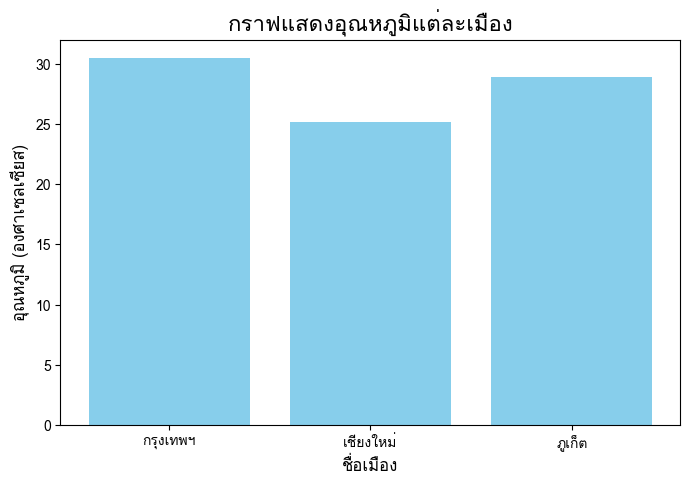

In [1]:
import pandas as pd
import numpy as np
import os, shutil
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns

# 1. ติดตั้งฟอนต์ภาษาไทย
!apt-get -y install fonts-thai-tlwg

# 2. ล้าง cache ของ matplotlib เพื่ออัปเดตฟอนต์ใหม่
cache_dir = matplotlib.get_cachedir()
if os.path.exists(cache_dir):
    shutil.rmtree(cache_dir)

# 3. ลงทะเบียนฟอนต์ใหม่เข้ากับ FontManager
font_path = '/usr/share/fonts/truetype/tlwg/Loma.ttf'
if os.path.exists(font_path):
    fm.fontManager.addfont(font_path)

# 4. ตั้งค่าฟอนต์หลัก
plt.rcParams['font.family'] = 'Loma'
plt.rcParams['axes.unicode_minus'] = False

# 5. สร้างข้อมูลจำลองและแสดงผล
data = {
    'เมือง': ['กรุงเทพฯ', 'เชียงใหม่', 'ภูเก็ต'],
    'อุณหภูมิ': [30.5, 25.2, 28.9]
}
df_thai = pd.DataFrame(data)

print("ตั้งค่าระบบฟอนต์ภาษาไทยสำเร็จ!")

plt.figure(figsize=(8, 5))
plt.bar(df_thai['เมือง'], df_thai['อุณหภูมิ'], color='skyblue')
plt.title('กราฟแสดงอุณหภูมิแต่ละเมือง', fontsize=16)
plt.xlabel('ชื่อเมือง', fontsize=12)
plt.ylabel('อุณหภูมิ (องศาเซลเซียส)', fontsize=12)
plt.show()

In [2]:
import pandas as pd
import numpy as np

BASE = ("https://raw.githubusercontent.com/PitchayaW/"
        "SC-612-104-Essential-Data-Science/refs/heads/main/Module-A-Notebooks/Dataset/")

df = pd.read_csv(BASE + "world_weather_sample.csv")
city_info = pd.read_csv(BASE + "city_info.csv")
region_info = pd.read_csv(BASE + "region_info.csv")

print("weather:", df.shape, " city_info:", city_info.shape, " region_info:", region_info.shape)
df.head()

weather: (2075, 10)  city_info: (23, 5)  region_info: (6, 3)


,record_id,date,city,country,region,temperature_c,humidity_pct,rainfall_mm,wind_speed_kmh,pressure_hpa
0,983,2025-03-24,New York,USA,North America,15.7,72.6,6.3,15.9,1005.4
1,220,2025-02-09,Tokyo,Japan,Asia,18.3,60.6,0.0,20.5,1015.1
2,1022,2025-02-01,Los Angeles,USA,North America,20.6,46.8,1.2,8.6,1013.5
3,469,2025-01-19,Mumbai,India,Asia,31.0,73.4,8.0,11.8,1000.1
4,1834,2025-02-03,Cape Town,South Africa,Africa,19.1,55.0,0.0,16.6,1015.1


---
## ข้อ 1 การเปรียบเทียบคำสั่งที่มีลักษณะใกล้เคียงกัน

**คำสั่ง:** ให้นักศึกษารันเซลล์โค้ดทั้ง 6 เซลล์ต่อไปนี้ สังเกตผลลัพธ์ที่ได้ แล้วอธิบายกับตนเองให้เข้าใจความแตกต่างของคำสั่งในแต่ละเซลล์ พร้อมระบุว่าในทางปฏิบัติควรเลือกใช้คำสั่งใดในสถานการณ์ใด

การอธิบายควรครอบคลุมทั้ง **ชนิดของผลลัพธ์** **รูปร่างของผลลัพธ์** และ **ความหมายของค่าที่ได้**

In [3]:
# เซลล์ 1.1
s = pd.Series([10, 20, 30], index=["a", "b", "c"])
print(s["a"])
print(s.iloc[0])
print(s[["a", "c"]])

10
10
a    10
c    30
dtype: int64


In [4]:
# เซลล์ 1.2
print(type(df["city"]), df["city"].shape)
print(type(df[["city"]]), df[["city"]].shape)

<class 'pandas.core.series.Series'> (2075,)
<class 'pandas.core.frame.DataFrame'> (2075, 1)


In [5]:
# เซลล์ 1.3
print(df.loc[0:3].shape)
print(df.iloc[0:3].shape)

(4, 10)
(3, 10)


In [6]:
# เซลล์ 1.4
print(df.groupby("city")["temperature_c"].count().head(3))
print(df.groupby("city").size().head(3))

city
Auckland    90
Bangkok     91
Beijing     89
Name: temperature_c, dtype: int64
city
Auckland    90
Bangkok     91
Beijing     90
dtype: int64


In [7]:
# เซลล์ 1.5
print(df.groupby("city")["temperature_c"].mean().head(3))
print(df.groupby("city")[["temperature_c"]].mean().head(3))

city
Auckland    17.804444
Bangkok     32.453846
Beijing     15.598876
Name: temperature_c, dtype: float64
          temperature_c
city                   
Auckland      17.804444
Bangkok       32.453846
Beijing       15.598876


In [8]:
# เซลล์ 1.6
a = pd.Series([1, 2, 3], index=["x", "y", "z"])
b = pd.Series([10, 20, 30], index=["z", "y", "x"])
print(a + b)
print(a.to_numpy() + b.to_numpy())

x    31
y    22
z    13
dtype: int64
[11 22 33]


---
## ข้อ 2 Series และ DataFrame

### ตัวอย่าง

In [9]:
# การสร้าง DataFrame จากโครงสร้างข้อมูลสองรูปแบบ
d1 = pd.DataFrame({"city": ["Bangkok", "Tokyo"], "temp": [30.5, 16.2]})
d2 = pd.DataFrame([{"city": "Bangkok", "temp": 30.5}, {"city": "Tokyo", "temp": 16.2}])
print(d1.equals(d2))

# การเข้าถึงองค์ประกอบของ DataFrame
print(df.columns.tolist())
print(df.index[:5].tolist())
print(df["temperature_c"].nlargest(3).tolist())

True
['record_id', 'date', 'city', 'country', 'region', 'temperature_c', 'humidity_pct', 'rainfall_mm', 'wind_speed_kmh', 'pressure_hpa']
[0, 1, 2, 3, 4]
[999.0, 999.0, 999.0]


### โจทย์ 2.1
สร้าง Series ชื่อ `rain_by_city` ซึ่งเก็บปริมาณฝนรวมของแต่ละเมือง โดยกำหนดให้ index เป็นชื่อเมือง จากนั้นตอบคำถามต่อไปนี้ด้วยโปรแกรม

1. เมืองที่มีปริมาณฝนรวมสูงสุด 3 อันดับแรก
2. สัดส่วนปริมาณฝนของแต่ละเมืองเทียบกับปริมาณฝนรวมทั้งหมด แสดงเป็นร้อยละทศนิยม 2 ตำแหน่ง
3. จำนวนเมืองที่มีปริมาณฝนรวมสูงกว่าค่าเฉลี่ยของทุกเมือง

In [10]:
# คำตอบข้อ 2.1
rain_by_city = pd.Series(df.groupby("city")["rainfall_mm"].sum())
rain_by_city.head(3)

,rainfall_mm
city,
Auckland,351.9
Bangkok,685.6
Beijing,250.1


In [11]:
rain_prop = rain_by_city / rain_by_city.sum() * 100
for city, prop in rain_prop.items():
    print(f"{city} city : {prop:.2f}%")

Auckland city : 4.22%
Bangkok city : 8.21%
Beijing city : 3.00%
Berlin city : 3.21%
Buenos Aires city : 3.65%
Cairo city : 1.47%
Cape Town city : 2.87%
Chiang Mai city : 5.22%
Lagos city : 7.82%
Lima city : 2.16%
London city : 3.27%
Los Angeles city : 2.03%
Mexico City city : 3.66%
Moscow city : 2.96%
Mumbai city : 5.84%
Nairobi city : 4.74%
New York city : 3.78%
Paris city : 3.99%
Sao Paulo city : 5.07%
Singapore city : 10.43%
Sydney city : 3.97%
Tokyo city : 4.61%
Toronto city : 3.81%


In [12]:
rain_city = rain_by_city[rain_by_city > rain_by_city.mean()]
print(f"{len(rain_city)} city")

8 city


### โจทย์ 2.2
สร้าง DataFrame ชื่อ `city_profile` ที่มีหนึ่งแถวต่อหนึ่งเมือง ประกอบด้วยคอลัมน์
`city`, `country`, `region`, `n_records`, `avg_temp`, `total_rain`
โดยกำหนดให้ใช้ `groupby`

In [13]:
# คำตอบข้อ 2.2
city_profile = df.groupby("city").agg(
    country=("country", "first"),
    region=("region", "first"),
    n_records=("temperature_c", "count"),
    avg_temp=("temperature_c", "mean"),
    total_rain=("rainfall_mm", "sum"))
city_profile.head()

,country,region,n_records,avg_temp,total_rain
city,,,,,
Auckland,New Zealand,Oceania,90,17.804444,351.9
Bangkok,Thailand,Asia,91,32.453846,685.6
Beijing,China,Asia,89,15.598876,250.1
Berlin,Germany,Europe,89,12.383146,268.4
Buenos Aires,Argentina,South America,89,19.171910,305.1


---
## ข้อ 3 การนำเข้าข้อมูลด้วย `read_csv()`

### ตัวอย่าง

In [14]:
# พารามิเตอร์ที่ใช้บ่อย ได้แก่ usecols, nrows, parse_dates, dtype, na_values
preview = pd.read_csv(
    BASE + "world_weather_sample.csv",
    usecols=["city", "date", "temperature_c"],
    parse_dates=["date"],
    nrows=5,
)
print(preview.dtypes)
preview

date             datetime64[ns]
city                     object
temperature_c           float64
dtype: object


,date,city,temperature_c
0,2025-03-24,New York,15.7
1,2025-02-09,Tokyo,18.3
2,2025-02-01,Los Angeles,20.6
3,2025-01-19,Mumbai,31.0
4,2025-02-03,Cape Town,19.1


In [15]:
# การอ่านข้อมูลทีละก้อนด้วย chunksize ซึ่งคืนค่าเป็น iterator
total_rows = 0
for chunk in pd.read_csv(BASE + "world_weather_sample.csv", chunksize=500):
    total_rows += len(chunk)
print("จำนวนแถวรวม:", total_rows)

จำนวนแถวรวม: 2075


### โจทย์ 3.1
เขียนคำสั่ง `pd.read_csv()` เพียงคำสั่งเดียวที่ดำเนินการทุกข้อต่อไปนี้ให้เสร็จสิ้นตั้งแต่ขั้นตอนการนำเข้า

1. อ่านเฉพาะคอลัมน์ `date`, `city`, `region`, `temperature_c`, `humidity_pct`, `rainfall_mm`
2. แปลงคอลัมน์ `date` เป็นชนิด datetime
3. กำหนดให้ค่า `999` และ `-999` ถูกอ่านเป็นค่าว่าง
4. กำหนดชนิดข้อมูลของ `city` และ `region` เป็น `category`
5. กำหนดให้ `city` เป็น index

ให้ตรวจสอบผลด้วย `.dtypes` และ `.info()`

In [16]:
rain_read_csv = pd.read_csv(
    BASE + "world_weather_sample.csv",
    usecols=["date", "city", "region", "temperature_c", "humidity_pct", "rainfall_mm"],
    parse_dates=["date"],
    na_values=[999, -999],
    dtype={"city": "category", "region": "category"},
    index_col="city",)

print(rain_read_csv.dtypes)
print(rain_read_csv.info())

date             datetime64[ns]
region                 category
temperature_c           float64
humidity_pct            float64
rainfall_mm             float64
dtype: object
<class 'pandas.core.frame.DataFrame'>
CategoricalIndex: 2075 entries, New York to Paris
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date           2075 non-null   datetime64[ns]
 1   region         2075 non-null   category      
 2   temperature_c  2052 non-null   float64       
 3   humidity_pct   1993 non-null   float64       
 4   rainfall_mm    2013 non-null   float64       
dtypes: category(1), datetime64[ns](1), float64(3)
memory usage: 69.8 KB
None


### โจทย์ 3.2
เปรียบเทียบปริมาณหน่วยความจำที่ใช้ระหว่างตารางที่นำเข้าตามปกติกับตารางจากโจทย์ 3.1 ด้วย `.memory_usage(deep=True)`
รายงานผลเป็นร้อยละที่ลดลง และ **อธิบาย** ว่าคอลัมน์ใดมีผลต่อการลดลงมากที่สุด เพราะเหตุใด

In [17]:
# คำตอบข้อ 3.2
rain_default = pd.read_csv(BASE + "world_weather_sample.csv")

mem_default = rain_default.memory_usage(deep=True)
mem_optimized = rain_read_csv.memory_usage(deep=True)
total_default = mem_default.sum()
total_optimized = mem_optimized.sum()
pct_reduction = (1 - total_optimized / total_default) * 100
print(f"หน่วยความจำแบบปกติ : {total_default:,}")
print(f"หน่วยความจำจากโจทย์ : {total_optimized:,}")
print(f"ลดลง : {pct_reduction:.2f}%")

print("\nเปรียบเทียบรายคอลัมน์:")
print(pd.DataFrame({
    "default": mem_default,
    "optimized": mem_optimized}))

หน่วยความจำแบบปกติ : 571,645
หน่วยความจำจากโจทย์ : 72,917
ลดลง : 87.24%

เปรียบเทียบรายคอลัมน์:
                default  optimized
Index               132     3927.0
city             116920        NaN
country          114937        NaN
date             122425    16600.0
humidity_pct      16600    16600.0
pressure_hpa      16600        NaN
rainfall_mm       16600    16600.0
record_id         16600        NaN
region           117631     2590.0
temperature_c     16600    16600.0
wind_speed_kmh    16600        NaN


**คำอธิบาย** city และ region คือคอลัมน์ที่ทำให้เปอร์เซ็นต์การลดหน่วยความจำสูงที่สุด เพราะเป็น low-cardinality string columns ที่ได้ประโยชน์เต็มที่จากการแปลงเป็น category dtype ซึ่งเปลี่ยนวิธีเก็บข้อมูลจาก string ซ้ำเต็มรูปแบบทุกแถว เป็นรหัสจำนวนเต็มขนาดเล็กกับตารางค่าที่ไม่ซ้ำ

### โจทย์ 3.3
ใช้การอ่านข้อมูลแบบ `chunksize` เพื่อคำนวณค่าต่อไปนี้ โดยห้ามโหลดข้อมูลทั้งไฟล์เข้าหน่วยความจำพร้อมกัน และห้ามใช้ `pd.concat`

1. อุณหภูมิสูงสุดและต่ำสุดของทั้งไฟล์
2. อุณหภูมิเฉลี่ยรายเมือง

**อธิบาย:** เหตุใดการนำค่าเฉลี่ยของแต่ละก้อนมาเฉลี่ยกันอีกครั้งจึงให้ผลไม่ถูกต้อง และควรสะสมค่าใดแทนจึงจะได้ผลที่ถูกต้อง

In [18]:
# คำตอบข้อ 3.3
chunk_size = 1000
global_max_temp = -np.inf
global_min_temp = np.inf
# ตัวแปรสะสมสำหรับค่าเฉลี่ยรายเมือง: เก็บผลรวม (sum) และจำนวน (count) ต่อเมือง
city_temp_sum = {}
city_temp_count = {}

for chunk in pd.read_csv(
    BASE + "world_weather_sample.csv",
    usecols=["city", "temperature_c"],
    chunksize=chunk_size):
    chunk = chunk.dropna(subset=["temperature_c"])
    chunk_max = chunk["temperature_c"].max()
    chunk_min = chunk["temperature_c"].min()
    global_max_temp = max(global_max_temp, chunk_max)
    global_min_temp = min(global_min_temp, chunk_min)
    grouped = chunk.groupby("city")["temperature_c"].agg(["sum", "count"])

    for city, row in grouped.iterrows():
        city_temp_sum[city] = city_temp_sum.get(city, 0) + row["sum"]
        city_temp_count[city] = city_temp_count.get(city, 0) + row["count"]
city_avg_temp = pd.Series({city: city_temp_sum[city] / city_temp_count[city]
                           for city in city_temp_sum}).sort_values(ascending=False)

print(f"อุณหภูมิสูงสุดทั้งไฟล์: {global_max_temp:.2f} องศา")
print(f"อุณหภูมิต่ำสุดทั้งไฟล์: {global_min_temp:.2f} องศา")
print("\nอุณหภูมิเฉลี่ยรายเมือง:")
print(city_avg_temp)

อุณหภูมิสูงสุดทั้งไฟล์: 999.00 องศา
อุณหภูมิต่ำสุดทั้งไฟล์: -88.00 องศา

อุณหภูมิเฉลี่ยรายเมือง:
Singapore       40.083333
Bangkok         32.453846
Mumbai          30.872222
Cape Town       30.162921
Chiang Mai      29.680220
Lagos           29.494253
Cairo           26.089888
Paris           25.811236
Sao Paulo       22.841573
Lima            21.490000
Nairobi         21.440000
Los Angeles     20.657303
Sydney          20.347778
Mexico City     19.187778
Buenos Aires    19.171910
Tokyo           18.414773
Auckland        17.804444
Beijing         15.598876
New York        15.476667
London          13.490909
Berlin          12.383146
Toronto         11.613636
Moscow           7.233333
dtype: float64


**คำอธิบาย** ไม่ควรสะสมค่าเฉลี่ยของแต่ละ chunk ถ้าคำนวณค่าเฉลี่ยของแต่ละ chunk แล้วนำค่าเฉลี่ยเหล่านั้นมาเฉลี่ยกันอีกครั้ง จะทำให้น้ำหนักเท่ากันกับทุก chunk โดยไม่คำนึงถึงจำนวนแถวในแต่ละ chunk ควรสะสม sum และ count ของแต่ละเมือง แล้วนำผลรวมทั้งหมดหารด้วยจำนวนข้อมูลทั้งหมดเมื่ออ่านครบทุก chunk

**อธิบายว่าทำไมต้องใช้ลูป** จำเป็นต้องใช้ลูประดับก้อนข้อมูล เพราะ pd.read_csv(..., chunksize=1000) ส่งข้อมูลมาเป็น DataFrame ทีละก้อน เราจึงต้องประมวลผลแต่ละก้อนและสะสมผลลัพธ์โดยไม่โหลดทั้งไฟล์เข้าหน่วยความจำ

---
## ข้อ 4 การสำรวจข้อมูลและการตรวจสอบคุณภาพข้อมูล

### ตัวอย่าง

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075 entries, 0 to 2074
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   record_id       2075 non-null   int64  
 1   date            2075 non-null   object 
 2   city            2075 non-null   object 
 3   country         2075 non-null   object 
 4   region          2075 non-null   object 
 5   temperature_c   2055 non-null   float64
 6   humidity_pct    1993 non-null   float64
 7   rainfall_mm     2013 non-null   float64
 8   wind_speed_kmh  2034 non-null   float64
 9   pressure_hpa    2043 non-null   float64
dtypes: float64(5), int64(1), object(4)
memory usage: 162.2+ KB


In [20]:
print(df.describe().round(2))
print(df.describe(include="all").iloc[:4])

       record_id  temperature_c  humidity_pct  rainfall_mm  wind_speed_kmh  \
count    2075.00        2055.00       1993.00      2013.00         2034.00   
mean     1035.15          21.84         66.82         4.15           14.78   
std       598.02          38.22         13.09         3.85            5.88   
min         1.00         -88.00         21.50         0.00           -5.00   
25%       517.50          15.40         58.60         0.30           10.80   
50%      1035.00          20.00         67.10         3.50           15.00   
75%      1553.50          25.70         75.50         6.60           18.70   
max      2070.00         999.00        150.00        17.60           33.70   

       pressure_hpa  
count       2043.00  
mean        1013.13  
std            5.86  
min          993.90  
25%         1009.30  
50%         1013.10  
75%         1017.20  
max         1030.60  
        record_id        date        city   country region  temperature_c  \
count      2075.0     

In [21]:
print(df.isna().sum())
print("จำนวนแถวที่มีค่าว่างอย่างน้อยหนึ่งคอลัมน์:", df.isna().any(axis=1).sum())
print("จำนวนแถวที่ซ้ำกันทุกคอลัมน์:", df.duplicated().sum())

record_id          0
date               0
city               0
country            0
region             0
temperature_c     20
humidity_pct      82
rainfall_mm       62
wind_speed_kmh    41
pressure_hpa      32
dtype: int64
จำนวนแถวที่มีค่าว่างอย่างน้อยหนึ่งคอลัมน์: 229
จำนวนแถวที่ซ้ำกันทุกคอลัมน์: 5


### โจทย์ 4.1
สร้าง DataFrame ชื่อ `summary` ที่มีหนึ่งแถวต่อหนึ่งคอลัมน์ของ `df` ประกอบด้วย
`dtype`, `n_missing`, `pct_missing`, `n_unique`, `example_value`
โดยห้ามใช้การวนซ้ำทีละคอลัมน์ และให้เรียงลำดับจากคอลัมน์ที่มีค่าว่างมากที่สุด

In [22]:
# คำตอบข้อ 4.1
summary = pd.DataFrame({"dtype": df.dtypes, "n_missing": df.isna().sum(), "pct_missing": df.isna().mean() * 100, "n_unique": df.nunique(), "example_value": df.iloc[0]})
summary_total = summary.sort_values("n_missing", ascending=False)
summary_total.head()

,dtype,n_missing,pct_missing,n_unique,example_value
humidity_pct,float64,82,3.951807,544,72.6
rainfall_mm,float64,62,2.987952,164,6.3
wind_speed_kmh,float64,41,1.975904,278,15.9
pressure_hpa,float64,32,1.542169,294,1005.4
temperature_c,float64,20,0.963855,331,15.7


### โจทย์ 4.2
ผลลัพธ์ของ `.describe()` แสดงค่าสูงสุดของ `temperature_c` และ `humidity_pct` ที่เป็นไปไม่ได้ในทางกายภาพ ให้เขียนโปรแกรมหาค่าต่อไปนี้

1. จำนวนแถวที่ `temperature_c` อยู่นอกช่วง -60 ถึง 60
2. จำนวนแถวที่ `humidity_pct` อยู่นอกช่วง 0 ถึง 100
3. จำนวนแถวที่มีความผิดปกติอย่างน้อยหนึ่งคอลัมน์ โดยระวังการนับซ้ำ

In [23]:
# คำตอบข้อ 4.2
temp_anomaly = df['temperature_c'].between(-60, 60)
humidity_anomaly = df['humidity_pct'].between(0, 100)
combined_anomaly = temp_anomaly | humidity_anomaly
print(f"จำนวนแถวที่ temperature_c อยู่นอกช่วง -60 ถึง 60 มีจำนวน {temp_anomaly.sum()} แถว")
print(f"จำนวนแถวที่ humidity_pct อยู่นอกช่วง 0 ถึง 100 มีจำนวน {humidity_anomaly.sum()} แถว")
print(f"จำนวนแถวที่มีความผิดปกติอย่างน้อยหนึ่งคอลัมน์ มีจำนวน {combined_anomaly.sum()} แถว")

จำนวนแถวที่ temperature_c อยู่นอกช่วง -60 ถึง 60 มีจำนวน 2050 แถว
จำนวนแถวที่ humidity_pct อยู่นอกช่วง 0 ถึง 100 มีจำนวน 1990 แถว
จำนวนแถวที่มีความผิดปกติอย่างน้อยหนึ่งคอลัมน์ มีจำนวน 2074 แถว


### โจทย์ 4.3
คอลัมน์ `country` มีจำนวนค่าไม่ซ้ำมากกว่าจำนวนประเทศที่มีอยู่จริง เนื่องจากการใช้ตัวพิมพ์ไม่สม่ำเสมอ

1. แสดงว่าค่าใดบ้างที่หมายถึงประเทศเดียวกันแต่ถูกนับแยกจากกัน
2. ทดลองใช้ `df["country"].str.title()` แล้ว **อธิบาย** ว่าวิธีนี้ทำให้ข้อมูลของประเทศใดเสียหาย และเพราะเหตุใด
3. เสนอและเขียนวิธี normalize ที่ถูกต้อง โดยต้องรองรับกรณีที่มีช่องว่างหัวท้ายด้วย

> **การตรวจสอบคำตอบ:** จำนวนประเทศที่ถูกต้องคือ 21 ประเทศ จากทั้งหมด 23 เมือง

In [24]:
# คำตอบข้อ 4.3
# 1: แสดงว่าค่าใดในคอลัมน์ country หมายถึงประเทศเดียวกัน
normalize_key = df["country"].str.strip().str.lower()
raw_variants_per_key = df.groupby(normalize_key)["country"].unique()
duplicated_groups = raw_variants_per_key[raw_variants_per_key.apply(len) > 1]
print("ประเทศเดียวกันแต่ถูกนับแยกกัน:")
for key, variants in duplicated_groups.items():
    print(f"  {key!r:30s} -> {list(variants)}")
print(f"\nจำนวนค่า country ที่ไม่ซ้ำแบบดิบ (ก่อน normalize): {df['country'].nunique()}")
print(f"จำนวนประเทศจริงเมื่อ normalize ด้วยคีย์ strip+lower: {normalize_key.nunique()}")

# 2: ทดลองใช้ str.title() แล้วตรวจว่าประเทศใดเสียหาย
title_result = df["country"].str.strip().str.title()
print("\nค่าก่อน/หลัง .str.title() ที่ต่างจากที่ควรจะเป็น:")
compare_title = pd.DataFrame({
    "original": df["country"],
    "titled": title_result,
}).drop_duplicates().sort_values("original")
print(compare_title)
print(f"\nจำนวนค่าไม่ซ้ำหลัง str.title(): {title_result.nunique()}")

ประเทศเดียวกันแต่ถูกนับแยกกัน:
  'argentina'                    -> ['Argentina', 'ARGENTINA']
  'canada'                       -> ['Canada', 'CANADA']
  'germany'                      -> ['Germany', 'GERMANY']
  'japan'                        -> ['Japan', 'JAPAN']
  'kenya'                        -> ['Kenya', 'KENYA']
  'new zealand'                  -> ['New Zealand', 'NEW ZEALAND']
  'singapore'                    -> ['Singapore', 'SINGAPORE']

จำนวนค่า country ที่ไม่ซ้ำแบบดิบ (ก่อน normalize): 28
จำนวนประเทศจริงเมื่อ normalize ด้วยคีย์ strip+lower: 21

ค่าก่อน/หลัง .str.title() ที่ต่างจากที่ควรจะเป็น:
          original        titled
1371     ARGENTINA     Argentina
6        Argentina     Argentina
17       Australia     Australia
60          Brazil        Brazil
433         CANADA        Canada
92          Canada        Canada
12           China         China
43           Egypt         Egypt
22          France        France
366        GERMANY       Germany
55         Germany       

**วิธี normalize ที่ถูกต้อง**

**หลักการ:** ใช้ค่าที่ strip + lower แล้วเป็น "คีย์" สำหรับจัดกลุ่ม/เทียบว่าเป็นประเทศเดียวกันหรือไม่ แต่ไม่ใช้ผลลัพธ์ที่แปลงตัวพิมพ์แบบง่ายเป็นค่าแสดงผลสุดท้าย แทนที่จะเดาการสะกดใหม่ ให้เลือกรูปแบบการสะกดที่ถูกต้อง พบบ่อยที่สุดจากข้อมูลจริงมาเป็นตัวแทนของแต่ละกลุ่ม ซึ่งปลอดภัยกว่าการสร้างตัวสะกดใหม่ขึ้นเอง **ไม่ใช้ str.title()/str.upper()/str.lower() ตรงๆ เพราะเสี่ยงทำให้ตัวย่อและชื่อที่มีคำเชื่อมผิดรูปแบบ**

In [25]:
# ขั้นตอนที่ 1: สร้างคีย์มาตรฐานสำหรับจัดกลุ่ม (ตัดช่องว่างหัวท้าย + ตัวพิมพ์เล็กทั้งหมด)
key = df["country"].str.strip().str.lower()
# ขั้นตอนที่ 2: สำหรับแต่ละกลุ่มที่คีย์เดียวกันเลือก รูปแบบการสะกดที่พบบ่อยที่สุด มาเป็นค่ามาตรฐานที่จะใช้แสดงผล เพราะเป็นรูปแบบที่มีแนวโน้มถูกต้อง/เป็นทางการมากที่สุดในข้อมูลจริง
canonical_map = (
    df.assign(_key=key)
      .groupby("_key")["country"]
      .agg(lambda s: s.str.strip().value_counts().idxmax()))
# ขั้นตอนที่ 3: map ค่าดิบทุกแถวไปยังค่ามาตรฐานของกลุ่มตัวเอง (vectorized ผ่าน .map())
df["country_normalized"] = key.map(canonical_map)
# ตรวจสอบผล
print(f"จำนวนค่า country ไม่ซ้ำ ก่อน normalize: {df['country'].nunique()}")
print(f"จำนวนประเทศไม่ซ้ำ หลัง normalize     : {df['country_normalized'].nunique()}")
print(f"จำนวนเมือง (city) ไม่ซ้ำในข้อมูล      : {df['city'].nunique()}")
print("\nตารางเทียบค่าดิบ -> ค่าที่ normalize แล้ว:")
changed = df.loc[df["country"].str.strip() != df["country_normalized"], ["country", "country_normalized"]].drop_duplicates()
print(changed)

จำนวนค่า country ไม่ซ้ำ ก่อน normalize: 28
จำนวนประเทศไม่ซ้ำ หลัง normalize     : 21
จำนวนเมือง (city) ไม่ซ้ำในข้อมูล      : 23

ตารางเทียบค่าดิบ -> ค่าที่ normalize แล้ว:
          country country_normalized
366       GERMANY            Germany
433        CANADA             Canada
1127    SINGAPORE          Singapore
1330  NEW ZEALAND        New Zealand
1371    ARGENTINA          Argentina
1493        JAPAN              Japan
1770        KENYA              Kenya


---
## ข้อ 5 การเลือกข้อมูลด้วย `loc` และ `iloc`

### ตัวอย่าง

In [26]:
# iloc อ้างอิงตามตำแหน่ง ส่วน loc อ้างอิงตาม label และรวมค่าปลายช่วง
print(df.iloc[0:3, 0:3].shape, df.loc[0:3, ["city", "region"]].shape)

# loc ใช้ร่วมกับเงื่อนไขและเลือกคอลัมน์ได้ในคำสั่งเดียว
print(df.loc[df["temperature_c"] > 35, ["city", "date", "temperature_c"]].head(3))

(3, 3) (4, 2)
          city        date  temperature_c
78   Cape Town  2025-02-10          999.0
161    Bangkok  2025-02-14           38.6
325     Mumbai  2025-03-31           35.6


In [27]:
# การกำหนด index หลายระดับ และการเลือกข้อมูลจาก index หลายระดับ
multi = df.set_index(["region", "city"]).sort_index()
print(multi.loc["Asia"].shape)
print(multi.loc[("Asia", "Tokyo"), ["date", "temperature_c"]].head(3))

(542, 9)
                    date  temperature_c
region city                            
Asia   Tokyo  2025-02-09           18.3
       Tokyo  2025-03-21           19.7
       Tokyo  2025-03-23           17.7


### โจทย์ 5.1
ใช้ `.iloc[]` เท่านั้น โดยห้ามอ้างอิงชื่อคอลัมน์ เพื่อดึงข้อมูลต่อไปนี้

1. แถวที่อยู่ในตำแหน่งเลขคู่ 10 แถวแรก เฉพาะสามคอลัมน์สุดท้าย
2. ห้าแถวสุดท้าย โดยเรียงลำดับจากแถวล่างสุดขึ้นไป
3. ค่าเดี่ยวที่อยู่ในแถวกึ่งกลางตารางและคอลัมน์สุดท้าย โดยต้องคำนวณตำแหน่งกึ่งกลางจากจำนวนแถว

In [28]:
# คำตอบข้อ 5.1
print("1. แถวตำแหน่งเลขคู่ 10 แถวแรก เฉพาะสามคอลัมน์สุดท้าย")
result_1 = df.iloc[0:20:2, -3:]
display(result_1)
print("2. ห้าแถวสุดท้าย เรียงจากล่างขึ้นบน")
result_2 = df.iloc[-1:-6:-1]
display(result_2)
print("3. ค่าเดี่ยวที่แถวกึ่งกลางตาราง คอลัมน์สุดท้าย (คำนวณตำแหน่งกึ่งกลางจากจำนวนแถว)")
result_3 = df.iloc[len(df) // 2, -1]
print(result_3)

1. แถวตำแหน่งเลขคู่ 10 แถวแรก เฉพาะสามคอลัมน์สุดท้าย


,wind_speed_kmh,pressure_hpa,country_normalized
0,15.9,1005.4,USA
2,8.6,1013.5,USA
4,16.6,1015.1,South Africa
6,14.6,1018.0,Argentina
8,9.8,1007.7,Argentina
10,15.6,1010.1,Russia
12,13.6,1015.8,China
14,24.6,1000.5,Argentina
16,9.3,1019.4,Argentina
18,23.3,1020.6,Nigeria


2. ห้าแถวสุดท้าย เรียงจากล่างขึ้นบน


,record_id,date,city,country,region,temperature_c,humidity_pct,rainfall_mm,wind_speed_kmh,pressure_hpa,country_normalized
2074,642,2025-01-12,Paris,France,Europe,11.1,65.8,6.3,20.4,1015.7,France
2073,1210,2025-02-09,Toronto,Canada,North America,NaN,65.0,9.1,6.9,1007.8,Canada
2072,1738,2025-01-28,Nairobi,Kenya,Africa,21.7,51.0,9.5,27.2,1013.9,Kenya
2071,1769,2025-02-28,Nairobi,Kenya,Africa,20.6,65.8,3.7,13.3,1015.6,Kenya
2070,1093,2025-01-13,Mexico City,Mexico,North America,17.8,63.3,7.4,10.5,1001.2,Mexico


3. ค่าเดี่ยวที่แถวกึ่งกลางตาราง คอลัมน์สุดท้าย (คำนวณตำแหน่งกึ่งกลางจากจำนวนแถว)
Peru


### โจทย์ 5.2
จาก DataFrame ที่กำหนด index เป็นคู่ `(region, city)` ให้ดึงข้อมูลต่อไปนี้ด้วย `.loc[]`

1. ข้อมูลทั้งหมดของภูมิภาค Asia เฉพาะคอลัมน์ `date` และ `temperature_c`
2. ข้อมูลของเมือง Tokyo และ Bangkok พร้อมกันในคำสั่งเดียว
3. ข้อมูลของทุกภูมิภาค แต่เฉพาะเมืองที่ชื่อขึ้นต้นด้วยตัวอักษร B

**อธิบาย:** เหตุใดจึงควรเรียงลำดับ index ด้วย `.sort_index()` ก่อนใช้งาน index หลายระดับ

In [29]:
rain_multi = rain_read_csv.reset_index().set_index(["region", "city"])
rain_multi = rain_multi.sort_index()
print("1. ข้อมูลทั้งหมดของภูมิภาค Asia เฉพาะคอลัมน์ date และ temperature_c")
result_1 = rain_multi.loc["Asia", ["date", "temperature_c"]]
display(result_1)
print("2. ข้อมูลของเมือง Tokyo และ Bangkok พร้อมกันในคำสั่งเดียว")
idx = pd.IndexSlice
result_2 = rain_multi.loc[idx[:, ["Tokyo", "Bangkok"]], :]
display(result_2)
print("3. ข้อมูลของทุกภูมิภาค แต่เฉพาะเมืองที่ชื่อขึ้นต้นด้วยตัวอักษร B")
city_B = rain_multi.index.get_level_values("city").str.startswith("B")
result_3 = rain_multi.loc[city_B, :]
display(result_3)

1. ข้อมูลทั้งหมดของภูมิภาค Asia เฉพาะคอลัมน์ date และ temperature_c


,date,temperature_c
city,,
Bangkok,2025-02-22,30.8
Bangkok,2025-01-10,28.9
Bangkok,2025-01-27,27.9
Bangkok,2025-01-03,29.0
Bangkok,2025-03-28,31.0
...,...,...
Tokyo,2025-01-08,15.3
Tokyo,2025-02-19,19.1
Tokyo,2025-01-02,16.3


2. ข้อมูลของเมือง Tokyo และ Bangkok พร้อมกันในคำสั่งเดียว


date  temperature_c  humidity_pct  rainfall_mm
region city                                                        
Asia   Tokyo   2025-02-09           18.3          60.6          0.0
       Tokyo   2025-03-21           19.7          67.4          2.8
       Tokyo   2025-03-23           17.7          60.2          4.0
       Tokyo   2025-01-23           20.8          61.6         12.3
       Tokyo   2025-02-07           19.5          68.2          5.0
...                   ...            ...           ...          ...
       Bangkok 2025-01-30           33.9          65.1          2.7
       Bangkok 2025-03-02           31.4          70.5         11.0
       Bangkok 2025-01-12           33.1          68.3          6.8
       Bangkok 2025-03-01           31.7          82.2          9.2
       Bangkok 2025-02-25           34.4         150.0          5.6

[181 rows x 4 columns]

3. ข้อมูลของทุกภูมิภาค แต่เฉพาะเมืองที่ชื่อขึ้นต้นด้วยตัวอักษร B


date  temperature_c  humidity_pct  \
region        city                                                   
Asia          Bangkok      2025-02-22           30.8          74.5   
              Bangkok      2025-01-10           28.9          71.3   
              Bangkok      2025-01-27           27.9          75.5   
              Bangkok      2025-01-03           29.0          71.3   
              Bangkok      2025-03-28           31.0          58.7   
...                               ...            ...           ...   
South America Buenos Aires 2025-03-10           20.5           NaN   
              Buenos Aires 2025-02-05           17.0          68.2   
              Buenos Aires 2025-02-20           23.0          53.8   
              Buenos Aires 2025-03-07           24.8          74.4   
              Buenos Aires 2025-02-07           21.6          79.6   

                            rainfall_mm  
region        city                       
Asia          Bangkok               0.0  
              Bangkok              12.2  
              Bangkok               3.8  
              Bangkok               9.0  
              Bangkok               6.9  
...                                 ...  
South America Buenos Aires          0.0  
              Buenos Aires          0.0  
              Buenos Aires          5.9  
              Buenos Aires         11.2  
              Buenos Aires          1.2  

[361 rows x 4 columns]

**คำอธิบาย:** การใช้ .sort_index() สำคัญมากสำหรับ MultiIndex เพราะช่วยให้ pandas สามารถค้นหาข้อมูลแบบช่วง (slicing) ได้อย่างรวดเร็วและมีประสิทธิภาพ หากไม่เรียงลำดับอาจเกิด UnsortedIndexError เมื่อเลือกข้อมูลบางประเภทได้

### โจทย์ 5.3
ให้รันโปรแกรมต่อไปนี้ แล้วสังเกตผลที่เกิดขึ้นกับ `df`

```python
subset = df[df["city"] == "Bangkok"]
subset["temperature_c"] = 0
```

จากนั้นเขียนโปรแกรมที่ถูกต้องสองรูปแบบ ได้แก่ รูปแบบที่ต้องการแก้ไข `df` จริง และรูปแบบที่ต้องการทำงานกับสำเนาแยกต่างหาก
พร้อมสรุปเป็นแนวปฏิบัติของตนเองความยาว 2 ถึง 3 บรรทัด

In [30]:
# คำตอบข้อ 5.3
#รูปแบบที่ 1
df.loc[df["city"] == "Bangkok", "temperature_c"] = 0
#รูปแบบที่ 2
subset = df[df["city"] == "Bangkok"].copy()
subset["temperature_c"] = 0

**แนวปฏิบัติ**  
หลีกเลี่ยงการอ้างอิงข้อมูลแบบสองขยัก เพื่อป้องกันข้อผิดพลาด หากต้องการแก้ไขข้อมูลต้นฉบับให้ระบุตำแหน่งด้วย .loc[] เสมอ แต่ถ้าต้องการนำข้อมูลไปจัดการแยกต่างหากโดยไม่ให้กระทบต้นฉบับ ให้ต่อท้ายคำสั่งด้วย .copy() ทุกครั้ง

---
## ข้อ 6 การกรองข้อมูลด้วยเงื่อนไข

### ตัวอย่าง

In [31]:
# การใช้ตัวดำเนินการ & | ~ ต้องครอบวงเล็บทุกเงื่อนไข
print(len(df[(df["temperature_c"] > 28) & (df["humidity_pct"] > 70)]))
print(len(df[~df["city"].isin(["Bangkok", "Tokyo"])]))
print(len(df[df["temperature_c"].between(20, 30)]))
print(len(df.query("region == 'Asia' and rainfall_mm > 5")))

176
1894
740
295


In [32]:
# where และ mask ไม่ลดจำนวนแถว แต่แทนค่าที่ไม่ตรงเงื่อนไขด้วยค่าที่กำหนด
temp_valid = df["temperature_c"].where(df["temperature_c"].between(-60, 60))
rain_capped = df["rainfall_mm"].mask(df["rainfall_mm"] > 15, 15)
print(temp_valid.isna().sum(), df["temperature_c"].isna().sum())
print(rain_capped.max(), df["rainfall_mm"].max())

25 20
15.0 17.6


In [33]:
# pipe ใช้ต่อขั้นตอนการประมวลผลหลายขั้นให้เป็นลำดับเดียว
def add_flag(data, threshold):
    return data.assign(is_hot=data["temperature_c"] > threshold)

result = (df
          .query("region == 'Asia'")
          .pipe(add_flag, threshold=30)
          .loc[:, ["city", "temperature_c", "is_hot"]])
print(result.head(3))

       city  temperature_c  is_hot
1     Tokyo           18.3   False
3    Mumbai           31.0    True
12  Beijing           14.3   False


### โจทย์ 6.1
เขียนเงื่อนไขสำหรับกรองข้อมูลต่อไปนี้

1. ข้อมูลในภูมิภาคเอเชียที่ปริมาณฝนมากกว่า 5 มิลลิเมตร และความเร็วลมมากกว่า 20 กิโลเมตรต่อชั่วโมง
2. ข้อมูลที่ไม่ใช่เมือง Bangkok, Tokyo และ London และมีความชื้นระหว่าง 40 ถึง 60
3. แถวที่มีค่าว่างตั้งแต่ 2 คอลัมน์ขึ้นไป
4. แถวที่ชื่อเมืองมีคำว่า New หรือ San ประกอบอยู่ โดยใช้ `.str.contains` ร่วมกับ regular expression

In [34]:
# คำตอบข้อ 6.1
print("ข้อที่ 1.ข้อมูลในภูมิภาคเอเชียที่ปริมาณฝนมากกว่า 5 มิลลิเมตร และความเร็วลมมากกว่า 20 กิโลเมตรต่อชั่วโมง")
data_61 = df[(df["region"] == "Asia") & (df["rainfall_mm"] > 5) & (df["wind_speed_kmh"] > 20)]
print(data_61)
print("ข้อที่ 2.ข้อมูลที่ไม่ใช่เมือง Bangkok, Tokyo และ London และมีความชื้นระหว่าง 40 ถึง 60")
data_62 = df[df["city"].isin(["Bangkok", "Tokyo", "London"]) & df["humidity_pct"].between(40, 60)]
print(data_62)
print("ข้อที่ 3.แถวที่มีค่าว่างตั้งแต่ 2 คอลัมน์ขึ้นไป")
data_63 = df[df.isnull().sum(axis=1) >= 2]
print(data_63)
print("ข้อที่ 4.แถวที่ชื่อเมืองมีคำว่า New หรือ San ประกอบอยู่")
data_64 = df[df["city"].str.contains(r"New|San", regex=True, na=False)]
print(data_64)

ข้อที่ 1.ข้อมูลในภูมิภาคเอเชียที่ปริมาณฝนมากกว่า 5 มิลลิเมตร และความเร็วลมมากกว่า 20 กิโลเมตรต่อชั่วโมง
      record_id        date        city    country region  temperature_c  \
38          517  2025-03-08      Mumbai      India   Asia           32.6   
49          525  2025-03-16      Mumbai      India   Asia           33.6   
178          51  2025-02-20     Bangkok   Thailand   Asia            0.0   
234         330  2025-03-01   Singapore  Singapore   Asia           32.5   
286         465  2025-01-15      Mumbai      India   Asia           30.1   
290          23  2025-01-23     Bangkok   Thailand   Asia            0.0   
328         232  2025-02-21       Tokyo      Japan   Asia           21.6   
350         352  2025-03-23   Singapore  Singapore   Asia           35.4   
374          15  2025-01-15     Bangkok   Thailand   Asia            0.0   
413          75  2025-03-16     Bangkok   Thailand   Asia            0.0   
424         125  2025-02-04  Chiang Mai   Thailand   Asia   

### โจทย์ 6.2
ใช้ `.where()` และ `.mask()` สร้างคอลัมน์ใหม่สองคอลัมน์ ได้แก่ คอลัมน์อุณหภูมิที่แทนค่าผิดปกติด้วยค่าว่าง และคอลัมน์ปริมาณฝนที่จำกัดค่าสูงสุดไว้ที่ค่าเปอร์เซ็นไทล์ที่ 99
**อธิบาย:** แนวทางนี้แตกต่างจากการลบแถวทิ้งอย่างไรในแง่ของการวิเคราะห์ในขั้นถัดไป

In [35]:
# คำตอบข้อ 6.2
# 1. สร้างคอลัมน์ใหม่โดยใช้ .mask()
df["temp_clean"] = df["temperature_c"].mask((df["temperature_c"] < -50) | (df["temperature_c"] > 50))
print(df[["temp_clean"]].head())
# 2. สร้างคอลัมน์ใหม่โดยใช้ .where()
p99 = df["rainfall_mm"].quantile(0.99)
df["rain_capped"] = df["rainfall_mm"].where(df["rainfall_mm"] <= p99, p99)
print(df[["rain_capped"]].head())

   temp_clean
0        15.7
1        18.3
2        20.6
3        31.0
4        19.1
   rain_capped
0          6.3
1          0.0
2          1.2
3          8.0
4          0.0


**ความแตกต่างจากการลบแถวทิ้ง:**
การแทนที่ด้วยค่าว่างหรือการจำกัดค่าสูงสุดจะยังรักษาโครงสร้างของแถวข้อมูลนั้นไว้ ทำให้ไม่สูญเสียข้อมูลที่ยังปกติและเป็นประโยชน์ในคอลัมน์อื่นๆ เช่น humidity_pct หรือ wind_speed_kmh ในขณะที่การลบแถวทิ้งจะกำจัดข้อมูลทุกคอลัมน์ในแถวนั้นออกไปทั้งหมด ซึ่งอาจทำให้ขนาดกลุ่มตัวอย่างลดลงอย่างไม่จำเป็นและอาจก่อให้เกิดความเอนเอียง  ในแบบจำลองได้

### โจทย์ 6.3
หาวันที่มีอุณหภูมิห่างจากค่าเฉลี่ยของเมืองตนเองมากที่สุดของแต่ละเมือง
ผลลัพธ์ต้องมีหนึ่งแถวต่อหนึ่งเมือง ประกอบด้วยคอลัมน์ `city`, `date`, `temperature_c`, `deviation`

In [36]:
# คำตอบข้อ 6.3
df_cleaned = df.dropna(subset=['temperature_c']).copy()
df_cleaned['city_avg_temp'] = df_cleaned.groupby('city')['temperature_c'].transform('mean')
df_cleaned['deviation'] = (df_cleaned['temperature_c'] - df_cleaned['city_avg_temp']).abs()

idx_max_deviation = df_cleaned.groupby('city')['deviation'].idxmax()
result = df_cleaned.loc[idx_max_deviation, ['city', 'date', 'temperature_c', 'deviation']]
result = result.reset_index(drop=True)
print(result)

            city        date  temperature_c   deviation
0       Auckland  2025-02-27           25.6    7.795556
1        Bangkok  2025-02-22            0.0    0.000000
2        Beijing  2025-03-06           22.6    7.001124
3         Berlin  2025-03-26           19.4    7.016854
4   Buenos Aires  2025-01-19          -88.0  107.171910
5          Cairo  2025-03-31           33.6    7.510112
6      Cape Town  2025-02-10          999.0  968.837079
7     Chiang Mai  2025-03-28           37.3    7.619780
8          Lagos  2025-01-01           21.1    8.394253
9           Lima  2025-01-22           12.9    8.590000
10        London  2025-02-09           23.4    9.909091
11   Los Angeles  2025-01-09           13.4    7.257303
12   Mexico City  2025-02-24           26.5    7.312222
13        Moscow  2025-01-20           -0.2    7.433333
14        Mumbai  2025-01-07           24.2    6.672222
15       Nairobi  2025-03-11           27.8    6.360000
16      New York  2025-03-16           24.5    9

---
## ข้อ 7 การจัดการข้อมูลวันที่และเวลา

### ตัวอย่าง

In [37]:
df["date"] = pd.to_datetime(df["date"])
print(df["date"].dt.month.head(3).tolist())
print(df["date"].dt.day_name().head(3).tolist())
print(df["date"].min(), df["date"].max())

# assign ใช้สร้างหลายคอลัมน์ในคำสั่งเดียวและคืนค่าเป็น DataFrame ใหม่
tmp = df.assign(
    year_month=df["date"].dt.to_period("M").astype(str),
    is_weekend=df["date"].dt.dayofweek >= 5,
)
print(tmp[["date", "year_month", "is_weekend"]].head(3))

[3, 2, 2]
['Monday', 'Sunday', 'Saturday']
2025-01-01 00:00:00 2025-03-31 00:00:00
        date year_month  is_weekend
0 2025-03-24    2025-03       False
1 2025-02-09    2025-02        True
2 2025-02-01    2025-02        True


In [38]:
# resample สรุปข้อมูลตามช่วงเวลา โดยต้องกำหนด index เป็น datetime ก่อน
bkk = df[df["city"] == "Bangkok"].set_index("date").sort_index()
print(bkk["temperature_c"].resample("7D").mean().head().round(2))

date
2025-01-01    0.0
2025-01-08    0.0
2025-01-15    0.0
2025-01-22    0.0
2025-01-29    0.0
Freq: 7D, Name: temperature_c, dtype: float64


### โจทย์ 7.1
ใช้ `.assign()` เพียงคำสั่งเดียวสร้างคอลัมน์ `year_month`, `week_of_year`, `day_name` และ `is_weekend`

In [39]:
# คำตอบข้อ 7.1
data_71 = df.assign(
    year_month = df["date"].dt.to_period("M").astype(str),
    week_of_year = df["date"].dt.isocalendar().week,
    day_name = df["date"].dt.day_name(),
    is_weekend = df["date"].dt.dayofweek >= 5)
print(data_71)

      record_id       date         city       country         region  \
0           983 2025-03-24     New York           USA  North America   
1           220 2025-02-09        Tokyo         Japan           Asia   
2          1022 2025-02-01  Los Angeles           USA  North America   
3           469 2025-01-19       Mumbai         India           Asia   
4          1834 2025-02-03    Cape Town  South Africa         Africa   
...         ...        ...          ...           ...            ...   
2070       1093 2025-01-13  Mexico City        Mexico  North America   
2071       1769 2025-02-28      Nairobi         Kenya         Africa   
2072       1738 2025-01-28      Nairobi         Kenya         Africa   
2073       1210 2025-02-09      Toronto        Canada  North America   
2074        642 2025-01-12        Paris        France         Europe   

      temperature_c  humidity_pct  rainfall_mm  wind_speed_kmh  pressure_hpa  \
0              15.7          72.6          6.3         

### โจทย์ 7.2
ตอบคำถามต่อไปนี้ด้วยโปรแกรม

1. ข้อมูลครอบคลุมทั้งหมดกี่วัน และมีวันใดในช่วงดังกล่าวที่ไม่มีข้อมูลเลยหรือไม่ โดยใช้ `pd.date_range` ประกอบการตรวจสอบ
2. อุณหภูมิเฉลี่ยของวันหยุดสุดสัปดาห์เปรียบเทียบกับวันธรรมดา จำแนกตามภูมิภาค
3. เดือนที่มีปริมาณฝนรวมสูงสุดของแต่ละเมือง

In [40]:
df.head()

,record_id,date,city,country,region,temperature_c,humidity_pct,rainfall_mm,wind_speed_kmh,pressure_hpa,country_normalized,temp_clean,rain_capped
0,983,2025-03-24,New York,USA,North America,15.7,72.6,6.3,15.9,1005.4,USA,15.7,6.3
1,220,2025-02-09,Tokyo,Japan,Asia,18.3,60.6,0.0,20.5,1015.1,Japan,18.3,0.0
2,1022,2025-02-01,Los Angeles,USA,North America,20.6,46.8,1.2,8.6,1013.5,USA,20.6,1.2
3,469,2025-01-19,Mumbai,India,Asia,31.0,73.4,8.0,11.8,1000.1,India,31.0,8.0
4,1834,2025-02-03,Cape Town,South Africa,Africa,19.1,55.0,0.0,16.6,1015.1,South Africa,19.1,0.0


In [41]:
# คำตอบข้อ 7.2
print("1. ข้อมูลครอบคลุมทั้งหมดกี่วัน และมีวันใดในช่วงดังกล่าวที่ไม่มีข้อมูลเลยหรือไม่ โดยใช้ pd.date_range ประกอบการตรวจสอบ")
df["date"] = pd.to_datetime(df["date"]).dt.normalize()
min_date = df["date"].min()
max_date = df["date"].max()
total_days = (max_date - min_date).days + 1
full_date_range = pd.date_range(start=min_date, end=max_date)
actual_dates = df["date"].unique()
missing_dates = full_date_range.difference(actual_dates)
print(f"ข้อมูลครอบคลุมทั้งหมด: {total_days} วัน")
print(f"มีวันที่ไม่มีข้อมูลจำนวน: {len(missing_dates)} วัน")

print("2. อุณหภูมิเฉลี่ยของวันหยุดสุดสัปดาห์เปรียบเทียบกับวันธรรมดา จำแนกตามภูมิภาค")
df['is_weekend'] = df['date'].dt.dayofweek >= 5
avg_temp_comparison = df.pivot_table(
    index='region',
    columns='is_weekend',
    values='temperature_c',
    aggfunc='mean'
)
avg_temp_comparison = avg_temp_comparison.rename(columns={True: 'Weekend', False: 'Weekday'})
print(avg_temp_comparison)

print("3. เดือนที่มีปริมาณฝนรวมสูงสุดของแต่ละเมือง")
df['month'] = df['date'].dt.month
month_rainfall = df.groupby(['city', 'month'])['rainfall_mm'].sum().reset_index()
idx_max_rain = month_rainfall.groupby('city')['rainfall_mm'].idxmax()
high_rain_month_per_city = month_rainfall.loc[idx_max_rain].reset_index(drop=True)
print(high_rain_month_per_city)

1. ข้อมูลครอบคลุมทั้งหมดกี่วัน และมีวันใดในช่วงดังกล่าวที่ไม่มีข้อมูลเลยหรือไม่ โดยใช้ pd.date_range ประกอบการตรวจสอบ
ข้อมูลครอบคลุมทั้งหมด: 90 วัน
มีวันที่ไม่มีข้อมูลจำนวน: 0 วัน
2. อุณหภูมิเฉลี่ยของวันหยุดสุดสัปดาห์เปรียบเทียบกับวันธรรมดา จำแนกตามภูมิภาค
is_weekend       Weekday    Weekend
region                             
Africa         27.944444  23.884466
Asia           22.978851  21.120513
Europe         15.820472  11.951961
North America  16.715686  16.841176
Oceania        18.943750  19.401923
South America  21.703141  19.844156
3. เดือนที่มีปริมาณฝนรวมสูงสุดของแต่ละเมือง
            city  month  rainfall_mm
0       Auckland      3        150.0
1        Bangkok      2        243.9
2        Beijing      2         87.4
3         Berlin      3        100.1
4   Buenos Aires      2        121.2
5          Cairo      2         48.0
6      Cape Town      1         98.3
7     Chiang Mai      3        188.0
8          Lagos      3        233.0
9           Lima      1         88.0
10  

### โจทย์ 7.3
ใช้ `.resample()` สรุปข้อมูลของเมือง Bangkok เป็นราย 7 วัน โดยแสดงอุณหภูมิเฉลี่ยและปริมาณฝนรวมในตารางเดียวกัน
**อธิบาย:** `.resample()` แตกต่างจาก `groupby(df["date"].dt.month)` อย่างไร และกรณีใดที่จำเป็นต้องใช้ `.resample()` เท่านั้น

In [42]:
# คำตอบข้อ 7.3
bkk = df[df["city"] == "Bangkok"].set_index("date").sort_index()
bkk_summary = bkk.resample("7D").agg({
    "temperature_c": "mean",
    "rainfall_mm": "sum"})
print(bkk_summary)

            temperature_c  rainfall_mm
date                                  
2025-01-01            0.0         65.7
2025-01-08            0.0         47.6
2025-01-15            0.0         58.7
2025-01-22            0.0         50.0
2025-01-29            0.0         55.4
2025-02-05            0.0         65.1
2025-02-12            0.0         60.2
2025-02-19            0.0         42.5
2025-02-26            0.0         61.7
2025-03-05            0.0         49.1
2025-03-12            0.0         56.4
2025-03-19            0.0         41.9
2025-03-26            0.0         31.3


**ความแตกต่างระหว่าง .resample() กับ .groupby(df["date"].dt.month)**

.resample() ถูกออกแบบมาสำหรับอนุกรมเวลา (Time Series) ต้องทำงานบน Datetime Index หากกำหนดความถี่เป็นรายเดือน จะรักษาความต่อเนื่องตามปฏิทินจริง เช่น ม.ค. 2025, ก.พ. 2025 และจะสร้างแถวว่าง (NaN) ขึ้นมาให้หากเดือนนั้นไม่มีข้อมูลเพื่อไม่ให้ไทม์ไลน์ขาดตอน ในขณะที่ groupby(df["date"].dt.month) จะดึงเฉพาะตัวเลขเดือน 1-12 มาจัดกลุ่ม หากข้อมูลมีหลายปี ข้อมูลเดือนเดียวกันของทุกปีจะถูกจับมารวมกัน และหากเดือนไหนไม่มีข้อมูลในตาราง ก็จะไม่มีแถวนั้นในผลลัพธ์ และ.resample() สามารถกำหนดความถี่เฉพาะเจาะจงที่อยู่นอกเหนือปฏิทินปกติได้ง่าย เช่น 7D (7 วัน), 15T (15 นาที), หรือ B (วันทำการ)   

**กรณีที่จำเป็นต้องใช้ .resample()**

**เมื่อต้องการช่วงเวลาที่ไม่ได้อิงตามปฏิทินมาตรฐาน:** เช่น การสรุปข้อมูลทุก ๆ 7 วัน ทุก ๆ 12 ชั่วโมง หรือจัดกลุ่มตามไตรมาสแบบเหลื่อมเดือน หากข้อมูลเดิมบันทึกแบบไม่สม่ำเสมอ
**เมื่อต้องการทำ Upsampling หรือ Downsampling พร้อมเติมค่า:**
แล้วต้องการปรับโครงสร้างให้เป็นรายวันเรียงต่อกันทุกวัน และใช้เมธอดอย่าง .ffill() (forward fill) หรือ .interpolate() เพื่อเติมเต็มช่วงวันที่ข้อมูลขาดหายไป การใช้ .resample() จะเป็นวิธีเดียวที่บังคับสร้างโครงสร้างเวลาที่สมบูรณ์ขึ้นมาได้

---
## ข้อ 8 การจัดการค่าว่างและข้อมูลซ้ำ

### ตัวอย่าง

In [43]:
# การเติมค่าว่างด้วยค่าสถิติของกลุ่มตนเอง โดยใช้ transform
filled_by_city = df["temperature_c"].fillna(
    df.groupby("city")["temperature_c"].transform("mean")
)
print(df["temperature_c"].isna().sum(), "->", filled_by_city.isna().sum())

# การเติมค่าด้วยค่าของวันก่อนหน้าภายในเมืองเดียวกัน
sorted_df = df.sort_values(["city", "date"])
ffilled = sorted_df.groupby("city")["temperature_c"].ffill()
print("หลังเติมแบบ ffill เหลือค่าว่าง:", ffilled.isna().sum())

20 -> 0
หลังเติมแบบ ffill เหลือค่าว่าง: 0


In [44]:
# การตรวจสอบข้อมูลซ้ำตามคีย์ที่กำหนด
print("ซ้ำทุกคอลัมน์:", df.duplicated().sum())
print("ซ้ำตามคีย์ (city, date):", df.duplicated(subset=["city", "date"]).sum())
print("จำนวนแถวหลังขจัดข้อมูลซ้ำ:", df.drop_duplicates().shape[0])

ซ้ำทุกคอลัมน์: 5
ซ้ำตามคีย์ (city, date): 5
จำนวนแถวหลังขจัดข้อมูลซ้ำ: 2070


### โจทย์ 8.1
ตอบคำถามต่อไปนี้ด้วยโปรแกรม

1. คอลัมน์ใดมีค่าว่างมากที่สุด และคิดเป็นร้อยละเท่าใด
2. ค่าว่างกระจายตัวเท่ากันทุกเมืองหรือไม่ ให้สร้างตารางแสดงสัดส่วนค่าว่างของ `temperature_c` จำแนกตามเมือง
3. หากลบทุกแถวที่มีค่าว่างด้วย `dropna()` จะเหลือข้อมูลคิดเป็นร้อยละเท่าใดของข้อมูลเดิม และเมืองใดสูญเสียข้อมูลมากที่สุด

In [45]:
# คำตอบข้อ 8.1
print("ข้อ 1 คอลัมน์ใดมีค่าว่างมากที่สุด และคิดเป็นร้อยละเท่าใด")
data_most = df.isna().sum().idxmax()
print(data_most, "คิดเป็น", df.isna().sum().max() / df.shape[0] * 100)

print("ข้อ 2 ค่าว่างกระจายตัวเท่ากันทุกเมืองหรือไม่ ให้สร้างตารางแสดงสัดส่วนค่าว่างของ temperature_c จำแนกตามเมือง")
data_isna = df.groupby("city").apply(lambda g: g.isna().sum() / g.shape[0] * 100)
print(data_isna)

print("ข้อ 3 หากลบทุกแถวที่มีค่าว่างด้วย dropna() จะเหลือข้อมูลคิดเป็นร้อยละเท่าใดของข้อมูลเดิม และเมืองใดสูญเสียข้อมูลมากที่สุด")
data_dropna_pct = df.dropna().shape[0] / df.shape[0] * 100
rows_before_dropna = df.groupby('city').size()
rows_after_dropna = df.dropna().groupby('city').size()
data_loss_per_city = rows_before_dropna - rows_after_dropna.reindex(rows_before_dropna.index, fill_value=0)
city_max_loss = data_loss_per_city.idxmax()
max_loss_count = data_loss_per_city.max()
print(f"เหลือข้อมูลคิดเป็น {data_dropna_pct:.2f}% ของข้อมูลเดิม และ เมืองที่สูญเสียข้อมูลมากที่สุดคือ {city_max_loss} จำนวน {int(max_loss_count)} แถว")

ข้อ 1 คอลัมน์ใดมีค่าว่างมากที่สุด และคิดเป็นร้อยละเท่าใด
humidity_pct คิดเป็น 3.9518072289156625
ข้อ 2 ค่าว่างกระจายตัวเท่ากันทุกเมืองหรือไม่ ให้สร้างตารางแสดงสัดส่วนค่าว่างของ temperature_c จำแนกตามเมือง
              record_id  date  city  country  region  temperature_c  \
city                                                                  
Auckland            0.0   0.0   0.0      0.0     0.0       0.000000   
Bangkok             0.0   0.0   0.0      0.0     0.0       0.000000   
Beijing             0.0   0.0   0.0      0.0     0.0       1.111111   
Berlin              0.0   0.0   0.0      0.0     0.0       1.111111   
Buenos Aires        0.0   0.0   0.0      0.0     0.0       1.111111   
Cairo               0.0   0.0   0.0      0.0     0.0       2.197802   
Cape Town           0.0   0.0   0.0      0.0     0.0       1.111111   
Chiang Mai          0.0   0.0   0.0      0.0     0.0       0.000000   
Lagos               0.0   0.0   0.0      0.0     0.0       3.333333   
Lima          

/tmp/ipykernel_2860/162598162.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  data_isna = df.groupby("city").apply(lambda g: g.isna().sum() / g.shape[0] * 100)


### โจทย์ 8.2
เติมค่าว่างของ `temperature_c` ด้วยสามวิธี ได้แก่ ค่าเฉลี่ยรวมทั้งตาราง ค่าเฉลี่ยของเมืองตนเอง และค่าของวันก่อนหน้าภายในเมืองเดียวกัน
จากนั้นเปรียบเทียบผลกระทบต่อค่าเฉลี่ยและส่วนเบี่ยงเบนมาตรฐานรายเมืองในรูปตารางเดียว

**อธิบาย:** วิธีใดเหมาะสมที่สุดกับข้อมูลชุดนี้ และวิธีใดทำให้ความแปรปรวนของข้อมูลลดลงอย่างผิดธรรมชาติ

In [46]:
# คำตอบข้อ 8.2

comparison_stats_list = []

original_stats = df.groupby('city')['temperature_c'].agg(mean='mean', std='std')
original_stats = original_stats.rename(columns={'mean': 'Original_Mean', 'std': 'Original_Std'})
comparison_stats_list.append(original_stats)

overall_mean = df['temperature_c'].mean()
temp_filled_overall_mean = df['temperature_c'].fillna(overall_mean)
overall_mean_stats = temp_filled_overall_mean.groupby(df['city']).agg(mean='mean', std='std')
overall_mean_stats = overall_mean_stats.rename(columns={'mean': 'OverallMean_Mean', 'std': 'OverallMean_Std'})
comparison_stats_list.append(overall_mean_stats)

temp_filled_city_mean = df.groupby('city')['temperature_c'].transform(lambda x: x.fillna(x.mean()))
city_mean_stats = temp_filled_city_mean.groupby(df['city']).agg(mean='mean', std='std')
city_mean_stats = city_mean_stats.rename(columns={'mean': 'CityMean_Mean', 'std': 'CityMean_Std'})
comparison_stats_list.append(city_mean_stats)

df_sorted = df.sort_values(by=['city', 'date']).copy()
temp_ffill = df_sorted.groupby('city')['temperature_c'].ffill()

temp_ffill_final = temp_ffill.groupby(df_sorted['city']).transform(lambda x: x.fillna(x.mean()))
ffill_stats = temp_ffill_final.groupby(df_sorted['city']).agg(mean='mean', std='std')
ffill_stats = ffill_stats.rename(columns={'mean': 'FFill_Mean', 'std': 'FFill_Std'})
comparison_stats_list.append(ffill_stats)

comparison_table = pd.concat(comparison_stats_list, axis=1)
print("เปรียบเทียบค่าเฉลี่ยและส่วนเบี่ยงเบนมาตรฐานของอุณหภูมิรายเมืองหลังการเติมค่าว่างด้วยวิธีต่างๆ:")
display(comparison_table.round(2))

เปรียบเทียบค่าเฉลี่ยและส่วนเบี่ยงเบนมาตรฐานของอุณหภูมิรายเมืองหลังการเติมค่าว่างด้วยวิธีต่างๆ:


,Original_Mean,Original_Std,OverallMean_Mean,OverallMean_Std,CityMean_Mean,CityMean_Std,FFill_Mean,FFill_Std
city,,,,,,,,
Auckland,17.80,2.80,17.80,2.80,17.80,2.80,17.80,2.80
Bangkok,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Beijing,15.60,2.87,15.65,2.90,15.60,2.86,15.62,2.87
Berlin,12.38,2.60,12.47,2.72,12.38,2.58,12.34,2.61
Buenos Aires,19.17,11.82,19.19,11.75,19.17,11.75,19.14,11.76
Cairo,26.09,2.73,25.96,2.83,26.09,2.70,25.98,2.80
Cape Town,30.16,103.90,30.05,103.32,30.16,103.31,30.02,103.32
Chiang Mai,29.68,2.86,29.68,2.86,29.68,2.86,29.68,2.86
Lagos,29.49,2.84,29.19,3.24,29.49,2.79,29.52,2.80


**คำอธิบาย:**

**วิธีที่เหมาะสมที่สุดกับข้อมูลชุดนี้:**

การเติมค่าว่างด้วย **ค่าเฉลี่ยของเมืองตนเอง (City-specific Mean Filled)** มักจะเหมาะสมที่สุดสำหรับข้อมูลอุณหภูมิรายเมือง เนื่องจากอุณหภูมิเป็นข้อมูลที่มีความแตกต่างกันอย่างมีนัยสำคัญตามสภาพภูมิอากาศของแต่ละเมือง การใช้ค่าเฉลี่ยเฉพาะของเมืองนั้นๆ ช่วยรักษาลักษณะเฉพาะของอุณหภูมิในแต่ละพื้นที่ไว้ได้ดีที่สุด และไม่ทำให้ข้อมูลของเมืองนั้นถูกดึงเข้าหาค่าเฉลี่ยรวมของทั้งตาราง ซึ่งอาจไม่สอดคล้องกับสภาพภูมิอากาศจริงของเมืองนั้นๆ

**วิธีที่ทำให้ความแปรปรวนของข้อมูลลดลงอย่างผิดธรรมชาติ:**

การเติมค่าว่างด้วย **ค่าเฉลี่ยรวมทั้งตาราง (Overall Mean Filled)** จะทำให้ส่วนเบี่ยงเบนมาตรฐาน (Standard Deviation) ของอุณหภูมิรายเมืองลดลงมากที่สุดอย่างผิดธรรมชาติ เนื่องจากเป็นการแทนที่ค่าว่างที่อาจมีความหลากหลายด้วยค่าคงที่เพียงค่าเดียวจากข้อมูลทั้งหมด ทำให้ความผันผวนของข้อมูลในแต่ละเมืองลดลงไปโดยไม่สะท้อนความจริง

ส่วนการเติมค่าด้วย **ค่าเฉลี่ยของเมืองตนเอง (City-specific Mean Filled)** และ **ค่าของวันก่อนหน้า (FFill Filled)** ก็จะทำให้ส่วนเบี่ยงเบนมาตรฐานลดลงเช่นกัน เพราะเป็นการแทนที่ความไม่แน่นอนด้วยค่าที่แน่นอน แต่ผลกระทบจะน้อยกว่าและสมเหตุสมผลกว่า เนื่องจากพิจารณาจากบริบทที่แคบลง (เฉพาะเมืองตนเอง หรือค่าก่อนหน้า) ซึ่งน่าจะมีความใกล้เคียงกับค่าที่หายไปมากกว่าค่าเฉลี่ยรวมทั้งหมด

### โจทย์ 8.3
ข้อมูลชุดนี้ควรมีหนึ่งแถวต่อหนึ่งเมืองต่อหนึ่งวัน ให้ตรวจสอบว่าเป็นจริงหรือไม่

1. มีคู่ `(city, date)` ที่ซ้ำกันจำนวนกี่คู่
2. แถวที่ซ้ำเป็นการซ้ำทุกคอลัมน์ หรือซ้ำเฉพาะคีย์แต่ค่าที่วัดได้ต่างกัน ให้แสดงหลักฐานประกอบ
3. เขียนโปรแกรมขจัดข้อมูลซ้ำ พร้อมระบุนโยบายที่เลือกใช้ แล้วตรวจสอบว่าจำนวนแถวที่เหลือเท่ากับจำนวนเมืองคูณจำนวนวัน

> **การตรวจสอบคำตอบ:** หลังขจัดข้อมูลซ้ำต้องเหลือ 2070 แถว ซึ่งเท่ากับ 23 เมือง คูณ 90 วัน

In [47]:
# คำตอบข้อ 8.3
# 1. ตรวจสอบจำนวนคู่ (city, date) ที่ซ้ำกัน
duplicated_keys = df.duplicated(subset=['city', 'date'], keep=False)
duplicated_pairs_count = df.duplicated(subset=['city', 'date']).sum()
print(f"1. มีคู่ (city, date) ที่ซ้ำกันทั้งหมด: {duplicated_pairs_count} คู่")

# 2. แสดงหลักฐานว่า แถวที่ซ้ำเป็นการซ้ำทุกคอลัมน์ หรือซ้ำเฉพาะคีย์แต่ค่าต่างกัน
print("\n2. ตัวอย่างข้อมูลที่ซ้ำกันตามคีย์ (city, date):")
display(df[duplicated_keys].sort_values(by=['city', 'date']))
all_cols_dup_count = df.duplicated().sum()
print(f"   จำนวนแถวที่ซ้ำกันทุกคอลัมน์: {all_cols_dup_count} แถว")
print(f"   จำนวนแถวที่ซ้ำเฉพาะคีย์ (city, date): {duplicated_pairs_count} แถว")
print("   ข้อสรุป: แถวที่ซ้ำกันเป็นการซ้ำกันในทุกคอลัมน์ (ความกว้างทุกคอลัมน์เหมือนกัน)")

# 3. ขจัดข้อมูลซ้ำโดยเก็บแถวแรกไว้ (keep='first') และตรวจสอบจำนวนแถวสุดท้าย
df_cleaned = df.drop_duplicates(subset=['city', 'date'], keep='first').copy()
expected_rows = 23 * 90
actual_rows = len(df_cleaned)
print(f"\n3. ดำเนินการขจัดข้อมูลซ้ำด้วยนโยบาย drop_duplicates (keep='first')")
print(f"   จำนวนแถวที่เหลือหลังจากขจัดข้อมูลซ้ำ: {actual_rows} แถว")
print(f"   เปรียบเทียบกับจำนวนที่คาดหวัง (23 เมือง x 90 วัน = {expected_rows} แถว): {actual_rows == expected_rows}")

1. มีคู่ (city, date) ที่ซ้ำกันทั้งหมด: 5 คู่

2. ตัวอย่างข้อมูลที่ซ้ำกันตามคีย์ (city, date):


,record_id,date,city,country,region,temperature_c,humidity_pct,rainfall_mm,wind_speed_kmh,pressure_hpa,country_normalized,temp_clean,rain_capped,is_weekend,month
507,62,2025-03-03,Bangkok,Thailand,Asia,0.0,85.2,5.6,18.3,NaN,Thailand,0.0,5.6,False,3
1304,62,2025-03-03,Bangkok,Thailand,Asia,0.0,85.2,5.6,18.3,NaN,Thailand,0.0,5.6,False,3
1392,1586,2025-02-25,Cairo,Egypt,Africa,27.8,37.8,0.6,16.9,1004.1,Egypt,27.8,0.6,False,2
1517,1586,2025-02-25,Cairo,Egypt,Africa,27.8,37.8,0.6,16.9,1004.1,Egypt,27.8,0.6,False,2
569,155,2025-03-06,Chiang Mai,Thailand,Asia,32.4,60.5,7.5,20.8,1016.7,Thailand,32.4,7.5,False,3
1777,155,2025-03-06,Chiang Mai,Thailand,Asia,32.4,60.5,7.5,20.8,1016.7,Thailand,32.4,7.5,False,3
566,882,2025-03-13,Moscow,Russia,Europe,10.9,67.1,0.5,18.2,1018.3,Russia,10.9,0.5,False,3
1077,882,2025-03-13,Moscow,Russia,Europe,10.9,67.1,0.5,18.2,1018.3,Russia,10.9,0.5,False,3
1948,1764,2025-02-23,Nairobi,Kenya,Africa,22.4,57.9,4.3,17.9,1014.6,Kenya,22.4,4.3,True,2
2010,1764,2025-02-23,Nairobi,Kenya,Africa,22.4,57.9,4.3,17.9,1014.6,Kenya,22.4,4.3,True,2


   จำนวนแถวที่ซ้ำกันทุกคอลัมน์: 5 แถว
   จำนวนแถวที่ซ้ำเฉพาะคีย์ (city, date): 5 แถว
   ข้อสรุป: แถวที่ซ้ำกันเป็นการซ้ำกันในทุกคอลัมน์ (ความกว้างทุกคอลัมน์เหมือนกัน)

3. ดำเนินการขจัดข้อมูลซ้ำด้วยนโยบาย drop_duplicates (keep='first')
   จำนวนแถวที่เหลือหลังจากขจัดข้อมูลซ้ำ: 2070 แถว
   เปรียบเทียบกับจำนวนที่คาดหวัง (23 เมือง x 90 วัน = 2070 แถว): True


---
## ข้อ 9 การสรุปข้อมูลด้วย `groupby()` และ `agg()`

ตั้งแต่ข้อนี้เป็นต้นไป ให้ใช้ตารางที่ขจัดข้อมูลซ้ำแล้วเป็นข้อมูลตั้งต้น

In [48]:
df = df.drop_duplicates().copy()
df["month"] = df["date"].dt.month
print(df.shape)

(2070, 15)


### ตัวอย่าง

In [49]:
# named aggregation ช่วยให้กำหนดชื่อคอลัมน์ผลลัพธ์ได้โดยตรง
summary = df.groupby("city").agg(
    avg_temp=("temperature_c", "mean"),
    total_rain=("rainfall_mm", "sum"),
    max_wind=("wind_speed_kmh", "max"),
    n_days=("temperature_c", "count"),
)
print(summary.head(3).round(2))

# การใช้ฟังก์ชันที่นิยามเองภายใน agg
heavy = df.groupby("city").agg(
    heavy_rain_days=("rainfall_mm", lambda s: (s > 10).sum()),
)
print(heavy.head(3))

          avg_temp  total_rain  max_wind  n_days
city                                            
Auckland      17.8       351.9      26.0      90
Bangkok        0.0       680.0      29.8      90
Beijing       15.6       250.1      27.6      89
          heavy_rain_days
city                     
Auckland                6
Bangkok                23
Beijing                 2


### โจทย์ 9.1
สร้างตารางสรุปรายเมืองในคำสั่ง `agg()` เดียว ประกอบด้วยคอลัมน์ต่อไปนี้

| คอลัมน์ | ความหมาย |
|---|---|
| `avg_temp`, `median_temp`, `std_temp` | สถิติของอุณหภูมิ |
| `total_rain` | ปริมาณฝนรวม |
| `heavy_rain_days` | จำนวนวันที่ฝนมากกว่า 10 มิลลิเมตร |
| `pct_missing_temp` | สัดส่วนวันที่อุณหภูมิเป็นค่าว่าง |

In [50]:
# คำตอบข้อ 9.1
data_agg = df.groupby("city").agg(
    avg_temp=("temperature_c", "mean"),
    median_temp=("temperature_c", "median"),
    std_temp=("temperature_c", "std"),
    total_rain=("rainfall_mm", "sum"),
    heavy_rain_days=("rainfall_mm", lambda s: (s > 10).sum()),
    pct_missing_temp=("temperature_c", lambda s: s.isna().mean())
)
result = data_agg.reset_index()
print(result)

            city   avg_temp  median_temp    std_temp  total_rain  \
0       Auckland  17.804444        17.55    2.799475       351.9   
1        Bangkok   0.000000         0.00    0.000000       680.0   
2        Beijing  15.598876        15.50    2.874792       250.1   
3         Berlin  12.383146        12.30    2.595986       268.4   
4   Buenos Aires  19.171910        20.70   11.817985       305.1   
5          Cairo  26.070455        25.80    2.743190       122.4   
6      Cape Town  30.162921        18.90  103.899246       239.3   
7     Chiang Mai  29.650000        29.50    2.859373       428.1   
8          Lagos  29.494253        29.80    2.838414       652.8   
9           Lima  21.490000        21.30    3.112463       180.3   
10        London  13.490909        13.50    3.018131       273.3   
11   Los Angeles  20.657303        20.70    3.015599       169.5   
12   Mexico City  19.187778        19.50    2.739672       305.9   
13        Moscow   7.192135         7.10    2.87

### โจทย์ 9.2
สร้างตารางสรุปที่จำแนกตาม `region` และ `month` พร้อมกัน แล้วจัดรูปผลลัพธ์ให้เป็นตารางปกติด้วย `.reset_index()`
จากนั้นหาว่าคู่ของภูมิภาคและเดือนใดมีอุณหภูมิเฉลี่ยสูงสุดและต่ำสุด

In [51]:
# คำตอบข้อ 9.2
region_month_sum = df.groupby(['region', 'month'])['temperature_c'].mean().reset_index()
max_avg_temp = region_month_sum.loc[region_month_sum['temperature_c'].idxmax()]
min_avg_temp = region_month_sum.loc[region_month_sum['temperature_c'].idxmin()]
print("\nคู่ของภูมิภาคและเดือนที่มีอุณหภูมิเฉลี่ยสูงสุด:")
print(max_avg_temp)
print("\nคู่ของภูมิภาคและเดือนที่มีอุณหภูมิเฉลี่ยต่ำสุด:")
print(min_avg_temp)


คู่ของภูมิภาคและเดือนที่มีอุณหภูมิเฉลี่ยสูงสุด:
region              Africa
month                    2
temperature_c    32.741441
Name: 1, dtype: object

คู่ของภูมิภาคและเดือนที่มีอุณหภูมิเฉลี่ยต่ำสุด:
region              Europe
month                    1
temperature_c    10.398374
Name: 6, dtype: object


### โจทย์ 9.3
**อธิบาย:** ในตารางสรุปของโจทย์ 9.1 คอลัมน์ `n_days` ที่คำนวณจาก `count` กับที่คำนวณจาก `size` จะให้ผลต่างกันหรือไม่
ให้แสดงหลักฐานประกอบ และระบุว่าการเลือกใช้ผิดจะทำให้รายงานคลาดเคลื่อนอย่างไร

In [52]:
# คำตอบข้อ 9.3
n_days_comparison = df.groupby("city").agg(
    n_days_count=("temperature_c", "count"),
    n_days_size=("temperature_c", "size"))

print("ตารางเปรียบเทียบ n_days ที่คำนวณด้วย count และ size")
print(n_days_comparison[n_days_comparison["n_days_count"] != n_days_comparison["n_days_size"]])

ตารางเปรียบเทียบ n_days ที่คำนวณด้วย count และ size
              n_days_count  n_days_size
city                                   
Beijing                 89           90
Berlin                  89           90
Buenos Aires            89           90
Cairo                   88           90
Cape Town               89           90
Lagos                   87           90
London                  88           90
Los Angeles             89           90
Moscow                  89           90
Nairobi                 89           90
Paris                   89           90
Sao Paulo               89           90
Tokyo                   88           90
Toronto                 88           90


**มีผลต่างกัน**

**ความคลาดเคลื่อนหากเลือกใช้ผิดประเภท**

- หากใช้ count แทนที่จะเป็น size: สมมติว่าผู้บริหารต้องการทราบ จำนวนวันที่เก็บข้อมูลทั้งหมดของเมืองนั้น การใช้ count กับคอลัมน์ที่มีค่าว่าง จะทำให้รายงานตัวเลขจำนวนวันน้อยกว่าความเป็นจริงเช่น เก็บข้อมูลมา 30 วัน แต่เซนเซอร์พังไป 5 วัน count จะรายงานแค่ 25 วัน

- หากใช้ size แทนที่จะเป็น count: สมมติว่ารายงานต้องการ จำนวนวันที่เซนเซอร์ทำงานและมีค่าตัวเลขอุณหภูมิจริง เพื่อนำไปเป็นตัวหารหาค่าเฉลี่ยแบบกำหนดเอง การใช้ size จะทำให้ตัวเลขสูงเกินจริง เพราะไปดึงเอาวันที่ไม่มีตัวเลขมารวมด้วย ทำให้ผลการวิเคราะห์และสถิติภาพรวมผิดเพี้ยน

---
## ข้อ 10 `transform()` และ `filter()`

`agg()` ให้ผลลัพธ์หนึ่งแถวต่อหนึ่งกลุ่ม ในขณะที่ `transform()` คืนผลลัพธ์ที่มีจำนวนแถวเท่าเดิม
ส่วน `filter()` ใช้คัดเลือกทั้งกลุ่มตามเงื่อนไขระดับกลุ่ม

### ตัวอย่าง

In [53]:
# transform คืนค่าที่มีจำนวนแถวเท่าตารางเดิม จึงนำไปสร้างคอลัมน์ใหม่ได้ทันที
df["city_avg_temp"] = df.groupby("city")["temperature_c"].transform("mean")
df["temp_diff"] = df["temperature_c"] - df["city_avg_temp"]
print(df[["city", "temperature_c", "city_avg_temp", "temp_diff"]].head(3).round(2))

# เปรียบเทียบรูปร่างของผลลัพธ์ระหว่าง agg และ transform
print(df.groupby("city")["temperature_c"].mean().shape,
      df.groupby("city")["temperature_c"].transform("mean").shape)

          city  temperature_c  city_avg_temp  temp_diff
0     New York           15.7          15.48       0.22
1        Tokyo           18.3          18.41      -0.11
2  Los Angeles           20.6          20.66      -0.06
(23,) (2070,)


In [54]:
# transform ร่วมกับฟังก์ชันที่นิยามเอง เช่น การคำนวณ z-score ภายในกลุ่ม
z = df.groupby("city")["temperature_c"].transform(lambda s: (s - s.mean()) / s.std())
print(z.describe().round(3))

count    1960.000
mean        0.000
std         0.995
min        -9.069
25%        -0.517
50%        -0.079
75%         0.523
max         9.325
Name: temperature_c, dtype: float64


In [55]:
# filter คัดเลือกทั้งกลุ่มตามเงื่อนไขที่คำนวณจากกลุ่มนั้น
big_cities = df.groupby("city").filter(lambda g: g["temperature_c"].notna().sum() >= 88)
print("จำนวนเมืองก่อนคัด:", df["city"].nunique(), " หลังคัด:", big_cities["city"].nunique())

จำนวนเมืองก่อนคัด: 23  หลังคัด: 22


### โจทย์ 10.1
สร้างคอลัมน์ใหม่ใน `df` โดยไม่เปลี่ยนจำนวนแถว ได้แก่

- `rain_share` สัดส่วนปริมาณฝนของวันนั้นเทียบกับปริมาณฝนรวมของเมืองนั้น
- `temp_z` ค่ามาตรฐานของอุณหภูมิภายในเมืองตนเอง
- `city_rank_month` อันดับของเดือนตามอุณหภูมิเฉลี่ยภายในเมืองตนเอง

จากนั้นตรวจสอบด้วยโปรแกรมว่าผลรวมของ `rain_share` ในแต่ละเมืองมีค่าเท่ากับ 1

In [56]:
# คำตอบข้อ 10.1
data_new101 = df.copy()
data_new101['rain_share'] = data_new101.groupby('city')['rainfall_mm'].transform(lambda x: x / x.sum())
data_new101['temp_z'] = data_new101.groupby('city')['temperature_c'].transform(lambda x: (x - x.mean()) / x.std())
data_new101['city_rank_month'] = data_new101.groupby(['city', 'month'])['temperature_c'].transform('mean').rank(ascending=False)
print(data_new101.head())
print(data_new101.groupby('city')['rain_share'].sum())

   record_id       date         city       country         region  \
0        983 2025-03-24     New York           USA  North America   
1        220 2025-02-09        Tokyo         Japan           Asia   
2       1022 2025-02-01  Los Angeles           USA  North America   
3        469 2025-01-19       Mumbai         India           Asia   
4       1834 2025-02-03    Cape Town  South Africa         Africa   

   temperature_c  humidity_pct  rainfall_mm  wind_speed_kmh  pressure_hpa  \
0           15.7          72.6          6.3            15.9        1005.4   
1           18.3          60.6          0.0            20.5        1015.1   
2           20.6          46.8          1.2             8.6        1013.5   
3           31.0          73.4          8.0            11.8        1000.1   
4           19.1          55.0          0.0            16.6        1015.1   

  country_normalized  temp_clean  rain_capped  is_weekend  month  \
0                USA        15.7          6.3       Fa

### โจทย์ 10.2
ใช้ `groupby().filter()` คัดเลือกเฉพาะเมืองที่มีข้อมูลอุณหภูมิไม่ว่างอย่างน้อย 88 วัน แล้วระบุว่าเมืองใดถูกคัดออก
จากนั้นเขียนโปรแกรมที่ให้ผลลัพธ์เดียวกันโดยไม่ใช้ `filter()` และเปรียบเทียบความกระชับของทั้งสองวิธี

In [57]:
# คำตอบข้อ 10.2
data_groupby102 = df.groupby("city").filter(lambda g: g["temperature_c"].notna().sum() >= 88)
print(data_groupby102.groupby("city").size())
print("จำนวนเมืองก่อนคัด =", df["city"].nunique(),)
print( "หลังคัด =", data_groupby102["city"].nunique())

city
Auckland        90
Bangkok         90
Beijing         90
Berlin          90
Buenos Aires    90
Cairo           90
Cape Town       90
Chiang Mai      90
Lima            90
London          90
Los Angeles     90
Mexico City     90
Moscow          90
Mumbai          90
Nairobi         90
New York        90
Paris           90
Sao Paulo       90
Singapore       90
Sydney          90
Tokyo           90
Toronto         90
dtype: int64
จำนวนเมืองก่อนคัด = 23
หลังคัด = 22


### โจทย์ 10.3
หา 5 วันที่มีค่ามาตรฐานของอุณหภูมิสูงสุดของทั้งตาราง โดยคิดเทียบกับเมืองของตนเอง
ผลลัพธ์ต้องประกอบด้วย `city`, `date`, `temperature_c`, `temp_z`

**อธิบาย:** เหตุใดการหาค่าผิดปกติโดยเทียบภายในกลุ่มจึงเหมาะสมกับข้อมูลชุดนี้มากกว่าการใช้เกณฑ์เดียวกันทั้งตาราง

In [58]:
# คำตอบข้อ 10.3
df_cleaned_for_temp_z = df.dropna(subset=['temperature_c']).copy()
df_cleaned_for_temp_z['temp_z'] = df_cleaned_for_temp_z.groupby('city')['temperature_c'].transform(
    lambda x: (x - x.mean()) / x.std() if x.std() > 0 else 0)
highest_temp_z_days = df_cleaned_for_temp_z.nlargest(5, 'temp_z').reset_index(drop=True)
result_103 = highest_temp_z_days[['city', 'date', 'temperature_c', 'temp_z']]
print("5 วันที่มีค่ามาตรฐานของอุณหภูมิสูงสุดของทั้งตารางเทียบกับเมืองตนเอง:")
display(result_103)

5 วันที่มีค่ามาตรฐานของอุณหภูมิสูงสุดของทั้งตารางเทียบกับเมืองตนเอง:


,city,date,temperature_c,temp_z
0,Cape Town,2025-02-10,999.0,9.324775
1,Paris,2025-03-28,999.0,9.324085
2,Singapore,2025-03-11,999.0,9.308847
3,London,2025-02-09,23.4,3.283188
4,New York,2025-03-16,24.5,2.991056


**คำอธิบาย**

**เหตุใดการหาค่าผิดปกติโดยเทียบภายในกลุ่มจึงเหมาะสมกับข้อมูลชุดนี้มากกว่าการใช้เกณฑ์เดียวกันทั้งตาราง:"**
ข้อมูลอุณหภูมิในแต่ละเมืองมีค่าเฉลี่ยและช่วงความผันผวนที่แตกต่างกันอย่างมากตามสภาพภูมิประเทศและภูมิอากาศ เช่น เมืองร้อนจะมีอุณหภูมิเฉลี่ยสูงกว่าเมืองหนาวอย่างเห็นได้ชัด

**หากใช้เกณฑ์เดียวกันทั้งตาราง (Global Threshold) เช่น กำหนดว่าอุณหภูมิเกิน 35 องศาเซลเซียสเป็นค่าผิดปกติ จะเกิดปัญหาดังนี้:**
1. ในเมืองที่ปกติมีอากาศร้อนมาก เช่น สิงคโปร์ อุณหภูมิ 35 องศาเซลเซียสอาจเป็นเรื่องปกติ แต่จะถูกจัดเป็นค่าผิดปกติ
2. ในเมืองที่ปกติมีอากาศเย็น เช่น มอสโก อุณหภูมิ 20 องศาเซลเซียสอาจถือว่าร้อนผิดปกติมากสำหรับเมืองนั้น แต่จะไม่ถูกตรวจจับหากใช้เกณฑ์รวมที่ 35 องศาเซลเซียส

**การคำนวณค่ามาตรฐาน (temp_z หรือ Z-score) โดยเทียบกับค่าเฉลี่ยและส่วนเบี่ยงเบนมาตรฐานของอุณหภูมิภายในเมืองของตนเอง (Group-wise Standardization) จะช่วยแก้ปัญหานี้**

ทำให้ค่า temp_z สะท้อนถึงความผิดปกติของอุณหภูมิในวันนั้นๆ ได้อย่างเที่ยงตรงมากขึ้น โดยคำนึงถึงบริบทและรูปแบบอุณหภูมิเฉพาะของแต่ละเมือง
ค่า temp_z ที่สูงจึงหมายถึงอุณหภูมิในวันนั้นสูงกว่าค่าเฉลี่ยปกติของเมืองตนเองอย่างมีนัยสำคัญ เมื่อเทียบกับความผันผวนปกติของเมืองนั้นๆ ทำให้เราสามารถเปรียบเทียบความผิดปกติได้อย่างเป็นธรรมในทุกเมือง

---
## ข้อ 11 การเรียงลำดับและการจัดอันดับ

### ตัวอย่าง

In [59]:
print(df.sort_values(["region", "temperature_c"], ascending=[True, False])
        [["region", "city", "temperature_c"]].head(3))
print(df.nlargest(3, "rainfall_mm")[["city", "date", "rainfall_mm"]])

      region       city  temperature_c
78    Africa  Cape Town          999.0
1065  Africa      Lagos           37.2
1152  Africa      Lagos           35.8
           city       date  rainfall_mm
1676  Singapore 2025-01-07         17.6
1628      Lagos 2025-02-18         17.3
85    Singapore 2025-02-19         17.2


In [60]:
# rank มีหลายวิธีในการจัดการค่าที่เท่ากัน
s = pd.Series([5, 3, 3, 1])
print(pd.DataFrame({
    "value": s,
    "average": s.rank(method="average"),
    "min": s.rank(method="min"),
    "dense": s.rank(method="dense"),
}))

   value  average  min  dense
0      5      4.0  4.0    3.0
1      3      2.5  2.0    2.0
2      3      2.5  2.0    2.0
3      1      1.0  1.0    1.0


### โจทย์ 11.1
หาสามวันที่มีอุณหภูมิสูงสุดของแต่ละภูมิภาค โดยผลลัพธ์ต้องมีไม่เกิน 18 แถว
ให้ทำสองวิธี ได้แก่ การเรียงลำดับแล้วใช้ `groupby().head()` และการใช้ `groupby().apply()` ร่วมกับ `nlargest`
จากนั้นวัดเวลาการทำงานเปรียบเทียบ

In [61]:
# คำตอบข้อ 11.1
data111 = df.groupby("region").apply(lambda x: x.nlargest(3, "temperature_c")).reset_index(drop=True)
data111 = data111.sort_values(["region", "temperature_c"], ascending=[True, False])
print(data111[["region", "city", "date", "temperature_c"]])

           region         city       date  temperature_c
0          Africa    Cape Town 2025-02-10          999.0
1          Africa        Lagos 2025-03-22           37.2
2          Africa        Lagos 2025-03-31           35.8
3            Asia    Singapore 2025-03-11          999.0
4            Asia    Singapore 2025-02-23           39.2
5            Asia   Chiang Mai 2025-03-28           37.3
6          Europe        Paris 2025-03-28          999.0
7          Europe       London 2025-02-09           23.4
8          Europe        Paris 2025-03-11           20.6
9   North America  Los Angeles 2025-02-27           26.5
10  North America  Mexico City 2025-02-24           26.5
11  North America  Los Angeles 2025-02-10           26.3
12        Oceania     Auckland 2025-02-27           25.6
13        Oceania       Sydney 2025-03-07           25.6
14        Oceania       Sydney 2025-02-06           25.4
15  South America    Sao Paulo 2025-02-07           28.7
16  South America    Sao Paulo 

/tmp/ipykernel_2860/1978580063.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  data111 = df.groupby("region").apply(lambda x: x.nlargest(3, "temperature_c")).reset_index(drop=True)


### โจทย์ 11.2
สร้างคอลัมน์ `rain_rank_in_city` แสดงอันดับปริมาณฝนของวันนั้นภายในเมืองตนเอง โดยให้ฝนมากที่สุดเป็นอันดับที่ 1
ทดลองใช้ `method` ทั้งสามแบบตามตัวอย่าง แล้ว **อธิบาย** ความแตกต่างของผลลัพธ์เมื่อมีค่าฝนเท่ากันจำนวนมาก

In [62]:
# คำตอบข้อ 11.2
data_rank = df.copy()
data_rank['rain_rank_in_city_max'] = data_rank.groupby('city')['rainfall_mm'].rank(method='max', ascending=False)
data_rank['rain_rank_in_city_min'] = data_rank.groupby('city')['rainfall_mm'].rank(method='min', ascending=False)
data_rank['rain_rank_in_city_dense'] = data_rank.groupby('city')['rainfall_mm'].rank(method='dense', ascending=False)
display(data_rank[data_rank['city'] == 'Bangkok'][['date', 'rainfall_mm', 'rain_rank_in_city_max', 'rain_rank_in_city_min', 'rain_rank_in_city_dense']].sort_values(by='rainfall_mm', ascending=False).head(10))

,date,rainfall_mm,rain_rank_in_city_max,rain_rank_in_city_min,rain_rank_in_city_dense
178,2025-02-20,16.5,1.0,1.0,1.0
773,2025-02-03,15.6,2.0,2.0,2.0
1755,2025-02-26,14.3,3.0,3.0,3.0
130,2025-01-17,13.9,4.0,4.0,4.0
1521,2025-02-05,13.8,6.0,5.0,5.0
413,2025-03-16,13.8,6.0,5.0,5.0
1629,2025-01-25,13.6,7.0,7.0,6.0
1242,2025-03-21,13.4,8.0,8.0,7.0
1700,2025-02-24,12.7,9.0,9.0,8.0
242,2025-02-02,12.6,10.0,10.0,9.0


**คำอธิบายความแตกต่างของผลลัพธ์เมื่อมีค่าฝนเท่ากันจำนวนมาก**

เมื่อใช้ `rank()` กับข้อมูลที่มีค่าเท่ากัน (ties) โดยเฉพาะในคอลัมน์ `rainfall_mm` ที่มีค่า 0.0 มิลลิเมตรเป็นจำนวนมาก, พารามิเตอร์ `method` จะกำหนดวิธีจัดการกับอันดับของค่าที่เท่ากัน ดังนี้:

*   **`method='min'`**: อันดับของค่าที่เท่ากันจะถูกกำหนดเป็นอันดับที่ต่ำที่สุดในกลุ่มของค่าที่เท่ากัน
    *   *เช่น* ถ้าค่า 10, 8, 8, 5 อันดับจะเป็น 1, 2, 2, 4 (อันดับ 2 และ 3 ถูกกำหนดเป็นอันดับต่ำสุดคือ 2)

*   **`method='max'`**: อันดับของค่าที่เท่ากันจะถูกกำหนดเป็นอันดับที่สูงที่สุดในกลุ่มของค่าที่เท่ากัน
    *   *เช่น* ถ้าค่า 10, 8, 8, 5 อันดับจะเป็น 1, 3, 3, 4 (อันดับ 2 และ 3 ถูกกำหนดเป็นอันดับสูงสุดคือ 3)

*   **`method='dense'`**: อันดับของค่าที่เท่ากันจะถูกกำหนดเป็นอันดับที่ต่ำที่สุดในกลุ่มของค่าที่เท่ากัน แต่จะไม่มีการข้ามอันดับเมื่อพบค่าที่เท่ากัน อันดับจะเพิ่มขึ้นทีละ 1 เสมอ
    *   *เช่น* ถ้าค่า 10, 8, 8, 5 อันดับจะเป็น 1, 2, 2, 3 (อันดับถัดจาก 2 คือ 3 แทนที่จะเป็น 4)

### โจทย์ 11.3
เรียงลำดับเมืองตามอุณหภูมิเฉลี่ยจากมากไปน้อย โดยกำหนดให้เมืองที่มีข้อมูลไม่ครบ 90 วันอยู่ท้ายตารางเสมอ ไม่ว่าค่าเฉลี่ยจะสูงเพียงใด

In [63]:
# คำตอบข้อ 11.3

city_temp_stats = df.groupby('city').agg(avg_temp=('temperature_c', 'mean'), n_days=('temperature_c', 'count')).reset_index()
city_temp_stats['incomplete_data'] = city_temp_stats['n_days'] < 90
sorted_city = city_temp_stats.sort_values(by=['incomplete_data', 'avg_temp'], ascending=[True, False]).reset_index(drop=True)
display(sorted_city[['city', 'avg_temp', 'n_days']])

,city,avg_temp,n_days
0,Singapore,40.083333,90
1,Mumbai,30.872222,90
2,Chiang Mai,29.650000,90
3,Lima,21.490000,90
4,Sydney,20.347778,90
5,Mexico City,19.187778,90
6,Auckland,17.804444,90
7,New York,15.476667,90
8,Bangkok,0.000000,90
9,Cape Town,30.162921,89


---
## ข้อ 12 การนับความถี่และการแบ่งกลุ่มค่าต่อเนื่อง

### ตัวอย่าง

In [64]:
print(df["region"].value_counts())
print((df["region"].value_counts(normalize=True) * 100).round(1))

region
Asia             540
North America    360
Africa           360
Europe           360
South America    270
Oceania          180
Name: count, dtype: int64
region
Asia             26.1
North America    17.4
Africa           17.4
Europe           17.4
South America    13.0
Oceania           8.7
Name: proportion, dtype: float64


In [65]:
# cut แบ่งตามช่วงค่าที่กำหนด ส่วน qcut แบ่งตามควอนไทล์ให้แต่ละกลุ่มมีจำนวนใกล้เคียงกัน
temp_bin = pd.cut(df["temperature_c"], bins=[-100, 15, 25, 35, 100],
                  labels=["เย็น", "อบอุ่น", "ร้อน", "ร้อนจัด"])
temp_q = pd.qcut(df["temperature_c"], q=4)
print(temp_bin.value_counts())
print(temp_q.value_counts())

temperature_c
อบอุ่น     1024
เย็น        564
ร้อน        446
ร้อนจัด      13
Name: count, dtype: int64
temperature_c
(-88.001, 14.5]    515
(14.5, 19.1]       513
(24.2, 999.0]      512
(19.1, 24.2]       510
Name: count, dtype: int64


In [66]:
# crosstab ใช้นับความถี่แบบสองมิติ และปรับเป็นสัดส่วนได้ด้วย normalize
ct = pd.crosstab(df["region"], temp_bin)
print(ct)
print(pd.crosstab(df["region"], temp_bin, normalize="index").round(2))

temperature_c  เย็น  อบอุ่น  ร้อน  ร้อนจัด
region                                    
Africa            6     202   141        3
Asia            133     140   253       10
Europe          275      79     0        0
North America   126     219    12        0
Oceania          18     158     4        0
South America     6     226    36        0
temperature_c  เย็น  อบอุ่น  ร้อน  ร้อนจัด
region                                    
Africa         0.02    0.57  0.40     0.01
Asia           0.25    0.26  0.47     0.02
Europe         0.78    0.22  0.00     0.00
North America  0.35    0.61  0.03     0.00
Oceania        0.10    0.88  0.02     0.00
South America  0.02    0.84  0.13     0.00


### โจทย์ 12.1
ตอบคำถามต่อไปนี้ด้วยโปรแกรม

1. เมืองที่มีจำนวนวันฝนตกหนักมากกว่า 10 มิลลิเมตร สูงสุด 5 อันดับแรก
2. เมืองที่มีสัดส่วนวันฝนตกหนักต่อจำนวนวันที่มีข้อมูล สูงสุด 5 อันดับแรก
3. **อธิบาย** ว่าผลของสองข้อข้างต้นเหมือนหรือต่างกัน และตัวชี้วัดใดเหมาะสมกว่าในการเปรียบเทียบระหว่างเมือง

In [67]:
df.head()

,record_id,date,city,country,region,temperature_c,humidity_pct,rainfall_mm,wind_speed_kmh,pressure_hpa,country_normalized,temp_clean,rain_capped,is_weekend,month,city_avg_temp,temp_diff
0,983,2025-03-24,New York,USA,North America,15.7,72.6,6.3,15.9,1005.4,USA,15.7,6.3,False,3,15.476667,0.223333
1,220,2025-02-09,Tokyo,Japan,Asia,18.3,60.6,0.0,20.5,1015.1,Japan,18.3,0.0,True,2,18.414773,-0.114773
2,1022,2025-02-01,Los Angeles,USA,North America,20.6,46.8,1.2,8.6,1013.5,USA,20.6,1.2,True,2,20.657303,-0.057303
3,469,2025-01-19,Mumbai,India,Asia,31.0,73.4,8.0,11.8,1000.1,India,31.0,8.0,True,1,30.872222,0.127778
4,1834,2025-02-03,Cape Town,South Africa,Africa,19.1,55.0,0.0,16.6,1015.1,South Africa,19.1,0.0,False,2,30.162921,-11.062921


In [68]:
# คำตอบข้อ 12.1
# 1. เมืองที่มีจำนวนวันฝนตกหนักมากกว่า 10 มิลลิเมตร สูงสุด 5 อันดับแรก
rain = df['rainfall_mm'] > 10
rain_days_count = df[rain].groupby('city').size()
top_5_city = rain_days_count.nlargest(5)
display(top_5_city)

# 2. เมืองที่มีสัดส่วนวันฝนตกหนักต่อจำนวนวันที่มีข้อมูล สูงสุด 5 อันดับแรก
rainfall_day_per_city = df.groupby('city')['rainfall_mm'].count()
rain_days_all_city = df[rain].groupby('city').size()

rain_all_city = rain_days_all_city.reindex(rainfall_day_per_city.index, fill_value=0)
rain_prop = rain_days_all_city / rainfall_day_per_city
top5_city_by_prop = rain_prop.nlargest(5)
display(top5_city_by_prop)

,0
city,
Singapore,44
Bangkok,23
Lagos,22
Sao Paulo,11
Buenos Aires,9


,0
city,
Singapore,0.488889
Bangkok,0.264368
Lagos,0.250000
Sao Paulo,0.125000
Chiang Mai,0.105882


**คำอธิบาย**

ข้อ 1: นับจำนวนวันรวมทั้งหมดในเมืองนั้นๆ ที่มีปริมาณฝนตกมากกว่า 10 มิลลิเมตร

ข้อ 2: หาอัตราส่วนระหว่าง จำนวนวันที่ฝนตก > 10 มม. หารด้วย จำนวนวันที่บันทึกข้อมูลทั้งหมด ของเมืองนั้นๆ

**ตัวชี้วัดในข้อ 2 เหมาะสมกว่า**
การใช้สัดส่วนหรือค่าความน่าจะเป็นเป็นวิธีมาตรฐานในการเปรียบเทียบสภาพภูมิอากาศระหว่างพื้นที่ที่มีขนาดหรือชุดข้อมูลแตกต่างกัน

### โจทย์ 12.2
สร้าง `pd.crosstab` ระหว่าง `region` กับช่วงอุณหภูมิที่นักศึกษากำหนดเอง จำนวน 3 แบบ ได้แก่ จำนวนนับ สัดส่วนตามแถว และสัดส่วนตามคอลัมน์

In [69]:
# คำตอบข้อ 12.2
data_122 = pd.crosstab(
    df['region'],
    pd.cut(df['temperature_c'], bins=[-100, 15, 25, 35, 100],
           labels=['เย็น', 'อบอุ่น', 'ร้อน', 'ร้อนจัด']))
display(data_122)
row_prop_ct = data_122.div(data_122.sum(axis=1), axis=0).round(2)
display(row_prop_ct)
col_prop_ct = data_122.div(data_122.sum(axis=0), axis=1).round(2)
display(col_prop_ct)

temperature_c,เย็น,อบอุ่น,ร้อน,ร้อนจัด
region,,,,
Africa,6,202,141,3
Asia,133,140,253,10
Europe,275,79,0,0
North America,126,219,12,0
Oceania,18,158,4,0
South America,6,226,36,0


temperature_c,เย็น,อบอุ่น,ร้อน,ร้อนจัด
region,,,,
Africa,0.02,0.57,0.40,0.01
Asia,0.25,0.26,0.47,0.02
Europe,0.78,0.22,0.00,0.00
North America,0.35,0.61,0.03,0.00
Oceania,0.10,0.88,0.02,0.00
South America,0.02,0.84,0.13,0.00


temperature_c,เย็น,อบอุ่น,ร้อน,ร้อนจัด
region,,,,
Africa,0.01,0.20,0.32,0.23
Asia,0.24,0.14,0.57,0.77
Europe,0.49,0.08,0.00,0.00
North America,0.22,0.21,0.03,0.00
Oceania,0.03,0.15,0.01,0.00
South America,0.01,0.22,0.08,0.00


### โจทย์ 12.3
เปรียบเทียบผลของ `pd.cut()` กับ `pd.qcut()` เมื่อแบ่งอุณหภูมิออกเป็นสี่กลุ่ม
**อธิบาย:** เหตุใดจำนวนสมาชิกในแต่ละกลุ่มจึงแตกต่างกัน และควรเลือกใช้วิธีใดในสถานการณ์ใด

In [70]:
# คำตอบข้อ 12.3
data_cut = pd.cut(df['temperature_c'], bins=4)
data_qcut = pd.qcut(df['temperature_c'], q=4)
print(data_cut.value_counts())
print(data_qcut.value_counts())

temperature_c
(-89.087, 183.75]    2047
(727.25, 999.0]         3
(183.75, 455.5]         0
(455.5, 727.25]         0
Name: count, dtype: int64
temperature_c
(-88.001, 14.5]    515
(14.5, 19.1]       513
(24.2, 999.0]      512
(19.1, 24.2]       510
Name: count, dtype: int64


**คำอธิบาย**

*เหตุผลที่จำนวนสมาชิกในแต่ละกลุ่มแตกต่างกัน:*

เนื่องจาก pd.cut() กำหนดความกว้างของช่วง (bins) ให้เท่ากัน ข้อมูลอาจมีการกระจุกตัวอยู่ในบางช่วง ทำให้บางกลุ่มมีสมาชิกมากและบางกลุ่มมีสมาชิกน้อยมาก หรือแม้แต่ไม่มีสมาชิกเลย

**ควรเลือกใช้วิธีใดในสถานการณ์ใด:**

*ใช้ pd.cut() เมื่อ:*

- มีช่วงหรือเกณฑ์การแบ่งที่กำหนดไว้ล่วงหน้า เช่น กลุ่มอายุ 0-18, 19-60, 61+ ซึ่งต้องการให้ช่วงมีความหมายตามจริง
- ต้องการให้ช่วงกว้างเท่ากัน เพื่อดูการกระจายของข้อมูลในแต่ละช่วงค่า
ข้อมูลมีการกระจายตัวที่ไม่สม่ำเสมอมาก และต้องการไฮไลต์ค่าที่อยู่นอกช่วงปกติ

*ใช้ pd.qcut() เมื่อ:*

- ต้องการแบ่งข้อมูลออกเป็นกลุ่มที่มีขนาดใกล้เคียงกัน เช่น แบ่งนักเรียนเป็น 4 กลุ่มตามคะแนน เพื่อให้แต่ละกลุ่มมีจำนวนนักเรียนเท่าๆ กัน
การกระจายของข้อมูลมีความสำคัญน้อยกว่าการได้กลุ่มที่มีจำนวนสมาชิกสมดุล
- ต้องการวิเคราะห์ข้อมูลโดยเปรียบเทียบระหว่างกลุ่มที่มีจำนวนสมาชิกเท่ากัน เพื่อหลีกเลี่ยงการให้น้ำหนักที่ผิดเพี้ยนไป

---
## ข้อ 13 การเปลี่ยนรูปตารางด้วย `pivot_table()`, `unstack()`, `stack()` และ `melt()`

### ตัวอย่าง

In [71]:
pivot = df.pivot_table(index="region", columns="month", values="temperature_c", aggfunc="mean")
print(pivot.round(1))

month             1     2     3
region                         
Africa         22.6  32.7  25.4
Asia           19.0  21.3  27.0
Europe         10.4  12.2  21.5
North America  15.2  17.1  18.0
Oceania        17.4  19.7  20.2
South America  19.2  22.1  22.3


In [72]:
# unstack ย้าย index ระดับในสุดขึ้นไปเป็นคอลัมน์ ส่วน stack ทำในทางกลับกัน
grouped = df.groupby(["region", "month"])["temperature_c"].mean()
print(grouped.head(4).round(2))
wide = grouped.unstack()
print(wide.round(1))
print(wide.stack().head(4).round(2))

region  month
Africa  1        22.64
        2        32.74
        3        25.41
Asia    1        18.99
Name: temperature_c, dtype: float64
month             1     2     3
region                         
Africa         22.6  32.7  25.4
Asia           19.0  21.3  27.0
Europe         10.4  12.2  21.5
North America  15.2  17.1  18.0
Oceania        17.4  19.7  20.2
South America  19.2  22.1  22.3
region  month
Africa  1        22.64
        2        32.74
        3        25.41
Asia    1        18.99
dtype: float64


In [73]:
# melt เปลี่ยนตารางรูปกว้างกลับเป็นรูปยาว
wide_reset = wide.reset_index()
long = wide_reset.melt(id_vars="region", var_name="month", value_name="avg_temp")
print(long.head(4).round(2))
print("จำนวนแถวรูปยาว:", len(long))

          region month  avg_temp
0         Africa     1     22.64
1           Asia     1     18.99
2         Europe     1     10.40
3  North America     1     15.17
จำนวนแถวรูปยาว: 18


In [74]:
# margins เพิ่มยอดรวมท้ายแถวและท้ายคอลัมน์
print(df.pivot_table(index="region", columns="month", values="rainfall_mm",
                     aggfunc="sum", margins=True, margins_name="รวม").round(1))

month               1       2       3     รวม
region                                       
Africa          506.8   450.6   448.1  1405.5
Asia           1034.0  1043.2  1024.4  3101.6
Europe          399.6   349.9   372.5  1122.0
North America   422.2   355.6   331.1  1108.9
Oceania         240.4   202.2   240.7   683.3
South America   303.5   297.9   307.2   908.6
รวม            2906.5  2699.4  2724.0  8329.9


In [75]:
# swaplevel สลับลำดับชั้นของ index ใช้ได้ทั้งกับแถวและคอลัมน์

# กรณีที่ 1 สลับชั้นของ index แถว (Series ที่มี index หลายระดับ)
s = df.groupby(["region", "city", "month"])["temperature_c"].mean()
print(s.head(3).round(2))

s_swapped = s.swaplevel(0, 2).sort_index()      # ย้าย month ขึ้นเป็นชั้นนอกสุด
print(s_swapped.head(3).round(2))
print(s_swapped.loc[2].head(3).round(2))        # ดึงข้อมูลเฉพาะเดือนที่ 2 ได้ทันที

region  city   month
Africa  Cairo  1        24.75
               2        26.22
               3        27.22
Name: temperature_c, dtype: float64
month  city      region 
1      Auckland  Oceania    15.95
       Bangkok   Asia        0.00
       Beijing   Asia       13.48
Name: temperature_c, dtype: float64
city      region 
Auckland  Oceania    18.58
Bangkok   Asia        0.00
Beijing   Asia       16.00
Name: temperature_c, dtype: float64


### โจทย์ 13.1
สร้างตารางที่มีแถวเป็นเมือง คอลัมน์เป็นเดือน และค่าเป็นปริมาณฝนรวม พร้อมยอดรวมท้ายแถวและท้ายคอลัมน์
จากนั้นระบุเมืองที่มีปริมาณฝนรวมทั้งสามเดือนสูงสุดโดยอ่านจากตารางดังกล่าว

In [76]:
# คำตอบข้อ 13.1
data_131 = df.pivot_table(index='city', columns='month', values='rainfall_mm', aggfunc='sum', margins=True, margins_name='รวม')
display(data_131)
max_rainfall_city = data_131.loc['รวม'].nlargest(3)
display(max_rainfall_city)

month,1,2,3,รวม
city,,,,
Auckland,106.2,95.7,150.0,351.9
Bangkok,231.6,243.9,204.5,680.0
Beijing,77.6,87.4,85.1,250.1
Berlin,98.4,69.9,100.1,268.4
Buenos Aires,93.5,121.2,90.4,305.1
Cairo,29.0,47.4,46.0,122.4
Cape Town,98.3,62.3,78.7,239.3
Chiang Mai,109.8,137.8,180.5,428.1
Lagos,201.3,218.5,233.0,652.8


,รวม
month,
รวม,8329.9
1,2906.5
3,2724.0


### โจทย์ 13.2
สร้างตารางเดียวกับโจทย์ 13.1 ด้วย `groupby()` ร่วมกับ `.unstack()` แล้วตรวจสอบว่าให้ผลตรงกันด้วย `np.allclose`
**อธิบาย:** ควรเลือกใช้ `pivot_table()` หรือ `groupby().unstack()` ในสถานการณ์ใด

In [77]:
# คำตอบข้อ 13.2
data_132_unstack = df.groupby(['city', 'month'])['rainfall_mm'].sum().unstack(fill_value=0)
data_132_unstack['รวม'] = data_132_unstack.sum(axis=1)
data_132_unstack.loc['รวม'] = data_132_unstack.sum(axis=0)
display(data_132_unstack)
data_132_unstack_aligned = data_132_unstack.reindex(index=data_131.index, columns=data_131.columns)
print(np.allclose(data_131, data_132_unstack_aligned, equal_nan=True))

month,1,2,3,รวม
city,,,,
Auckland,106.2,95.7,150.0,351.9
Bangkok,231.6,243.9,204.5,680.0
Beijing,77.6,87.4,85.1,250.1
Berlin,98.4,69.9,100.1,268.4
Buenos Aires,93.5,121.2,90.4,305.1
Cairo,29.0,47.4,46.0,122.4
Cape Town,98.3,62.3,78.7,239.3
Chiang Mai,109.8,137.8,180.5,428.1
Lagos,201.3,218.5,233.0,652.8


True


**อธิบาย:**

pivot_table():
  - สะดวกและรัดกุมกว่าเมื่อต้องการสร้างตารางสรุปแบบไขว้ที่มี index, columns, values และ aggfunc กำหนดชัดเจน
  - รองรับการเพิ่มยอดรวม (margins) ได้โดยตรงด้วยพารามิเตอร์ `margins=True`
  - สามารถรับ `aggfunc` เป็นลิสต์ของฟังก์ชันหรือ dict เพื่อทำหลาย aggregate ในคอลัมน์เดียวได้ง่ายกว่า
  - เหมาะสำหรับกรณีที่ต้องการผลลัพธ์เป็นตารางรูปกว้างโดยตรงจากการคำนวณค่าสถิติหลายแบบในครั้งเดียว

groupby().unstack():
  - มีความยืดหยุ่นสูงกว่า เนื่องจากเป็นการแยกขั้นตอนของ `groupby()` และ `unstack()`
  - เหมาะสำหรับสถานการณ์ที่ต้องการประมวลผลข้อมูลหลัง `groupby()` ในรูปแบบอื่นก่อนจะนำไป `unstack()`
  - เหมาะสำหรับกรณีที่ต้องการควบคุมการรวมกลุ่มและโครงสร้างของ index/columns อย่างละเอียด
  - การเพิ่มยอดรวม (margins) ต้องทำเองด้วยการคำนวณ `.sum()` หรือ `.mean()` และ `.loc()` เพื่อเพิ่มแถว/คอลัมน์ใหม่

### โจทย์ 13.3
แปลงตารางรูปกว้างจากโจทย์ 13.1 กลับเป็นรูปยาวด้วย `.melt()` แล้วตรวจสอบว่าข้อมูลครบถ้วนเท่าเดิม
**อธิบาย:** ข้อมูลรูปยาวเหมาะสมกับการจัดเก็บอย่างไร และข้อมูลรูปกว้างเหมาะสมกับการนำเสนออย่างไร

In [78]:
# คำตอบข้อ 13.3
data_133 = data_131.drop(columns='รวม', index='รวม', errors='ignore')
long_rainfall = data_133.reset_index().melt(id_vars='city', var_name='month', value_name='rainfall_mm')
display(long_rainfall.head())

expect_row = df['city'].nunique() * df['month'].nunique()
actual_rows = len(long_rainfall)
print(f"จำนวนแถวที่คาดหวัง: {expect_row}")
print(f"จำนวนแถวที่ได้จากการ melt: {actual_rows}")
print(f"จำนวนแถวเท่าเดิมหรือไม่: {expect_row == actual_rows}")

original_sum = data_133.sum().sum()
melted_sum = long_rainfall['rainfall_mm'].sum()
print(f"ผลรวมปริมาณฝนจากตารางกว้าง: {original_sum:.2f}")
print(f"ผลรวมปริมาณฝนจากตารางยาว: {melted_sum:.2f}")
print(f"ผลรวมปริมาณฝนเท่าเดิมหรือไม่: {np.isclose(original_sum, melted_sum)}")

,city,month,rainfall_mm
0,Auckland,1,106.2
1,Bangkok,1,231.6
2,Beijing,1,77.6
3,Berlin,1,98.4
4,Buenos Aires,1,93.5


จำนวนแถวที่คาดหวัง: 69
จำนวนแถวที่ได้จากการ melt: 69
จำนวนแถวเท่าเดิมหรือไม่: True
ผลรวมปริมาณฝนจากตารางกว้าง: 8329.90
ผลรวมปริมาณฝนจากตารางยาว: 8329.90
ผลรวมปริมาณฝนเท่าเดิมหรือไม่: True


**คำอธิบาย:**

*   **ข้อมูลรูปแบบยาว (Long Format) เหมาะสมกับการจัดเก็บอย่างไร?**
    
    ข้อมูลรูปแบบยาว ที่ได้จาก `.melt()` จะจัดเก็บตัวแปรวัดแต่ละค่าไว้ในแถวแยกกัน และมีคอลัมน์หนึ่งสำหรับระบุชนิดของตัวแปรนั้นๆ เช่น 'เดือน' ในตัวอย่างนี้ รูปแบบนี้เหมาะสมอย่างยิ่งสำหรับการจัดเก็บข้อมูลในฐานข้อมูล และการวิเคราะห์ทางสถิติหลายวิธี เพราะ:
    *   **ง่ายต่อการเพิ่มข้อมูล:** สามารถเพิ่มข้อมูลใหม่ เช่น เดือนใหม่ ได้โดยเพิ่มแถวเข้าไปได้เลย โดยไม่ต้องเพิ่มคอลัมน์ใหม่ในตาราง
    *   **ยืดหยุ่นในการวิเคราะห์:** เครื่องมือวิเคราะห์ข้อมูลจำนวนมาก เช่น `groupby()`, `pivot_table()`, `seaborn` สำหรับการสร้างกราฟ ออกแบบมาให้ทำงานได้ดีกับข้อมูลรูปแบบยาว
    *   **ประหยัดพื้นที่:** ถ้ามีค่าว่างจำนวนมากในข้อมูลรูปแบบกว้าง รูปแบบยาวจะจัดเก็บเฉพาะข้อมูลที่มีอยู่จริง ทำให้ประหยัดพื้นที่และลดความซับซ้อน

*   **ข้อมูลรูปแบบกว้าง (Wide Format) เหมาะสมกับการนำเสนออย่างไร?**
    
    ข้อมูลรูปแบบกว้าง เช่น ที่ได้จาก `pivot_table()` หรือ `unstack()` จะจัดเก็บตัวแปรวัดค่าเดียวกันจากหลายหมวดหมู่ไว้ในคอลัมน์ที่แตกต่างกัน รูปแบบนี้เหมาะสมสำหรับการนำเสนอผลสรุป หรือการแสดงผลที่ต้องการให้ผู้อ่านเปรียบเทียบค่าต่างๆ ได้อย่างรวดเร็วและง่ายดาย เพราะ:
    *   **อ่านง่ายสำหรับมนุษย์:** ช่วยให้มองเห็นและเปรียบเทียบข้อมูลระหว่างหมวดหมู่ได้อย่างรวดเร็วในตารางเดียวเช่น เปรียบเทียบปริมาณฝนของแต่ละเมืองในแต่ละเดือน
    *   **เหมาะกับการรายงาน:** มักใช้ในรายงานหรือตารางสรุปที่ต้องการแสดงผลในรูปแบบที่กระชับและเห็นภาพรวม

### โจทย์ 13.4
สร้างตารางที่มี index เป็นคู่ `(region, city)` และคอลัมน์เป็นคู่ `(month, metric)` โดย metric ประกอบด้วย `temperature_c` และ `rainfall_mm`
จากนั้นใช้ `.swaplevel()` และ `.sort_index()` จัดลำดับคอลัมน์ใหม่ และเลือกข้อมูลเฉพาะเดือนที่ 2 ของทุกเมืองในภูมิภาคเอเชียด้วย `.loc[]`

ต้องเรียก `.sort_index()` ทุกครั้งหลัง `swaplevel` เพราะการสลับชั้นทำให้ลำดับ index ไม่เรียง และการเลือกข้อมูลแบบช่วงบน index ที่ไม่เรียงจะทำงานไม่ถูกต้องหรือเกิด `UnsortedIndexError`

In [79]:
# คำตอบข้อ 13.4
data_134 = df.pivot_table(index=['region', 'city'], columns='month', values=['temperature_c', 'rainfall_mm'], aggfunc='mean')
data_134_swapped = data_134.swaplevel(0, 1, axis=1)
data_134_sorted = data_134_swapped.sort_index(axis=1)

asia_month_2_data = data_134_sorted.loc[('Asia', slice(None)), (slice(None))]
show_data = asia_month_2_data.loc[:, (2, slice(None))]
display(show_data)

month                       2              
                  rainfall_mm temperature_c
region city                                
Asia   Bangkok       9.033333      0.000000
       Beijing       3.121429     15.996296
       Chiang Mai    5.103704     29.828571
       Mumbai        6.611538     31.810714
       Singapore     9.867857     30.982143
       Tokyo         4.662963     18.892857

---
## ข้อ 14 การรวมตารางด้วย `merge()` และ `join()`

### ตัวอย่าง

In [80]:
merged = df.merge(city_info[["city", "population_millions", "timezone"]], on="city", how="left")
print(df.shape, "->", merged.shape)

(2070, 17) -> (2070, 19)


In [81]:
# indicator ใช้ตรวจสอบว่าแถวใดจับคู่ได้หรือไม่ได้
chk = df.merge(city_info, on="city", how="outer", indicator=True)
print(chk["_merge"].value_counts())

# validate ตรวจสอบความสัมพันธ์ระหว่างสองตาราง และแจ้งข้อผิดพลาดเมื่อไม่เป็นไปตามที่ระบุ
ok = df.merge(city_info[["city", "timezone"]], on="city", how="left", validate="many_to_one")
print("ผ่านการตรวจสอบ many_to_one:", ok.shape)

_merge
both          2070
left_only        0
right_only       0
Name: count, dtype: int64
ผ่านการตรวจสอบ many_to_one: (2070, 18)


In [82]:
# join รวมตารางโดยอ้างอิง index เป็นหลัก
left = df.set_index("city")
right = city_info.set_index("city")[["population_millions", "timezone"]]
print(left.join(right).head(3)[["date", "temperature_c", "population_millions"]])

                  date  temperature_c  population_millions
city                                                      
New York    2025-03-24           15.7                  8.3
Tokyo       2025-02-09           18.3                 13.9
Los Angeles 2025-02-01           20.6                  3.9


### โจทย์ 14.1
รวมทั้งสามตารางเข้าด้วยกันตามลำดับ แล้วตอบคำถามต่อไปนี้

1. จำนวนแถวเปลี่ยนแปลงจากเดิมหรือไม่ หากเปลี่ยนแปลงให้อธิบายสาเหตุ
2. มีคอลัมน์ใดที่ชื่อซ้ำกันจนเกิดส่วนต่อท้าย `_x` และ `_y` หรือไม่ หากมีให้จัดการให้เรียบร้อย
3. อุณหภูมิเฉลี่ยจำแนกตาม `timezone` และจำแนกตาม `continent_code`

In [83]:
# คำตอบข้อ 14.1
# df (weather) รวมกับ city_info
m_step1 = df.merge(city_info, on="city", how="left", suffixes=("", "_city_info"))
#รวมผลลัพธ์แรกกับ region_info
final_merged = m_step1.merge(region_info, on="region", how="left", suffixes=("", "_region_info"))
print(f"จำนวนแถวหลังรวมครบทั้งสามตาราง: {final_merged.shape[0]}")
print(f"จำนวนแถวเปลี่ยนแปลงจากเดิมหรือไม่: {'ไม่เปลี่ยนแปลง' if df.shape[0] == final_merged.shape[0] else 'เปลี่ยนแปลง'}")

# จัดการคอลัมน์ที่ชื่อซ้ำกัน
dup_cols = [c for col in ["country", "region"] for c in final_merged.columns if col in c and c != col]
print(f"คอลัมน์ที่มีชื่อซ้ำซ้อน: {dup_cols}")
final_clean = final_merged.drop(columns=dup_cols, errors="ignore")
print("โครงสร้างคอลัมน์หลังทำความสะอาด:", final_clean.columns.tolist())

# คำนวณอุณหภูมิเฉลี่ยจำแนกตาม timezone และ continent_code
if "temp_clean" in final_clean.columns:
    temp_col = "temp_clean"
else:
    temp_col = "temperature_c"
avg_by_tz = final_clean.groupby("timezone")[temp_col].mean().round(2)
avg_by_continent = final_clean.groupby("continent_code")[temp_col].mean().round(2)
print(f"\n3.1 อุณหภูมิเฉลี่ย ({temp_col}) จำแนกตาม timezone:")
display(avg_by_tz)
print(f"\n3.2 อุณหภูมิเฉลี่ย ({temp_col}) จำแนกตาม continent_code:")
display(avg_by_continent)

จำนวนแถวหลังรวมครบทั้งสามตาราง: 2070
จำนวนแถวเปลี่ยนแปลงจากเดิมหรือไม่: ไม่เปลี่ยนแปลง
คอลัมน์ที่มีชื่อซ้ำซ้อน: ['country_normalized', 'country_city_info', 'region_city_info']
โครงสร้างคอลัมน์หลังทำความสะอาด: ['record_id', 'date', 'city', 'country', 'region', 'temperature_c', 'humidity_pct', 'rainfall_mm', 'wind_speed_kmh', 'pressure_hpa', 'temp_clean', 'rain_capped', 'is_weekend', 'month', 'city_avg_temp', 'temp_diff', 'population_millions', 'timezone', 'continent_code', 'avg_gdp_growth_pct']

3.1 อุณหภูมิเฉลี่ย (temp_clean) จำแนกตาม timezone:


,temp_clean
timezone,
UTC+0,13.49
UTC+1,18.81
UTC+10,20.35
UTC+12,17.80
UTC+2,22.61
UTC+3,14.31
UTC+5:30,30.87
UTC+7,14.82
UTC+8,23.08



3.2 อุณหภูมิเฉลี่ย (temp_clean) จำแนกตาม continent_code:


,temp_clean
continent_code,
AF,24.01
AS,20.85
EU,11.94
NAM,16.75
OC,19.08
SAM,21.58


### โจทย์ 14.2
เพิ่มแถวซ้ำของเมืองหนึ่งลงใน `city_info` แล้วรวมตารางใหม่ จากนั้นรายงานผลต่อไปนี้

1. จำนวนแถวที่เพิ่มขึ้น
2. ปริมาณฝนรวมทั้งตารางที่เปลี่ยนแปลงไป คิดเป็นร้อยละ
3. ผลของการกำหนด `validate="many_to_one"` ในกรณีนี้

**อธิบาย:** เหตุใดข้อผิดพลาดลักษณะนี้จึงอันตรายกว่าการรวมตารางที่ล้มเหลวจนเกิดข้อความแจ้งข้อผิดพลาด

In [84]:
# คำตอบข้อ 14.2
#เพิ่มแถวซ้ำของเมืองหนึ่ง (เช่น 'Bangkok') ลงใน city_info
bkk_row = city_info[city_info['city'] == 'Bangkok'].iloc[0:1]
city_info_dup = pd.concat([city_info, bkk_row], ignore_index=True)
print("--- ตารางเปรียบเทียบจำนวนแถวก่อนและหลังรวมข้อมูลที่มีคีย์ซ้ำ ---")
print(f"จำนวนแถวใน df ( weather ต้นฉบับ): {df.shape[0]}")
# ทำการรวมตารางใหม่ด้วยตารางที่มีคีย์ซ้ำ
m_step1_dup = df.merge(city_info_dup, on="city", how="left", suffixes=("", "_city_info"))
final_merged_dup = m_step1_dup.merge(region_info, on="region", how="left", suffixes=("", "_region_info"))
rows_added = final_merged_dup.shape[0] - df.shape[0]
print(f"1. จำนวนแถวหลังรวมตารางใหม่: {final_merged_dup.shape[0]} (เพิ่มขึ้น {rows_added} แถว)")

# 2. คำนวณปริมาณฝนรวมทั้งตารางที่เปลี่ยนแปลงไป
original_rain_sum = df['rainfall_mm'].sum()
dup_rain_sum = final_merged_dup['rainfall_mm'].sum()
pct_rain_change = ((dup_rain_sum - original_rain_sum) / original_rain_sum) * 100
print(f"2. ปริมาณฝนรวมเดิม: {original_rain_sum:.2f} มม. | ปริมาณฝนรวมหลังคีย์ซ้ำ: {dup_rain_sum:.2f} มม.")
print(f"   ปริมาณฝนรวมเปลี่ยนแปลงไป: {pct_rain_change:.2f}%")

# 3. ผลของการกำหนด validate="many_to_one"
try:
    print("\n3. ทดสอบใช้ validate='many_to_one':")
    invalid_merge = df.merge(city_info_dup, on="city", how="left", validate="many_to_one")
except Exception as e:
    print(f"   เกิดข้อผิดพลาด (ตามคาดหวัง): {type(e).__name__} - {e}")

--- ตารางเปรียบเทียบจำนวนแถวก่อนและหลังรวมข้อมูลที่มีคีย์ซ้ำ ---
จำนวนแถวใน df ( weather ต้นฉบับ): 2070
1. จำนวนแถวหลังรวมตารางใหม่: 2160 (เพิ่มขึ้น 90 แถว)
2. ปริมาณฝนรวมเดิม: 8329.90 มม. | ปริมาณฝนรวมหลังคีย์ซ้ำ: 9009.90 มม.
   ปริมาณฝนรวมเปลี่ยนแปลงไป: 8.16%

3. ทดสอบใช้ validate='many_to_one':
   เกิดข้อผิดพลาด (ตามคาดหวัง): MergeError - Merge keys are not unique in right dataset; not a many-to-one merge


**คำอธิบายเพิ่มเติมข้อ 14.2 (ทำไมข้อผิดพลาดนี้จึงอันตรายมาก):**

1. **เงียบและตรวจจับยาก (Silent Error):** การมีข้อมูลซ้ำในตารางมิติ (Dimension Table) เช่น `city_info` จะส่งผลให้กระบวนการ Merge แบบ Left Join ทำการสร้างผลคูณคาร์ทีเซียน (Cartesian Product) ระหว่างคีย์ที่ซ้ำกัน ทำให้แถวจากตารางหลัก (`df`) ฝั่งซ้ายถูกคัดลอกเพิ่มขึ้นมาโดยไม่มีการแจ้งเตือนจากระบบ (No Warnings/Errors)
2. **ตัวเลขสถิติผิดเพี้ยนไปทั้งหมด:** จากการที่แถวถูกคัดลอกซ้ำ ส่งผลให้การหาผลรวม (`sum`), ค่าเฉลี่ย (`mean`) หรือการนับจำนวนของคอลัมน์จากตารางหลัก (เช่น ยอดขายรวม หรือปริมาณน้ำฝนรวม) มีค่าเพิ่มขึ้นเกินจริง ส่งผลให้การตัดสินใจทางธุรกิจผิดพลาด
3. **อันตรายกว่า Error ที่รันไม่ผ่าน:** หากระบบแจ้ง Exception/Error นักวิเคราะห์จะรู้ทันทีและเข้าไปแก้ไขโค้ดได้ทันท่วงที แต่ในกรณีนี้โค้ดยังทำงานและรันผ่านไปจนถึงขั้นสร้างรายงานสรุป ทำให้ข้อมูลที่ผิดพลาดถูกนำไปใช้งานจริงโดยไม่ทันตั้งตัว

### โจทย์ 14.3
ปรับค่าคีย์ในบางแถวให้มีช่องว่างนำหน้าหรือมีตัวพิมพ์ต่างจากเดิม แล้วรวมตารางอีกครั้งพร้อมใช้ `indicator=True`
แสดงให้เห็นว่าการรวมตารางเกิดความผิดพลาดโดยไม่มีการแจ้งเตือน แล้วเขียนขั้นตอนการทำความสะอาดคีย์ก่อนรวมตาราง

In [85]:
# คำตอบข้อ 14.3
# 1. จำลองสถานการณ์สร้างคีย์สกปรก (Dirty Keys)
# คัดลอกตารางเพื่อจำลองการทำคีย์สกปรก
df_dirty = df.copy()
city_info_dirty = city_info.copy()

# ปรับแต่งคีย์ 'city' ให้มีช่องว่างและตัวพิมพ์เล็กพิมพ์ใหญ่ไม่สม่ำเสมอ
df_dirty.loc[df_dirty['city'] == 'Bangkok', 'city'] = '  Bangkok '
df_dirty.loc[df_dirty['city'] == 'Tokyo', 'city'] = 'tokyo'

city_info_dirty.loc[city_info_dirty['city'] == 'Bangkok', 'city'] = 'bangkok'
city_info_dirty.loc[city_info_dirty['city'] == 'Tokyo', 'city'] = 'Tokyo '

# 2. ทำการรวมตารางและแสดงผลลัพธ์ผ่าน indicator=True
merged_dirty = df_dirty.merge(
    city_info_dirty[['city', 'population_millions', 'timezone']],
    on='city',
    how='left',
    indicator=True
)

print("--- ตรวจสอบการ Merge ด้วยคีย์ที่ผิดเพี้ยน ---")
print(merged_dirty['_merge'].value_counts())
print("\nหมายเหตุ: แถวที่เป็น 'left_only' คือแถวที่ผสานไม่สำเร็จ (เกิดค่า NaN ในข้อมูลเมือง) โดยที่ระบบไม่มีการแจ้งเตือน Error ใดๆ")

--- ตรวจสอบการ Merge ด้วยคีย์ที่ผิดเพี้ยน ---
_merge
both          1890
left_only      180
right_only       0
Name: count, dtype: int64

หมายเหตุ: แถวที่เป็น 'left_only' คือแถวที่ผสานไม่สำเร็จ (เกิดค่า NaN ในข้อมูลเมือง) โดยที่ระบบไม่มีการแจ้งเตือน Error ใดๆ


#### ขั้นตอนและแนวทางการทำความสะอาดคีย์ก่อนรวมตาราง (Key Normalization Pipeline)

เพื่อป้องกันปัญหาเงียบ (Silent Mismatches) จากข้อมูลคีย์ที่บันทึกมาไม่สม่ำเสมอ ควรมีขั้นตอนการปรับปรุงคุณภาพข้อมูล (Data Cleansing) ดังนี้ก่อนการ Merge:

1. **กำจัดช่องว่าง (Stripping):** นำช่องว่างส่วนเกินที่อยู่หน้าและหลังข้อความออกด้วย `.str.strip()`
2. **ปรับระดับตัวพิมพ์ (Casing):** แปลงให้เป็นตัวพิมพ์เล็กทั้งหมด `.str.lower()` หรือตัวพิมพ์ใหญ่ทั้งหมด เพื่อลดความเหลื่อมล้ำทางโครงสร้างภาษาอักขระภาษาอังกฤษ
3. **ตรวจสอบความถูกต้องหลังจากคลีน (Post-cleaning Validation):** ใช้ `isin()` หรือตรวจสอบความเข้ากันได้ของคีย์ก่อนทำการผสานข้อมูลจริง

In [86]:
# 3. การทำความสะอาดคีย์ก่อน Merge ที่ถูกต้อง
def clean_keys(series):
    return series.astype(str).str.strip().str.lower()
df_dirty['city_clean'] = clean_keys(df_dirty['city'])
city_info_dirty['city_clean'] = clean_keys(city_info_dirty['city'])

# ตรวจสอบการผสานข้อมูลหลังคลีนคีย์
merged_clean = df_dirty.merge(
    city_info_dirty[['city_clean', 'population_millions', 'timezone']],
    on='city_clean',
    how='left',
    indicator=True
)

print("--- ตรวจสอบผลลัพธ์หลังคลีนคีย์ตามขั้นตอน ---")
print(merged_clean['_merge'].value_counts())

--- ตรวจสอบผลลัพธ์หลังคลีนคีย์ตามขั้นตอน ---
_merge
both          2070
left_only        0
right_only       0
Name: count, dtype: int64


### โจทย์ 14.4
ทำงานเดียวกับโจทย์ 14.1 ด้วย `.join()` โดยกำหนด index ให้เหมาะสมก่อน
**อธิบาย:** `.join()` มีความสะดวกกว่าในกรณีใด และมีข้อจำกัดอย่างไร

In [87]:
# คำตอบข้อ 14.4
# 1. เตรียมตารางและตั้งค่า index เพื่อใช้สำหรับ .join()
weather_idx = df.set_index('city')
city_info_idx = city_info.set_index('city')[['population_millions', 'timezone']]
region_info_idx = region_info.set_index('region')[['continent_code', 'avg_gdp_growth_pct']]

# 2. รวมตารางด้วย .join() ตามลำดับ
joined_step1 = weather_idx.join(city_info_idx, how='left')
final_joined = joined_step1.reset_index().set_index('region').join(region_info_idx, how='left').reset_index()
final_joined = final_joined.set_index('city').reset_index()

print(f"จำนวนแถวที่ได้จากการ join ทั้งหมด: {final_joined.shape[0]} แถว (เท่ากับ df ต้นฉบับหรือไม่: {final_joined.shape[0] == df.shape[0]})")
display(final_joined.head())

จำนวนแถวที่ได้จากการ join ทั้งหมด: 2070 แถว (เท่ากับ df ต้นฉบับหรือไม่: True)


,city,region,record_id,date,country,temperature_c,humidity_pct,rainfall_mm,wind_speed_kmh,pressure_hpa,...,temp_clean,rain_capped,is_weekend,month,city_avg_temp,temp_diff,population_millions,timezone,continent_code,avg_gdp_growth_pct
0,New York,North America,983,2025-03-24,USA,15.7,72.6,6.3,15.9,1005.4,...,15.7,6.3,False,3,15.476667,0.223333,8.3,UTC-5,NAM,2.3
1,Tokyo,Asia,220,2025-02-09,Japan,18.3,60.6,0.0,20.5,1015.1,...,18.3,0.0,True,2,18.414773,-0.114773,13.9,UTC+9,AS,4.2
2,Los Angeles,North America,1022,2025-02-01,USA,20.6,46.8,1.2,8.6,1013.5,...,20.6,1.2,True,2,20.657303,-0.057303,3.9,UTC-8,NAM,2.3
3,Mumbai,Asia,469,2025-01-19,India,31.0,73.4,8.0,11.8,1000.1,...,31.0,8.0,True,1,30.872222,0.127778,20.4,UTC+5:30,AS,4.2
4,Cape Town,Africa,1834,2025-02-03,South Africa,19.1,55.0,0.0,16.6,1015.1,...,19.1,0.0,False,2,30.162921,-11.062921,4.6,UTC+2,AF,3.6


### อธิบายความสะดวกและข้อจำกัดของ `.join()` เมื่อเทียบกับ `.merge()`

#### 1. `.join()` มีความสะดวกกว่าในกรณีใด:
* **เมื่อรวมข้อมูลผ่าน Index โดยตรง (Index-on-Index):** หากทั้งสองตารางมีคีย์สำหรับการเชื่อมโยงที่ตั้งเป็น Index อยู่แล้ว การใช้ `.join()` จะทำให้โค้ดสั้นและกระชับกว่า เช่น `df1.join(df2)` โดยไม่ต้องพิมพ์คีย์ `on` ซ้ำซ้อน
* **การผสานหลายตารางพร้อมกัน (Joining Multiple DataFrames):** `.join()` รองรับการส่งรายชื่อตาราง (List of DataFrames) เข้าไปเพื่อผสานข้อมูลพร้อมกันหลายๆ ตารางได้ในคำสั่งเดียวผ่านการทำงานบน Index ในขณะที่ `.merge()` จะทำได้ทีละคู่ตารางเท่านั้น

#### 2. ข้อจำกัดของ `.join()`:
* **การผสานข้อมูลบนคอลัมน์ทั่วไปที่ไม่ใช่ Index:** หากต้องการผสานข้อมูลโดยใช้คอลัมน์ธรรมดาที่ไม่ได้เป็น Index ทั้งสองฝั่ง จะต้องทำการตั้งค่า Index ด้วย `.set_index()` เสียก่อน หรือต้องระบุพารามิเตอร์เพิ่มเติมให้ยุ่งยาก ทำให้ไม่ยืดหยุ่นเท่ากับ `.merge()`
* **พฤติกรรมเริ่มต้น (Default Join Type):** โดยค่าเริ่มต้นของ `.join()` จะเป็น `how='left'` (ในขณะที่ `.merge()` ค่าเริ่มต้นจะเป็น `how='inner'`) ซึ่งหากลืมตั้งค่าอาจส่งผลให้ได้ลักษณะความสัมพันธ์และข้อมูลที่ไม่ตรงตามความต้องการได้
* **การจัดการชื่อคอลัมน์ซ้ำกัน:** หากมีคอลัมน์ที่มีชื่อเหมือนกันในตารางอื่นนอกเหนือจากคีย์เชื่อมโยง ต้องระบุพารามิเตอร์ `lsuffix` และ `rsuffix` ทุกครั้ง มิฉะนั้นระบบจะแจ้งเตือน Error ทันที แตกต่างจาก `.merge()` ที่จะเติม `_x` และ `_y` ให้อัตโนมัติ

---
## ข้อ 15 การต่อตารางด้วย `concat()`

### ตัวอย่าง

In [88]:
b1 = df[df["month"] == 1]
b2 = df[df["month"] == 2]
print(len(b1), len(b2), len(pd.concat([b1, b2], ignore_index=True)))

713 644 1357


In [89]:
# keys สร้าง index หลายระดับที่ระบุแหล่งที่มาของแต่ละก้อนข้อมูล
stacked = pd.concat({"เดือน 1": b1, "เดือน 2": b2}, names=["batch"])
print(stacked.index.get_level_values("batch").unique().tolist())
print(stacked.loc["เดือน 1"].shape)

['เดือน 1', 'เดือน 2']
(713, 17)


In [90]:
# กรณีคอลัมน์ไม่ตรงกัน join='outer' จะเติมค่าว่าง ส่วน join='inner' จะเก็บเฉพาะคอลัมน์ร่วม
partial = b2.drop(columns=["pressure_hpa"])
print(pd.concat([b1, partial]).shape)
print(pd.concat([b1, partial], join="inner").shape)

(1357, 17)
(1357, 16)


### โจทย์ 15.1
แบ่ง `df` ออกเป็นสามส่วนตามเดือน แล้วต่อกลับด้วย `concat`
ตรวจสอบว่าจำนวนแถวเท่าเดิมและ index ไม่ซ้ำกัน
**อธิบาย:** หากไม่กำหนด `ignore_index=True` จะเกิดปัญหาใดตามมาเมื่อใช้ `.loc[]` ในขั้นถัดไป

In [91]:
# คำตอบข้อ 15.1
df_month1 = df[df['month'] == 1]
df_month2 = df[df['month'] == 2]
df_month3 = df[df['month'] == 3]

# Concatenate without ignore_index
df_concat_no_ignore = pd.concat([df_month1, df_month2, df_month3])
print("Concatenated DataFrame (without ignore_index=True):")
print(f"Shape: {df_concat_no_ignore.shape}")
print(f"Index unique: {df_concat_no_ignore.index.is_unique}")

# Concatenate with ignore_index
df_concat_with_ignore = pd.concat([df_month1, df_month2, df_month3], ignore_index=True)
print("\nConcatenated DataFrame (with ignore_index=True):")
print(f"Shape: {df_concat_with_ignore.shape}")
print(f"Index unique: {df_concat_with_ignore.index.is_unique}")
print(f"Original df shape: {df.shape}")
print(f"Number of rows match original df: {df_concat_with_ignore.shape[0] == df.shape[0]}")

Concatenated DataFrame (without ignore_index=True):
Shape: (2070, 17)
Index unique: True

Concatenated DataFrame (with ignore_index=True):
Shape: (2070, 17)
Index unique: True
Original df shape: (2070, 17)
Number of rows match original df: True


**คำอธิบาย:** หากไม่กำหนด `ignore_index=True` เมื่อใช้ `.concat()` ข้อมูลที่ถูกนำมารวมกันจะยังคงใช้ค่า index เดิมจาก DataFrame ต้นฉบับ ซึ่งจะทำให้มีค่า index ซ้ำกัน (non-unique index) การมี index ซ้ำกันนี้จะก่อให้เกิดปัญหาในการเลือกข้อมูลด้วย `.loc[]` ในขั้นถัดไป เพราะเมื่อเรียก `.loc[ค่า_index_ซ้ำ]` มันจะคืนค่ามาทุกแถวที่มีค่า index นั้น ทำให้เราไม่สามารถเลือกแถวที่เจาะจงได้ตามที่ต้องการ และอาจทำให้เกิดความสับสนหรือข้อผิดพลาดในการประมวลผลข้อมูลต่อได้

### โจทย์ 15.2
สร้าง DataFrame ใหม่ที่มีคอลัมน์ไม่ครบเหมือน `df` และมีคอลัมน์เกินมาหนึ่งคอลัมน์ แล้วต่อเข้ากับ `df`
เปรียบเทียบผลของ `join="outer"` และ `join="inner"` พร้อมระบุว่าควรเลือกใช้แบบใดในสถานการณ์ใด

In [92]:
# คำตอบข้อ 15.2
# สร้าง DataFrame ใหม่ที่มีคอลัมน์ไม่ครบเหมือน df และมีคอลัมน์เกินมาหนึ่งคอลัมน์
df_new = pd.DataFrame({
    'city': ['Bangkok', 'Tokyo', 'London', 'New York'],
    'month': [1, 2, 3, 1],
    'humidity_pct': [75.0, 62.0, 80.0, 70.0], # คอลัมน์ที่ซ้ำกับ df
    'new_metric': [100, 200, 300, 400], # คอลัมน์ใหม่ที่ไม่มีใน df
    'extra_info': ['A', 'B', 'C', 'D'] # อีกคอลัมน์ใหม่
})

print("DataFrame ใหม่ (df_new):")
display(df_new.head())

DataFrame ใหม่ (df_new):


,city,month,humidity_pct,new_metric,extra_info
0,Bangkok,1,75.0,100,A
1,Tokyo,2,62.0,200,B
2,London,3,80.0,300,C
3,New York,1,70.0,400,D


#### เปรียบเทียบ `concat()` ด้วย `join="outer"` และ `join="inner"`

- **`join="outer"` (ค่าเริ่มต้น)**: จะรวมทุกคอลัมน์ที่มีอยู่ใน DataFrame ใด DataFrame หนึ่ง หากคอลัมน์ใดไม่มีใน DataFrame ต้นฉบับ จะถูกเติมด้วยค่า `NaN` (Not a Number) เพื่อรักษาข้อมูลทั้งหมดไว้
- **`join="inner"`**: จะรวมเฉพาะคอลัมน์ที่มีอยู่ใน DataFrame ทั้งหมดที่นำมารวมกันเท่านั้น คอลัมน์ที่ไม่ปรากฏในทุก DataFrame จะถูกละทิ้งไป

In [93]:
# 1. ทดสอบ concat ด้วย join='outer' (ค่าเริ่มต้น)
print("\n--- ผลลัพธ์จากการ concat ด้วย join='outer' ---")
concat_outer = pd.concat([df, df_new], ignore_index=True, join='outer')
print(f"จำนวนแถว: {len(concat_outer)}, จำนวนคอลัมน์: {len(concat_outer.columns)}")
display(concat_outer.head())


--- ผลลัพธ์จากการ concat ด้วย join='outer' ---
จำนวนแถว: 2074, จำนวนคอลัมน์: 19


,record_id,date,city,country,region,temperature_c,humidity_pct,rainfall_mm,wind_speed_kmh,pressure_hpa,country_normalized,temp_clean,rain_capped,is_weekend,month,city_avg_temp,temp_diff,new_metric,extra_info
0,983.0,2025-03-24,New York,USA,North America,15.7,72.6,6.3,15.9,1005.4,USA,15.7,6.3,False,3,15.476667,0.223333,NaN,NaN
1,220.0,2025-02-09,Tokyo,Japan,Asia,18.3,60.6,0.0,20.5,1015.1,Japan,18.3,0.0,True,2,18.414773,-0.114773,NaN,NaN
2,1022.0,2025-02-01,Los Angeles,USA,North America,20.6,46.8,1.2,8.6,1013.5,USA,20.6,1.2,True,2,20.657303,-0.057303,NaN,NaN
3,469.0,2025-01-19,Mumbai,India,Asia,31.0,73.4,8.0,11.8,1000.1,India,31.0,8.0,True,1,30.872222,0.127778,NaN,NaN
4,1834.0,2025-02-03,Cape Town,South Africa,Africa,19.1,55.0,0.0,16.6,1015.1,South Africa,19.1,0.0,False,2,30.162921,-11.062921,NaN,NaN


In [94]:
# 2. ทดสอบ concat ด้วย join='inner'
print("\n--- ผลลัพธ์จากการ concat ด้วย join='inner' ---")
concat_inner = pd.concat([df, df_new], ignore_index=True, join='inner')
print(f"จำนวนแถว: {len(concat_inner)}, จำนวนคอลัมน์: {len(concat_inner.columns)}")
display(concat_inner.head())


--- ผลลัพธ์จากการ concat ด้วย join='inner' ---
จำนวนแถว: 2074, จำนวนคอลัมน์: 3


,city,humidity_pct,month
0,New York,72.6,3
1,Tokyo,60.6,2
2,Los Angeles,46.8,2
3,Mumbai,73.4,1
4,Cape Town,55.0,2


#### ควรเลือกใช้แบบใดในสถานการณ์ใด

**เลือกใช้ `join="outer"` เมื่อ**:
- ต้องการรักษาข้อมูลทั้งหมดจาก DataFrame ต้นฉบับทุกตัว ไม่ว่าคอลัมน์นั้นจะปรากฏในทุก DataFrame หรือไม่
- ต้องการเปรียบเทียบหรือวิเคราะห์ข้อมูลจากคอลัมน์ทั้งหมด และยินดีที่จะจัดการกับค่า `NaN` ในภายหลัง
- เหมาะสำหรับการรวมข้อมูลที่มีโครงสร้างคล้ายกัน แต่มีชุดคอลัมน์ย่อยที่แตกต่างกันออกไปเล็กน้อย

**เลือกใช้ `join="inner"` เมื่อ**:
- ต้องการข้อมูลที่มีความสมบูรณ์ในทุกคอลัมน์ที่สนใจ และมั่นใจว่าคอลัมน์เหล่านั้นมีอยู่ใน DataFrame ทุกตัว
- ต้องการรวมเฉพาะข้อมูลร่วมที่สามารถจับคู่กันได้อย่างสมบูรณ์เท่านั้น โดยไม่สนใจคอลัมน์ที่มีอยู่ในบาง DataFrame
-  เหมาะสำหรับการสร้างชุดข้อมูลที่มีโครงสร้างคอลัมน์ที่สอดคล้องกันอย่างเคร่งครัด

### โจทย์ 15.3
ใช้ `concat` ร่วมกับพารามิเตอร์ `keys` เพื่อสร้าง index หลายระดับที่ระบุแหล่งที่มาของข้อมูล
แล้วแสดงวิธีดึงข้อมูลเฉพาะก้อนใดก้อนหนึ่งกลับคืนด้วย `.loc[]`

In [95]:
# คำตอบข้อ 15.3
stacked_df = pd.concat(
    {'Month 1': df_month1, 'Month 2': df_month2, 'Month 3': df_month3},
    keys=['Month 1', 'Month 2', 'Month 3'],
    names=['Source_Month', None]
)
print("DataFrame ที่รวมกันด้วย MultiIndex (stacked_df):")
display(stacked_df.head())

print("\nIndex ของ DataFrame ที่ได้:")
print(stacked_df.index)

print("\n--- ดึงข้อมูลเฉพาะเดือนที่ 2 กลับคืนมาด้วย .loc[] ---")
month_2_data = stacked_df.loc['Month 2']
print(f"จำนวนแถวของข้อมูลเดือนที่ 2: {len(month_2_data)}")
display(month_2_data.head())

DataFrame ที่รวมกันด้วย MultiIndex (stacked_df):


record_id       date          city    country         region  \
Source_Month                                                                    
Month 1      3         469 2025-01-19        Mumbai      India           Asia   
             13        825 2025-01-15        Moscow     Russia         Europe   
             22        638 2025-01-08         Paris     France         Europe   
             23       1635 2025-01-15         Lagos    Nigeria         Africa   
             26       1353 2025-01-03  Buenos Aires  Argentina  South America   

                 temperature_c  humidity_pct  rainfall_mm  wind_speed_kmh  \
Source_Month                                                                
Month 1      3            31.0          73.4          8.0            11.8   
             13            4.5          66.9          5.8            16.2   
             22           15.9          62.4          6.6            20.4   
             23           26.7          92.1          8.1            10.3   
             26           20.3          66.4          4.2            25.0   

                 pressure_hpa country_normalized  temp_clean  rain_capped  \
Source_Month                                                                
Month 1      3         1000.1              India        31.0          8.0   
             13        1014.8             Russia         4.5          5.8   
             22        1024.0             France        15.9          6.6   
             23        1010.2            Nigeria        26.7          8.1   
             26        1000.3          Argentina        20.3          4.2   

                 is_weekend  month  city_avg_temp  temp_diff  
Source_Month                                                  
Month 1      3         True      1      30.872222   0.127778  
             13       False      1       7.192135  -2.692135  
             22       False      1      25.811236  -9.911236  
             23       False      1      29.494253  -2.794253  
             26       False      1      19.171910   1.128090


Index ของ DataFrame ที่ได้:
MultiIndex([('Month 1',    3),
            ('Month 1',   13),
            ('Month 1',   22),
            ('Month 1',   23),
            ('Month 1',   26),
            ('Month 1',   31),
            ('Month 1',   33),
            ('Month 1',   34),
            ('Month 1',   35),
            ('Month 1',   37),
            ...
            ('Month 3', 2046),
            ('Month 3', 2048),
            ('Month 3', 2054),
            ('Month 3', 2060),
            ('Month 3', 2061),
            ('Month 3', 2064),
            ('Month 3', 2065),
            ('Month 3', 2066),
            ('Month 3', 2067),
            ('Month 3', 2069)],
           names=['Source_Month', None], length=2070)

--- ดึงข้อมูลเฉพาะเดือนที่ 2 กลับคืนมาด้วย .loc[] ---
จำนวนแถวของข้อมูลเดือนที่ 2: 644


,record_id,date,city,country,region,temperature_c,humidity_pct,rainfall_mm,wind_speed_kmh,pressure_hpa,country_normalized,temp_clean,rain_capped,is_weekend,month,city_avg_temp,temp_diff
1,220,2025-02-09,Tokyo,Japan,Asia,18.3,60.6,0.0,20.5,1015.1,Japan,18.3,0.0,True,2,18.414773,-0.114773
2,1022,2025-02-01,Los Angeles,USA,North America,20.6,46.8,1.2,8.6,1013.5,USA,20.6,1.2,True,2,20.657303,-0.057303
4,1834,2025-02-03,Cape Town,South Africa,Africa,19.1,55.0,0.0,16.6,1015.1,South Africa,19.1,0.0,False,2,30.162921,-11.062921
6,1394,2025-02-13,Buenos Aires,Argentina,South America,22.1,63.4,2.7,14.6,1018.0,Argentina,22.1,2.7,False,2,19.171910,2.928090
7,1126,2025-02-15,Mexico City,Mexico,North America,19.6,60.6,6.8,10.1,1015.2,Mexico,19.6,6.8,True,2,19.187778,0.412222


### โจทย์ 15.4
**อธิบาย:** เปรียบเทียบ `concat` กับ `merge` โดยยกตัวอย่างสถานการณ์จริงอย่างละหนึ่งกรณีที่ไม่สามารถใช้อีกวิธีหนึ่งแทนกันได้

####**เปรียบเทียบ pd.concat() กับ pd.merge()**
pd.concat() และ pd.merge() เป็นฟังก์ชันที่ใช้ในการรวม DataFrame เข้าด้วยกัน แต่มีแนวคิดพื้นฐานและสถานการณ์การใช้งานที่ต่างกันอย่างชัดเจน

##### `pd.concat()`
- **วัตถุประสงค์:** ใช้สำหรับการต่อ DataFrame ตามแกน (axis) ที่กำหนด มักจะเป็นการต่อตามแถว (vertically, `axis=0`) หรือต่อตามคอลัมน์ (horizontally, `axis=1`) ของ DataFrame ที่มีโครงสร้างคล้ายกัน หรือต้องการเรียงข้อมูลตามลำดับ
- **ลักษณะการรวม:** คล้ายกับการ "วางซ้อน" หรือ "เรียงต่อกัน" ของข้อมูล โดยไม่สนใจความสัมพันธ์เชิงตรรกะระหว่างค่าในคอลัมน์ ยกเว้นเมื่อใช้ `keys` เพื่อสร้าง MultiIndex
- **การจัดการคอลัมน์/ดัชนี:** หากต่อตามแถว (ค่าเริ่มต้น `axis=0`) และคอลัมน์ไม่ตรงกัน จะใช้ `join='outer'` เก็บทุกคอลัมน์และเติม NaN หรือ `join='inner'` เก็บเฉพาะคอลัมน์ที่มีร่วมกัน

##### `pd.merge()`
- **วัตถุประสงค์:** ใช้สำหรับการรวม DataFrame ตามคอลัมน์/คีย์ที่ระบุ โดยค้นหาค่าที่ตรงกันใน DataFrame ทั้งสอง เพื่อสร้าง DataFrame ใหม่ที่มีข้อมูลสัมพันธ์กัน
- **ลักษณะการรวม:** คล้ายกับการรวมตารางในฐานข้อมูล (SQL JOIN) เช่น `INNER JOIN`, `LEFT JOIN`, `RIGHT JOIN`, `OUTER JOIN`
- **การจัดการคอลัมน์/คีย์:** ต้องระบุคอลัมน์/คีย์ที่ใช้ในการรวม (พารามิเตอร์ `on`, `left_on`, `right_on`, `left_index`, `right_index`) และระบุประเภทของการรวม (`how`)

In [96]:
# คำตอบข้อ 15.4
#ตัวอย่างสถานการณ์จริงที่ไม่สามารถใช้อีกวิธีหนึ่งแทนกันได้ 1. สถานการณ์ที่ pd.concat() เหมาะสม แต่ pd.merge() ใช้ไม่ได้: ตัวอย่าง: มีข้อมูลยอดขายรายวันของร้านค้าเดียวกัน แต่แยกเก็บเป็นไฟล์ CSV สามไฟล์สำหรับแต่ละเดือน (มกราคม กุมภาพันธ์ มีนาคม) โดยแต่ละไฟล์มีคอลัมน์ (`Date`, `Product`, `SalesAmount`) ที่เหมือนกัน ต้องการรวมข้อมูลยอดขายทั้งหมดสามเดือนเข้าด้วยกันเป็น DataFrame เดียว เพื่อวิเคราะห์ยอดขายรวมรายไตรมาส
#สมมติว่า df_jan, df_feb, df_mar เป็น DataFrame ของแต่ละเดือน
df_jan = pd.DataFrame({'Date': ['2025-01-01', '2025-01-02'], 'Product': ['A', 'B'], 'SalesAmount': [100, 150]})
df_feb = pd.DataFrame({'Date': ['2025-02-01', '2025-02-02'], 'Product': ['A', 'C'], 'SalesAmount': [120, 180]})
df_mar = pd.DataFrame({'Date': ['2025-03-01', '2025-03-02'], 'Product': ['B', 'D'], 'SalesAmount': [200, 250]})
# การใช้ concat: เหมาะสม
all_sales_data = pd.concat([df_jan, df_feb, df_mar], ignore_index=True)
print("\n--- ข้อมูลยอดขายรวมสามเดือน (concat) ---")
display(all_sales_data)

#2. สถานการณ์ที่ pd.merge() เหมาะสม แต่ pd.concat() ใช้ไม่ได้: ตัวอย่าง: มี DataFrame สองชุด ชุดแรกคือ `df_customers` ที่มีข้อมูลลูกค้า (`CustomerID`, `Name`, `Email`) และชุดที่สองคือ `df_orders` ที่มีข้อมูลคำสั่งซื้อ (`OrderID`, `CustomerID`, `OrderDate`, `Amount`) ต้องการรวมข้อมูล เพื่อดูว่าลูกค้าแต่ละคนสั่งซื้ออะไรไปบ้าง หรือต้องการหาอีเมลของลูกค้าที่สั่งซื้อสินค้าบางรายการ
# สมมติว่า df_customers และ df_orders เป็น DataFrame
df_customers = pd.DataFrame({
    'CustomerID': [1, 2, 3],
    'Name': ['Alice', 'Bob', 'Charlie'],
    'Email': ['alice@example.com', 'bob@example.com', 'charlie@example.com']})
df_orders = pd.DataFrame({
    'OrderID': [101, 102, 103, 104],
    'CustomerID': [1, 1, 2, 4], # ลูกค้า ID 4 ไม่มีใน df_customers
    'OrderDate': ['2025-01-05', '2025-01-10', '2025-01-12', '2025-01-15'],
    'Amount': [50.0, 75.0, 120.0, 30.0]})
print("\n--- ข้อมูลลูกค้า (df_customers) ---")
display(df_customers)
print("\n--- ข้อมูลคำสั่งซื้อ (df_orders) ---")
display(df_orders)

# การใช้ merge: เหมาะสม
merged_data = pd.merge(df_customers, df_orders, on='CustomerID', how='left')
print("\n--- ข้อมูลลูกค้าและคำสั่งซื้อรวมกัน (merge) ---")
display(merged_data)


--- ข้อมูลยอดขายรวมสามเดือน (concat) ---


,Date,Product,SalesAmount
0,2025-01-01,A,100
1,2025-01-02,B,150
2,2025-02-01,A,120
3,2025-02-02,C,180
4,2025-03-01,B,200
5,2025-03-02,D,250



--- ข้อมูลลูกค้า (df_customers) ---


,CustomerID,Name,Email
0,1,Alice,alice@example.com
1,2,Bob,bob@example.com
2,3,Charlie,charlie@example.com



--- ข้อมูลคำสั่งซื้อ (df_orders) ---


,OrderID,CustomerID,OrderDate,Amount
0,101,1,2025-01-05,50.0
1,102,1,2025-01-10,75.0
2,103,2,2025-01-12,120.0
3,104,4,2025-01-15,30.0



--- ข้อมูลลูกค้าและคำสั่งซื้อรวมกัน (merge) ---


,CustomerID,Name,Email,OrderID,OrderDate,Amount
0,1,Alice,alice@example.com,101.0,2025-01-05,50.0
1,1,Alice,alice@example.com,102.0,2025-01-10,75.0
2,2,Bob,bob@example.com,103.0,2025-01-12,120.0
3,3,Charlie,charlie@example.com,NaN,NaN,NaN


**การใช้ merge: ไม่สามารถทำได้ตรงๆ** merge ต้องการคอลัมน์/คีย์ร่วมที่ใช้จับคู่กัน ไม่ได้ออกแบบมาเพื่อ 'วางซ้อน' แถว หากพยายามใช้ merge ตรงๆ จะไม่ได้ผลลัพธ์ที่ต้องการ เช่น: pd.merge(pd.merge(df_jan, df_feb, how='outer'), df_mar, how='outer') จะพยายามจับคู่แถวที่มี Date และ Product เดียวกัน ซึ่งจะไม่ได้รวมข้อมูลทั้งหมดอย่างที่ต้องการ


**การใช้ concat: ไม่สามารถทำได้ตรงๆ** หากใช้ concat แถวจะถูกวางซ้อนกันไป โดยไม่สามารถจับคู่ข้อมูลลูกค้ากับคำสั่งซื้อที่สัมพันธ์กันได้ จะถือว่า CustomerID ใน df_customers เป็นคนละคอลัมน์กับ CustomerID ใน df_orders แม้ชื่อจะเหมือนกัน และ0ะไม่สามารถรู้ได้ว่าคำสั่งซื้อ 101 เป็นของ Alice เพราะ concat ไม่ได้มองหาค่าที่ตรงกัน all_data = pd.concat([df_customers, df_orders], ignore_index=True) ผลลัพธ์ที่ได้จะเป็นตารางยาวๆ ที่มีคอลัมน์ Name, Email, OrderID, OrderDate, Amount ที่เป็น NaN สลับกันไป ซึ่งไม่สามารถใช้ตอบคำถามที่ต้องการความสัมพันธ์ระหว่างข้อมูลได้

---
## ข้อ 16 `apply()`, `map()` และการเขียนแบบ vectorized

### ตัวอย่าง

In [97]:
def classify_temp(t):
    if pd.isna(t):
        return "ไม่มีข้อมูล"
    if t >= 35:
        return "ร้อนจัด"
    elif t >= 25:
        return "ร้อน"
    elif t >= 15:
        return "อบอุ่น"
    return "เย็น"

print(df["temperature_c"].apply(classify_temp).value_counts())

temperature_c
อบอุ่น         1026
เย็น            556
ร้อน            451
ไม่มีข้อมูล      20
ร้อนจัด          17
Name: count, dtype: int64


In [98]:
# map ใช้จับคู่ค่ากับ dict ค่าที่ไม่มีใน dict จะกลายเป็นค่าว่าง
region_code = {"Asia": "AS", "Europe": "EU", "Africa": "AF"}
print(df["region"].map(region_code).isna().sum(), "แถวที่ไม่มีรหัสกำกับ")

810 แถวที่ไม่มีรหัสกำกับ


In [99]:
# np.select เขียนเงื่อนไขหลายชั้นแบบ vectorized ซึ่งเร็วกว่า apply แบบ axis=1
conditions = [
    (df["temperature_c"] > 30) & (df["humidity_pct"] > 70),
    (df["rainfall_mm"] > 10),
    (df["wind_speed_kmh"] > 25),
]
choices = ["ร้อนชื้น", "ฝนหนัก", "ลมแรง"]
df["weather_flag"] = np.select(conditions, choices, default="ปกติ")
print(df["weather_flag"].value_counts())

weather_flag
ปกติ        1748
ฝนหนัก       144
ร้อนชื้น     120
ลมแรง         58
Name: count, dtype: int64


In [100]:
# pipe ส่ง DataFrame เข้าเป็น argument แรกของฟังก์ชัน จึงต่อขั้นตอนหลายขั้นเป็นลำดับเดียวได้
# แต่ละฟังก์ชันต้องรับ DataFrame และคืน DataFrame เพื่อให้ส่งต่อขั้นถัดไปได้

def clean_range(data, col, low, high):
    return data.assign(**{col: data[col].where(data[col].between(low, high))})

def add_flag(data):
    conditions = [
        (data["temperature_c"] > 30) & (data["humidity_pct"] > 70),
        data["rainfall_mm"] > 10,
    ]
    return data.assign(weather_flag=np.select(conditions, ["ร้อนชื้น", "ฝนหนัก"], default="ปกติ"))

def summarize(data, by="region"):
    return (data.groupby(by)
                .agg(avg_temp=("temperature_c", "mean"),
                     heavy_rain_days=("rainfall_mm", lambda s: (s > 10).sum()))
                .round(2))

result = (df
          .pipe(clean_range, col="temperature_c", low=-60, high=60)
          .pipe(clean_range, col="humidity_pct", low=0, high=100)
          .pipe(add_flag)
          .pipe(summarize, by="region"))
print(result)

               avg_temp  heavy_rain_days
region                                  
Africa            24.01               31
Asia              20.85               90
Europe            11.94               15
North America     16.75               11
Oceania           19.08                9
South America     21.58               21


In [101]:
# ข้อจำกัดของการเขียนแบบลำดับคือไม่มีตัวแปรกลางให้ตรวจสอบ
# วิธีแก้คือแทรกฟังก์ชันที่ตรวจสภาพข้อมูลแล้วคืนค่าเดิมกลับไป

def trace(data, label):
    print(f"[{label}] จำนวนแถว = {len(data)}  ค่าว่างของอุณหภูมิ = {data['temperature_c'].isna().sum()}")
    return data

out = (df
       .pipe(clean_range, col="temperature_c", low=-60, high=60)
       .pipe(trace, "หลังทำความสะอาดอุณหภูมิ")
       .pipe(add_flag)
       .pipe(trace, "หลังเพิ่มคอลัมน์ flag"))
print(out)

[หลังทำความสะอาดอุณหภูมิ] จำนวนแถว = 2070  ค่าว่างของอุณหภูมิ = 25
[หลังเพิ่มคอลัมน์ flag] จำนวนแถว = 2070  ค่าว่างของอุณหภูมิ = 25
      record_id       date         city       country         region  \
0           983 2025-03-24     New York           USA  North America   
1           220 2025-02-09        Tokyo         Japan           Asia   
2          1022 2025-02-01  Los Angeles           USA  North America   
3           469 2025-01-19       Mumbai         India           Asia   
4          1834 2025-02-03    Cape Town  South Africa         Africa   
...         ...        ...          ...           ...            ...   
2070       1093 2025-01-13  Mexico City        Mexico  North America   
2071       1769 2025-02-28      Nairobi         Kenya         Africa   
2072       1738 2025-01-28      Nairobi         Kenya         Africa   
2073       1210 2025-02-09      Toronto        Canada  North America   
2074        642 2025-01-12        Paris        France         Europe   

   

### โจทย์ 16.1
สร้างคอลัมน์ `weather_flag` ของตนเองจากเงื่อนไขที่ใช้อย่างน้อยสามคอลัมน์ร่วมกัน และมีอย่างน้อยสี่กลุ่ม
โดยเขียนสามวิธี ได้แก่ `df.apply(..., axis=1)`, `np.select` และ `np.where` ซ้อนกัน
จากนั้นตรวจสอบว่าทั้งสามวิธีให้ผลตรงกันทุกแถว และรายงานว่าวิธีที่เร็วที่สุดเร็วกว่าวิธีที่ช้าที่สุดกี่เท่า

In [102]:
# คำตอบข้อ 16.1


In [103]:
import timeit
df_copy = df.copy()
# Mask สำหรับตรวจจับค่าว่างในคอลัมน์สำคัญที่ใช้ในการสร้าง weather_flag
nan_mask_critical = df_copy['temp_clean'].isna() | df_copy['humidity_pct'].isna() | df_copy['rain_capped'].isna()
# --- วิธีที่ 1: df.apply(..., axis=1) ---
def classify_weather_apply(row):
    temp = row['temp_clean']
    humidity = row['humidity_pct']
    rain = row['rain_capped']

    if nan_mask_critical.loc[row.name]: # ตรวจสอบค่าว่างด้วย nan_mask_critical
        return "ไม่มีข้อมูล"
    elif temp > 30 and humidity > 70:
        return "ร้อนชื้น"
    elif rain > 10:
        return "ฝนหนัก"
    elif temp < 10:
        return "หนาวเย็น"
    else:
        return "ปกติ"
# วัดเวลาสำหรับ apply
time_apply = timeit.timeit(
    "df_copy['weather_flag_apply'] = df_copy.apply(classify_weather_apply, axis=1)",
    globals=globals(), # เข้าถึง df_copy และ classify_weather_apply จาก global scope
    setup="df_copy = df.copy()", # สร้าง df_copy ใหม่ในแต่ละรอบของ timeit
    number=100)
df_copy['weather_flag_apply'] = df_copy.apply(classify_weather_apply, axis=1)

# --- วิธีที่ 2: np.select ---
conditions_np_select = [
    (df_copy['temp_clean'] > 30) & (df_copy['humidity_pct'] > 70),
    (df_copy['rain_capped'] > 10),
    (df_copy['temp_clean'] < 10)
]
choices_np_select = ["ร้อนชื้น", "ฝนหนัก", "หนาวเย็น"]
default_np_select = "ปกติ"
# สร้าง weather_flag โดยใช้ np.select และจัดการค่าว่างในภายหลัง
weather_flag_select_core = np.select(conditions_np_select, choices_np_select, default=default_np_select)
weather_flag_select = np.where(nan_mask_critical, "ไม่มีข้อมูล", weather_flag_select_core)
# วัดเวลาสำหรับ np.select
time_select = timeit.timeit(
    """
weather_flag_select_core = np.select(conditions_np_select, choices_np_select, default=default_np_select)
df_copy['weather_flag_select'] = np.where(nan_mask_critical, "ไม่มีข้อมูล", weather_flag_select_core)
    """,
    globals=globals(), # เข้าถึงตัวแปรต่างๆ จาก global scope
    setup="df_copy = df.copy()", # สร้าง df_copy ใหม่ในแต่ละรอบของ timeit
    number=100)
df_copy['weather_flag_select'] = weather_flag_select

# --- วิธีที่ 3: Nested np.where ---
cond_hot_humid = (df_copy['temp_clean'] > 30) & (df_copy['humidity_pct'] > 70)
cond_heavy_rain = (df_copy['rain_capped'] > 10)
cond_cold = (df_copy['temp_clean'] < 10)
# สร้าง weather_flag โดยใช้ nested np.where และจัดการค่าว่างเป็นเงื่อนไขแรก
weather_flag_where = np.where(nan_mask_critical, "ไม่มีข้อมูล", # เงื่อนไขแรก: ถ้ามีค่าว่าง
                              np.where(cond_hot_humid, "ร้อนชื้น", # เงื่อนไขที่สอง: ร้อนชื้น
                                       np.where(cond_heavy_rain, "ฝนหนัก", # เงื่อนไขที่สาม: ฝนหนัก
                                                np.where(cond_cold, "หนาวเย็น", # เงื่อนไขที่สี่: หนาวเย็น
                                                         "ปกติ")))) # ค่าเริ่มต้น: ปกติ
# วัดเวลาสำหรับ nested np.where
time_where = timeit.timeit(
    """
df_copy['weather_flag_where'] = np.where(nan_mask_critical, "ไม่มีข้อมูล",
                                         np.where(cond_hot_humid, "ร้อนชื้น",
                                                  np.where(cond_heavy_rain, "ฝนหนัก",
                                                           np.where(cond_cold, "หนาวเย็น",
                                                                    "ปกติ"))))
    """,
    globals=globals(), # เข้าถึงตัวแปรต่างๆ จาก global scope
    setup="df_copy = df.copy()", # สร้าง df_copy ใหม่ในแต่ละรอบของ timeit
    number=100
)

df_copy['weather_flag_where'] = weather_flag_where

# --- ตรวจสอบว่าทั้งสามวิธีให้ผลลัพธ์ตรงกันทุกแถว ---
print("\n--- ตรวจสอบความถูกต้องของผลลัพธ์ ---")
are_equal_1_2 = df_copy['weather_flag_apply'].equals(df_copy['weather_flag_select'])
are_equal_2_3 = df_copy['weather_flag_select'].equals(df_copy['weather_flag_where'])
print(f"ผลลัพธ์จาก apply และ np.select เหมือนกันหรือไม่: {are_equal_1_2}")
print(f"ผลลัพธ์จาก np.select และ np.where เหมือนกันหรือไม่: {are_equal_2_3}")
print(f"ทั้งสามวิธีให้ผลลัพธ์เหมือนกันทุกแถวหรือไม่: {are_equal_1_2 and are_equal_2_3}")

# --- รายงานประสิทธิภาพ ---
print("\n--- รายงานประสิทธิภาพ ---")
print(f"เวลาที่ใช้สำหรับ df.apply(..., axis=1): {time_apply:.4f} วินาที")
print(f"เวลาที่ใช้สำหรับ np.select: {time_select:.4f} วินาที")
print(f"เวลาที่ใช้สำหรับ nested np.where: {time_where:.4f} วินาที")

times = {'apply': time_apply, 'select': time_select, 'where': time_where}
fastest_method_name = min(times, key=times.get)
slowest_method_name = max(times, key=times.get)

speed_factor = times[slowest_method_name] / times[fastest_method_name]
print(f"\nวิธีที่เร็วที่สุดคือ {fastest_method_name} เร็วกว่าวิธีที่ช้าที่สุด ({slowest_method_name}) ประมาณ {speed_factor:.2f} เท่า")

print("\n--- การกระจายของ weather_flag (จาก np.select) ---")
print(df_copy['weather_flag_select'].value_counts())


--- ตรวจสอบความถูกต้องของผลลัพธ์ ---
ผลลัพธ์จาก apply และ np.select เหมือนกันหรือไม่: True
ผลลัพธ์จาก np.select และ np.where เหมือนกันหรือไม่: True
ทั้งสามวิธีให้ผลลัพธ์เหมือนกันทุกแถวหรือไม่: True

--- รายงานประสิทธิภาพ ---
เวลาที่ใช้สำหรับ df.apply(..., axis=1): 4.5272 วินาที
เวลาที่ใช้สำหรับ np.select: 0.0461 วินาที
เวลาที่ใช้สำหรับ nested np.where: 0.0403 วินาที

วิธีที่เร็วที่สุดคือ where เร็วกว่าวิธีที่ช้าที่สุด (apply) ประมาณ 112.28 เท่า

--- การกระจายของ weather_flag (จาก np.select) ---
weather_flag_select
ปกติ           1479
ฝนหนัก          195
หนาวเย็น        172
ร้อนชื้น        118
ไม่มีข้อมูล     106
Name: count, dtype: int64


### โจทย์ 16.2
**อธิบาย:** `.apply()` บน Series แตกต่างจาก `.map()` อย่างไร
พร้อมสร้างคอลัมน์ `region_code` จากชื่อภูมิภาคด้วย `.map()` และอธิบายวิธีจัดการค่าที่ไม่มีอยู่ใน dict

In [104]:
# คำตอบข้อ 16.2
# สร้างพจนานุกรมสำหรับแมปชื่อภูมิภาคไปยังรหัสย่อ
region_code_map = {
    "Africa": "AF",
    "Asia": "AS",
    "Europe": "EU",
    "North America": "NA",
    "Oceania": "OC",
    "South America": "SA"
}

# สร้างคอลัมน์ 'region_code' โดยใช้ .map()
df['region_code'] = df['region'].map(region_code_map)

print("การกระจายของค่าในคอลัมน์ 'region' และ 'region_code':")
display(df[['region', 'region_code']].head())

# ตรวจสอบค่าว่างใน 'region_code'
print(f"\nจำนวนค่าว่างในคอลัมน์ 'region_code': {df['region_code'].isna().sum()}")

การกระจายของค่าในคอลัมน์ 'region' และ 'region_code':


,region,region_code
0,North America,NA
1,Asia,AS
2,North America,NA
3,Asia,AS
4,Africa,AF



จำนวนค่าว่างในคอลัมน์ 'region_code': 0


#### `.apply()` บน Series แตกต่างจาก `.map()` อย่างไร

ทั้ง `.apply()` และ `.map()` ถูกใช้เพื่อแปลงค่าใน Series แต่มีความแตกต่างที่สำคัญในเรื่องความยืดหยุ่น ประสิทธิภาพ และวิธีการทำงาน:

*   **`Series.apply(func)`**:
    *   **ความยืดหยุ่นสูงกว่า**: สามารถรับฟังก์ชัน Python ได้ทุกประเภท รวมถึงฟังก์ชัน `lambda` ที่ซับซ้อน หรือฟังก์ชันที่คุณเขียนขึ้นเอง
    *   **การทำงาน**: จะวนลูปและส่งค่าแต่ละค่าใน Series เข้าไปประมวลผลด้วย `func` ทีละตัว
    *   **ประสิทธิภาพ**: โดยทั่วไปจะช้ากว่า `.map()` สำหรับการแมปแบบหนึ่งต่อหนึ่งอย่างง่าย เนื่องจากมี overhead ในการเรียกใช้ฟังก์ชัน Python ซ้ำๆ
    *   **กรณีใช้งาน**: เหมาะสำหรับกรณีที่ต้องการใช้ตรรกะที่ซับซ้อนในการแปลงข้อมูล ซึ่งไม่สามารถทำได้ด้วยการแมปตรงๆ หรือ vectorized operation เช่น การวิเคราะห์สตริงที่ซับซ้อน, การประมวลผลข้อมูลหลายคอลัมน์พร้อมกัน

*   **`Series.map(arg)`**:
    *   **ประสิทธิภาพสูงกว่า**: ถูกออกแบบมาเพื่อการแมปแบบหนึ่งต่อหนึ่ง (one-to-one mapping) โดยเฉพาะ และทำงานได้เร็วกว่า `apply` มากสำหรับการแมปแบบนี้
    *   **การทำงาน**: สามารถรับ `dict` (พจนานุกรม), `Series` (อนุกรม), หรือ `function` เป็น `arg` ได้
        *   ถ้าเป็น `dict` หรือ `Series`: จะค้นหาค่าใน Series ต้นฉบับจาก `keys` ของ `dict` หรือ `index` ของ `Series` แล้วแทนที่ด้วย `values` ที่เกี่ยวข้อง
        *   ถ้าเป็น `function`: จะทำงานคล้าย `apply` แต่โดยทั่วไป `map` จะถูก optimize มาดีกว่าสำหรับการแมปแบบง่าย
    *   **กรณีใช้งาน**: เหมาะสำหรับกรณีที่ต้องการแทนที่ค่าใน Series ด้วยค่าอื่นตามตารางความสัมพันธ์ที่กำหนดไว้ เช่น เปลี่ยนรหัสภูมิภาคเป็นชื่อเต็ม

**สรุปคือ**: สำหรับการแมปค่าแบบตรงไปตรงมา เช่น จาก A เป็น B **`.map()` เป็นตัวเลือกที่เร็วและดีกว่า** แต่ถ้าต้องการใช้ตรรกะที่ซับซ้อนหรือการคำนวณที่ต้องพิจารณาหลายเงื่อนไข **`.apply()` จะยืดหยุ่นกว่า**

#### วิธีจัดการค่าที่ไม่มีอยู่ใน `dict` เมื่อใช้ `.map()`

เมื่อใช้ `.map()` กับ `dict` หากมีค่าใน Series ต้นฉบับที่ไม่มีอยู่ใน `keys` ของพจนานุกรม, `pandas` จะเติมค่า `NaN` (Not a Number) ลงในตำแหน่งนั้นโดยอัตโนมัติ ซึ่งเป็นพฤติกรรมเริ่มต้นที่สะดวกสำหรับการระบุข้อมูลที่ไม่ตรงกัน

ในตัวอย่างข้างต้น คอลัมน์ `region_code` ไม่มีค่าว่าง หาก `df['region']` มีเฉพาะค่าที่อยู่ใน `region_code_map` และไม่มีค่าว่างอยู่แล้ว แต่หากมีค่า เช่น 'Antarctica' ที่ไม่อยู่ใน `region_code_map` ค่า `region_code` สำหรับแถวนั้นจะเป็น `NaN`

**วิธีจัดการกับค่า `NaN` ที่เกิดขึ้น:**

1.  **เติมค่าเริ่มต้น (Fill with a default value):** หากต้องการแทนที่ `NaN` ด้วยค่าอื่น เช่น 'UNKNOWN' หรือรหัสเริ่มต้น สามารถใช้ `.fillna()` ได้:
    ```python
    df['region_code'] = df['region'].map(region_code_map).fillna('UNKNOWN')
    ```
2.  **ลบแถวที่มีค่า `NaN` ทิ้ง (Drop rows with NaN):** หากข้อมูลนั้นไม่จำเป็นต้องนำไปใช้และต้องการความสมบูรณ์ของข้อมูล สามารถลบแถวที่มี `NaN` ในคอลัมน์ที่สร้างขึ้นได้:
    ```python
    df_cleaned = df.dropna(subset=['region_code'])
    ```
3.  **แก้ไขพจนานุกรม:** ตรวจสอบว่าพจนานุกรม `region_code_map` ครอบคลุมทุกค่าที่เป็นไปได้ในคอลัมน์ `df['region']` หากไม่ครอบคลุม ให้เพิ่ม entry ที่ขาดหายไป


### โจทย์ 16.3
เขียนฟังก์ชัน `heat_index(temp, humidity)` ตามสูตรอย่างง่ายที่นักศึกษากำหนดเอง แล้วสร้างคอลัมน์ใหม่สองวิธี
ได้แก่ การเรียกผ่าน `apply(..., axis=1)` และการส่ง Series ทั้งคอลัมน์เข้าฟังก์ชันโดยตรง
**อธิบาย:** เหตุใดวิธีที่สองจึงทำงานได้ทั้งที่ฟังก์ชันเขียนเหมือนกัน และเงื่อนไขใดที่ทำให้วิธีที่สองใช้ไม่ได้

In [105]:
def heat_index(temp, humidity):
    # ตรวจสอบว่าอินพุตเป็น Series หรือไม่
    if isinstance(temp, pd.Series) or isinstance(humidity, pd.Series):
        # ผลลัพธ์จะเป็น NaN ถ้า temp หรือ humidity เป็น NaN ในตำแหน่งนั้นๆ
        return np.where(pd.isna(temp) | pd.isna(humidity), np.nan, temp + 0.4 * (humidity - 10))
    else:
        # หากเป็นค่าเดี่ยว (scalar) ให้จัดการ NaN ตามปกติ
        if pd.isna(temp) or pd.isna(humidity):
            return np.nan
        return temp + 0.4 * (humidity - 10)

# --- วิธีที่ 1: เรียกผ่าน apply(..., axis=1) ---
# การใช้ apply(axis=1) จะวนลูปแต่ละแถวและส่งค่าในคอลัมน์ 'temperature_c' และ 'humidity_pct' ของแต่ละแถวเข้าฟังก์ชัน
print("\n--- สร้างคอลัมน์ 'heat_index_apply_axis1' ด้วย df.apply(axis=1) ---")
df['heat_index_apply_axis1'] = df.apply(lambda row: heat_index(row['temperature_c'], row['humidity_pct']), axis=1)
display(df[['temperature_c', 'humidity_pct', 'heat_index_apply_axis1']].head())

# --- วิธีที่ 2: ส่ง Series ทั้งคอลัมน์เข้าฟังก์ชันโดยตรง ---
# Pandas สามารถ broadcast การดำเนินการเหล่านี้ไปทั่วทั้ง Series ได้โดยตรง
print("\n--- สร้างคอลัมน์ 'heat_index_direct_series' ด้วยการส่ง Series โดยตรง ---")
df['heat_index_direct_series'] = heat_index(df['temperature_c'], df['humidity_pct'])
display(df[['temperature_c', 'humidity_pct', 'heat_index_direct_series']].head())


--- สร้างคอลัมน์ 'heat_index_apply_axis1' ด้วย df.apply(axis=1) ---


,temperature_c,humidity_pct,heat_index_apply_axis1
0,15.7,72.6,40.74
1,18.3,60.6,38.54
2,20.6,46.8,35.32
3,31.0,73.4,56.36
4,19.1,55.0,37.10



--- สร้างคอลัมน์ 'heat_index_direct_series' ด้วยการส่ง Series โดยตรง ---


,temperature_c,humidity_pct,heat_index_direct_series
0,15.7,72.6,40.74
1,18.3,60.6,38.54
2,20.6,46.8,35.32
3,31.0,73.4,56.36
4,19.1,55.0,37.10


####**เหตุใดวิธีที่สองจึงทำงานได้ทั้งที่ฟังก์ชันเขียนเหมือนกัน และเงื่อนไขใดที่ทำให้วิธีที่สองใช้ไม่ได้**

**เหตุใดวิธีที่สองจึงทำงานได้:**
ฟังก์ชัน `heat_index` ที่เขียนขึ้นนั้น แม้จะดูเหมือนรับค่าเดียว (`temp`, `humidity`) แต่การดำเนินการภายในฟังก์ชัน เช่น `+`, `*`, `-` เป็นการดำเนินการทางคณิตศาสตร์พื้นฐานที่ Pandas และ NumPy สามารถจัดการกับการทำงานแบบ 'element-wise' บน `Series` ได้โดยอัตโนมัติ เรียกว่า Vectorization เมื่อส่ง `Series` เข้าไปในฟังก์ชันโดยตรง Pandas จะตีความว่าต้องการให้ทำการคำนวณนั้นกับทุกๆ คู่ของค่าใน `Series` ทั้งสอง (`df['temperature_c']` และ `df['humidity_pct']`) ทำให้ได้ผลลัพธ์เป็น `Series` ใหม่กลับมาโดยไม่ต้องวนลูปเองเหมือน `apply(axis=1)` ซึ่งจะเร็วกว่ามาก

**เงื่อนไขใดที่ทำให้วิธีที่สองใช้ไม่ได้:**
การส่ง `Series` เข้าฟังก์ชันโดยตรงจะใช้ไม่ได้ หรือให้ผลลัพธ์ที่ไม่ถูกต้อง หากฟังก์ชันนั้นมีตรรกะที่:

1.  **คาดหวังค่าแบบเดี่ยว (Scalar) โดยตรงสำหรับการควบคุมการทำงาน (Control Flow):** เช่น `if/else` statement ที่ตรวจสอบค่าของตัวแปรที่ส่งเข้ามาโดยตรงว่า `if temp > 30:` ถ้า `temp` เป็น `Series` จะเกิดข้อผิดพลาด `ValueError: The truth value of a Series is ambiguous.` เพราะ `if` คาดหวังค่า Boolean เดียว ไม่ใช่ `Series` ของ Boolean หลายค่า ในฟังก์ชัน `heat_index` นี้มีการจัดการ `pd.isna` ซึ่งทำงานกับ `Series` ได้
2.  **เรียกใช้เมธอดที่ใช้ได้กับ Scalar เท่านั้น:** เช่น การใช้เมธอด `type()` หรือ `isinstance()` ภายในฟังก์ชันที่คาดหวัง `float` แต่กลับได้รับ `Series`
3.  **ต้องการเข้าถึงข้อมูลจากหลายคอลัมน์ในแถวเดียวกันอย่างซับซ้อน:** หากตรรกะซับซ้อนจนต้องอ้างอิงค่าจากคอลัมน์อื่นๆ ในแถวเดียวกันแบบไม่สามารถทำ Vectorization ได้ง่ายๆ (`apply(axis=1)` จะเป็นทางออกเดียวที่ง่ายที่สุด)

ในกรณีของฟังก์ชัน `heat_index` นี้ แม้จะมี `if pd.isna(temp) or pd.isna(humidity):` แต่ `pd.isna()` เป็นฟังก์ชันที่ทำงานแบบ vectorized กับ `Series` ได้ ทำให้การตรวจสอบค่าว่างยังคงทำงานได้ถูกต้องเมื่อส่ง `Series` เข้าไปโดยตรง อย่างไรก็ตาม หากเงื่อนไข `if` เป็นการเปรียบเทียบตรงๆ เช่น `if temp > 30:` การส่ง `Series` โดยตรงจะล้มเหลว

---
## ข้อ 17 การสร้างกราฟจาก DataFrame

หัวข้อนี้ทบทวนการสร้างกราฟที่เรียกใช้ผ่าน pandas เป็นหลัก และใช้ seaborn สำหรับกราฟเชิงสถิติบางประเภท

### ตัวอย่างที่ 1 กราฟเส้นและการกำหนดองค์ประกอบของกราฟ

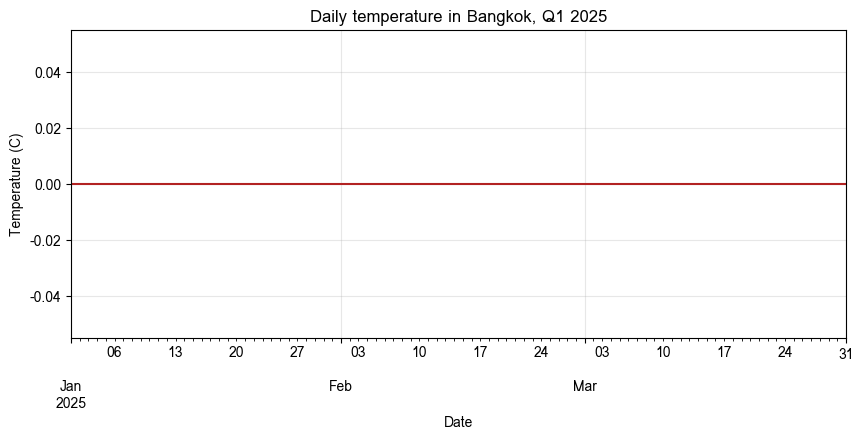

In [106]:
import matplotlib.pyplot as plt
import seaborn as sns

# แนวปฏิบัติที่แนะนำคือสร้าง figure และ axes ขึ้นก่อน แล้วส่ง ax เข้าไปในคำสั่ง plot
bangkok = df[df["city"] == "Bangkok"].sort_values("date")

fig, ax = plt.subplots(figsize=(10, 4))
bangkok.plot(x="date", y="temperature_c", ax=ax, color="firebrick", legend=False)
ax.set_title("Daily temperature in Bangkok, Q1 2025")
ax.set_xlabel("Date")
ax.set_ylabel("Temperature (C)")
ax.grid(alpha=0.3)
plt.show()

### ตัวอย่างที่ 2 กราฟแท่งแนวตั้งและแนวนอน

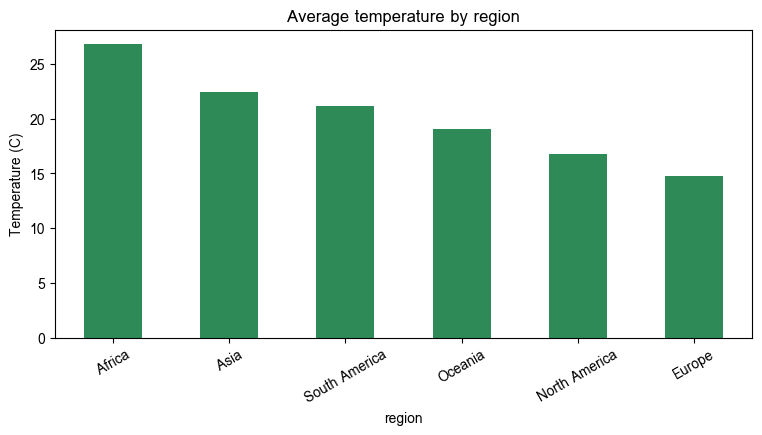

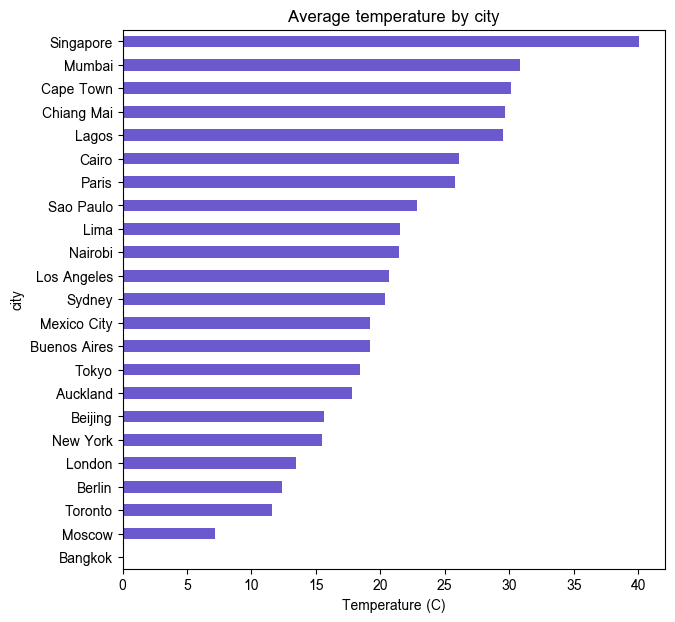

In [107]:
avg_by_region = df.groupby("region")["temperature_c"].mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 4))
avg_by_region.plot(kind="bar", ax=ax, color="seagreen")
ax.set_title("Average temperature by region")
ax.set_ylabel("Temperature (C)")
ax.tick_params(axis="x", rotation=30)
plt.show()

avg_by_city = df.groupby("city")["temperature_c"].mean().sort_values()
fig, ax = plt.subplots(figsize=(7, 7))
avg_by_city.plot(kind="barh", ax=ax, color="slateblue")
ax.set_title("Average temperature by city")
ax.set_xlabel("Temperature (C)")
plt.show()

### ตัวอย่างที่ 3 ฮิสโตแกรม กราฟจุด และ boxplot

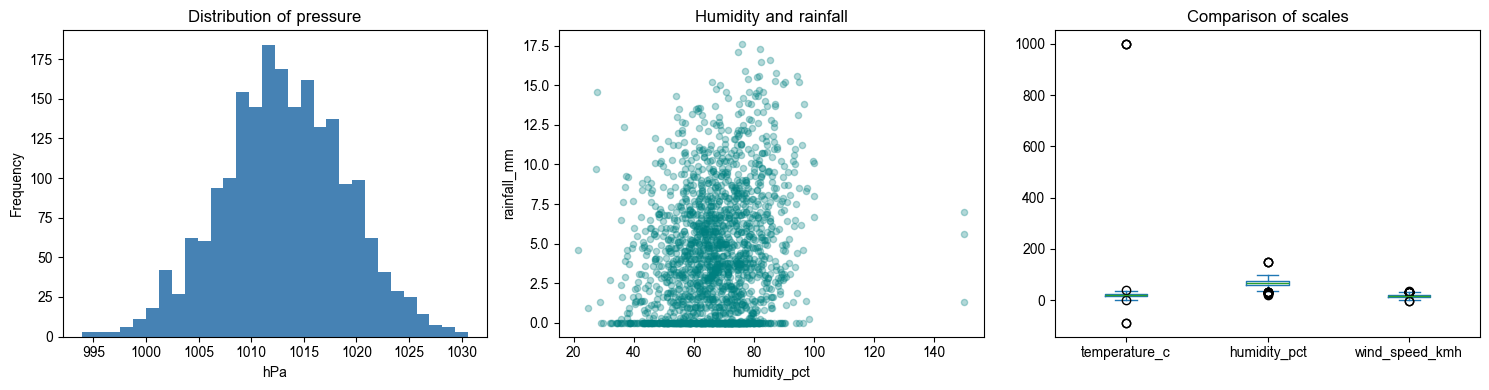

In [108]:
# การวางกราฟหลายรูปในภาพเดียว ให้สร้าง axes เป็นกริดแล้วส่งแต่ละช่องเข้าไปด้วยพารามิเตอร์ ax
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

df["pressure_hpa"].plot(kind="hist", bins=30, ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of pressure")
axes[0].set_xlabel("hPa")

df.plot(kind="scatter", x="humidity_pct", y="rainfall_mm", alpha=0.3, ax=axes[1], color="teal")
axes[1].set_title("Humidity and rainfall")

df[["temperature_c", "humidity_pct", "wind_speed_kmh"]].plot(kind="box", ax=axes[2])
axes[2].set_title("Comparison of scales")

plt.tight_layout()
plt.show()

### ตัวอย่างที่ 4 กราฟวงกลมและการนับสัดส่วน

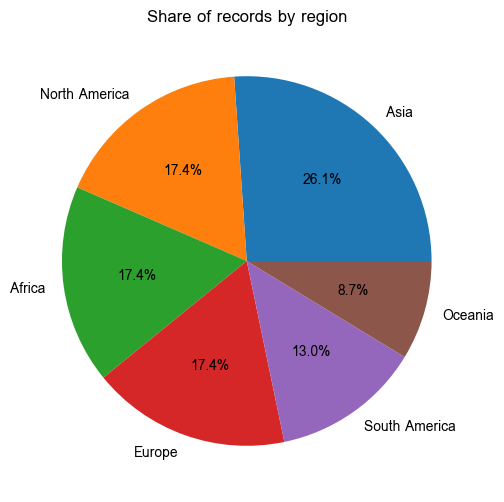

In [109]:
fig, ax = plt.subplots(figsize=(6, 6))
df["region"].value_counts().plot(kind="pie", ax=ax, autopct="%1.1f%%", ylabel="")
ax.set_title("Share of records by region")
plt.show()

### ตัวอย่างที่ 5 การวาดหลายคอลัมน์พร้อมกัน ด้วย `subplots` และ `secondary_y`

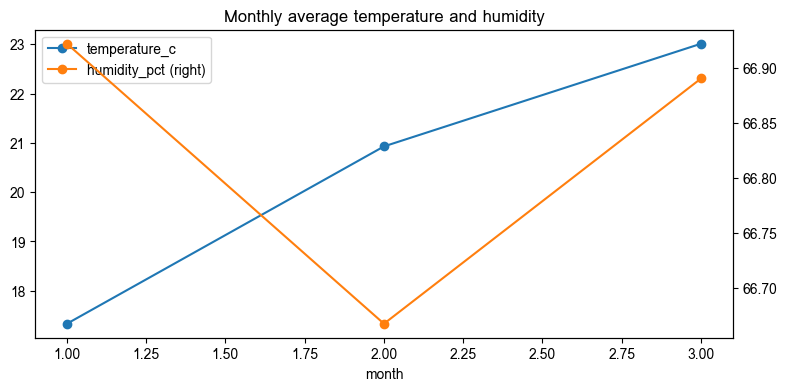

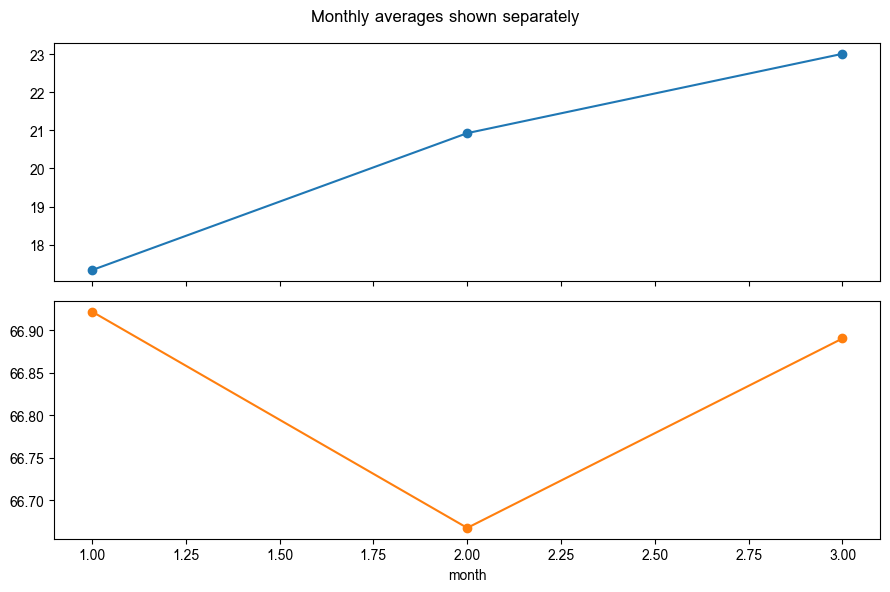

In [110]:
monthly = df.groupby("month")[["temperature_c", "humidity_pct"]].mean()

# secondary_y ใช้แกน y ด้านขวาสำหรับคอลัมน์ที่มีสเกลต่างกันมาก
fig, ax = plt.subplots(figsize=(9, 4))
monthly.plot(ax=ax, marker="o", secondary_y="humidity_pct")
ax.set_title("Monthly average temperature and humidity")
plt.show()

# subplots=True แยกแต่ละคอลัมน์ออกเป็นกราฟย่อย
axes = monthly.plot(subplots=True, layout=(2, 1), figsize=(9, 6), marker="o", legend=False)
plt.suptitle("Monthly averages shown separately")
plt.tight_layout()
plt.show()

### ตัวอย่างที่ 6 กราฟแท่งซ้อนจากตารางไขว้

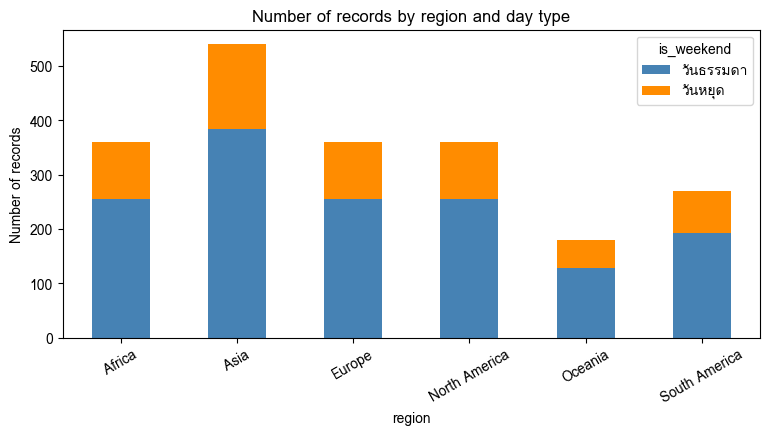

In [111]:
df["is_weekend"] = df["date"].dt.dayofweek >= 5
weekend_by_region = (df.groupby(["region", "is_weekend"]).size()
                       .unstack(fill_value=0)
                       .rename(columns={False: "วันธรรมดา", True: "วันหยุด"}))

fig, ax = plt.subplots(figsize=(9, 4))
weekend_by_region.plot(kind="bar", stacked=True, ax=ax, color=["steelblue", "darkorange"])
ax.set_title("Number of records by region and day type")
ax.set_ylabel("Number of records")
ax.tick_params(axis="x", rotation=30)
plt.show()

### ตัวอย่างที่ 7 กราฟเชิงสถิติด้วย seaborn

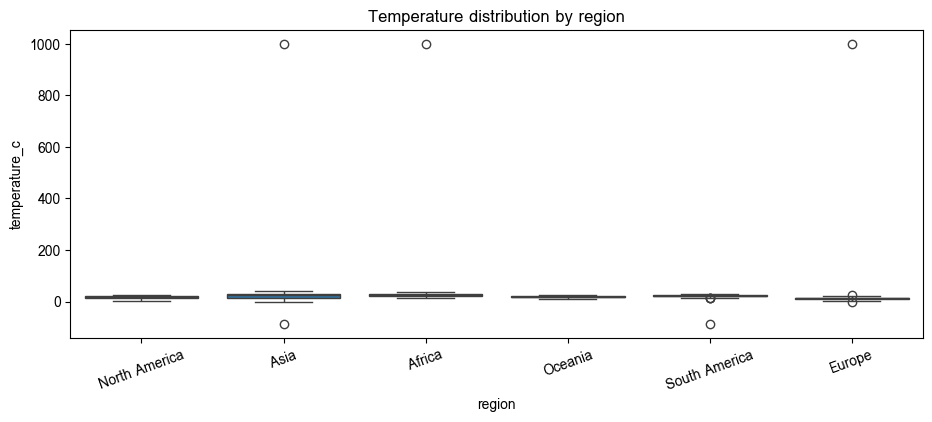

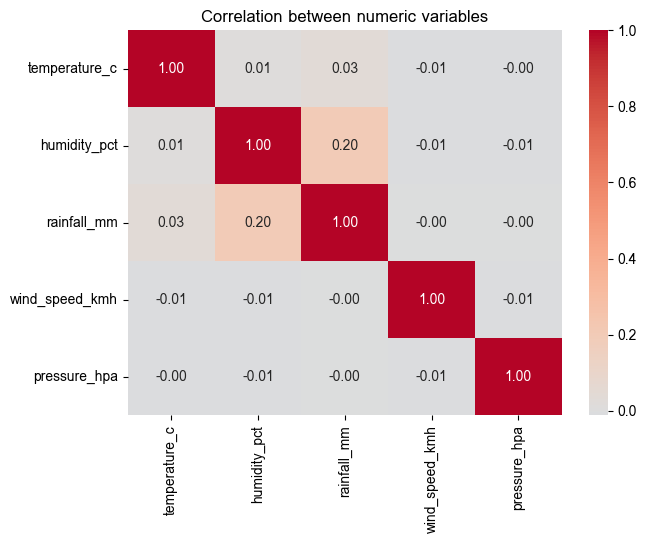

In [112]:
fig, ax = plt.subplots(figsize=(11, 4))
sns.boxplot(data=df, x="region", y="temperature_c", ax=ax)
ax.set_title("Temperature distribution by region")
ax.tick_params(axis="x", rotation=20)
plt.show()

numeric_cols = ["temperature_c", "humidity_pct", "rainfall_mm", "wind_speed_kmh", "pressure_hpa"]
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation between numeric variables")
plt.show()

### โจทย์ 17.1
สร้างกราฟสี่รูปจาก DataFrame โดยใช้ `.plot()` พร้อมกำหนดชื่อกราฟและชื่อแกนให้ครบทุกรูป

1. กราฟเส้นแสดงแนวโน้มอุณหภูมิรายวันของสามเมืองในรูปเดียวกัน พร้อมคำอธิบายสัญลักษณ์
2. กราฟแท่งแนวนอนแสดงปริมาณฝนรวมรายเมือง เรียงจากมากไปน้อย
3. ฮิสโตแกรมของ `wind_speed_kmh` โดยทดลองกำหนด `bins` สามค่าที่ต่างกันและอธิบายผลของการเลือก `bins`
4. กราฟจุดระหว่าง `population_millions` กับอุณหภูมิเฉลี่ยรายเมือง

In [113]:
# คำตอบข้อ 17.1


#### กราฟ 1: กราฟเส้นแสดงแนวโน้มอุณหภูมิรายวันของสามเมือง

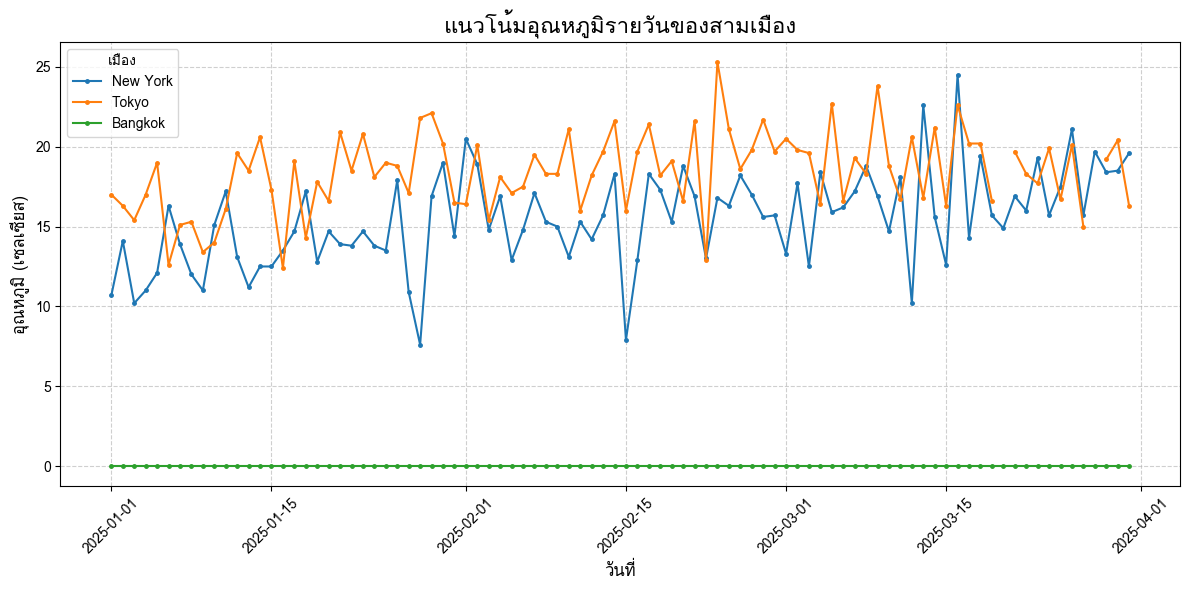

In [114]:
import matplotlib.pyplot as plt

selected_cities = ['New York', 'Tokyo', 'Bangkok']
df_selected = df[df['city'].isin(selected_cities)].sort_values('date')

fig, ax = plt.subplots(figsize=(12, 6))
for city in selected_cities:
    city_data = df_selected[df_selected['city'] == city]
    ax.plot(city_data['date'], city_data['temperature_c'], label=city, marker='.', markersize=5)

ax.set_title('แนวโน้มอุณหภูมิรายวันของสามเมือง', fontsize=16)
ax.set_xlabel('วันที่', fontsize=12)
ax.set_ylabel('อุณหภูมิ (เซลเซียส)', fontsize=12)
ax.legend(title='เมือง')
ax.grid(True, linestyle='--', alpha=0.6)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### กราฟ 2: กราฟแท่งแนวนอนแสดงปริมาณฝนรวมรายเมือง

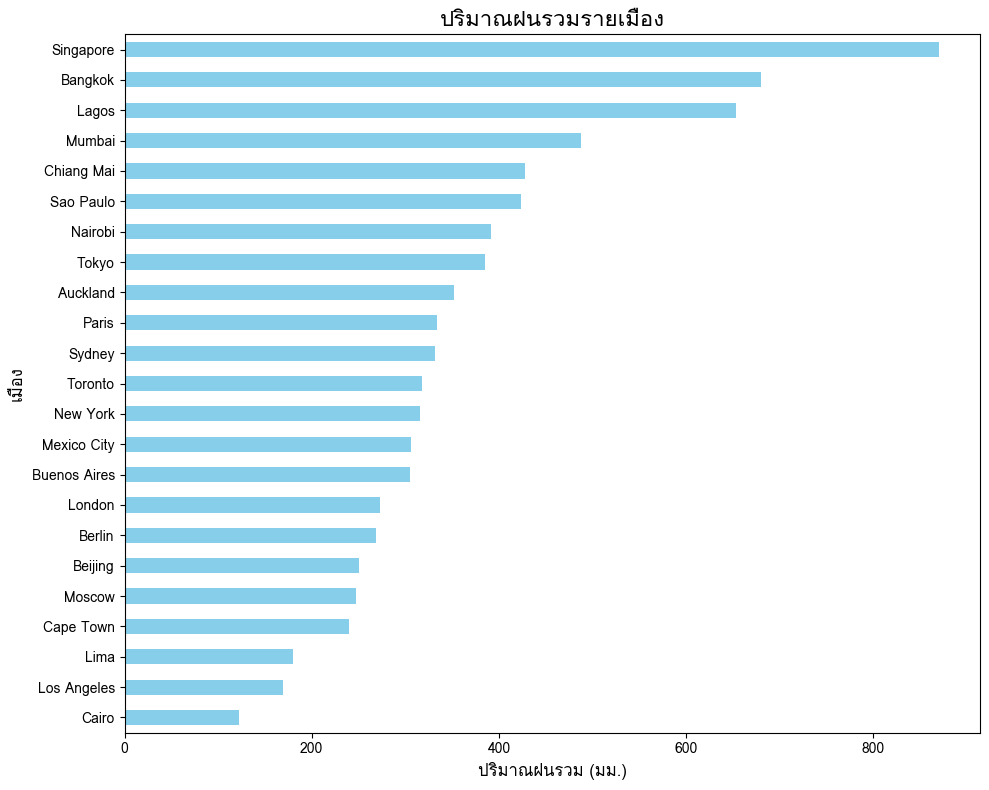

In [115]:
total_rainfall_by_city = df.groupby('city')['rainfall_mm'].sum().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 8))
total_rainfall_by_city.plot(kind='barh', ax=ax, color='skyblue')

ax.set_title('ปริมาณฝนรวมรายเมือง', fontsize=16)
ax.set_xlabel('ปริมาณฝนรวม (มม.)', fontsize=12)
ax.set_ylabel('เมือง', fontsize=12)
ax.invert_yaxis() # เพื่อให้เมืองที่มีค่าสูงสุดอยู่ด้านบน
plt.tight_layout()
plt.show()

#### กราฟ 3: ฮิสโตแกรมของ `wind_speed_kmh` โดยทดลองใช้ `bins` สามค่า

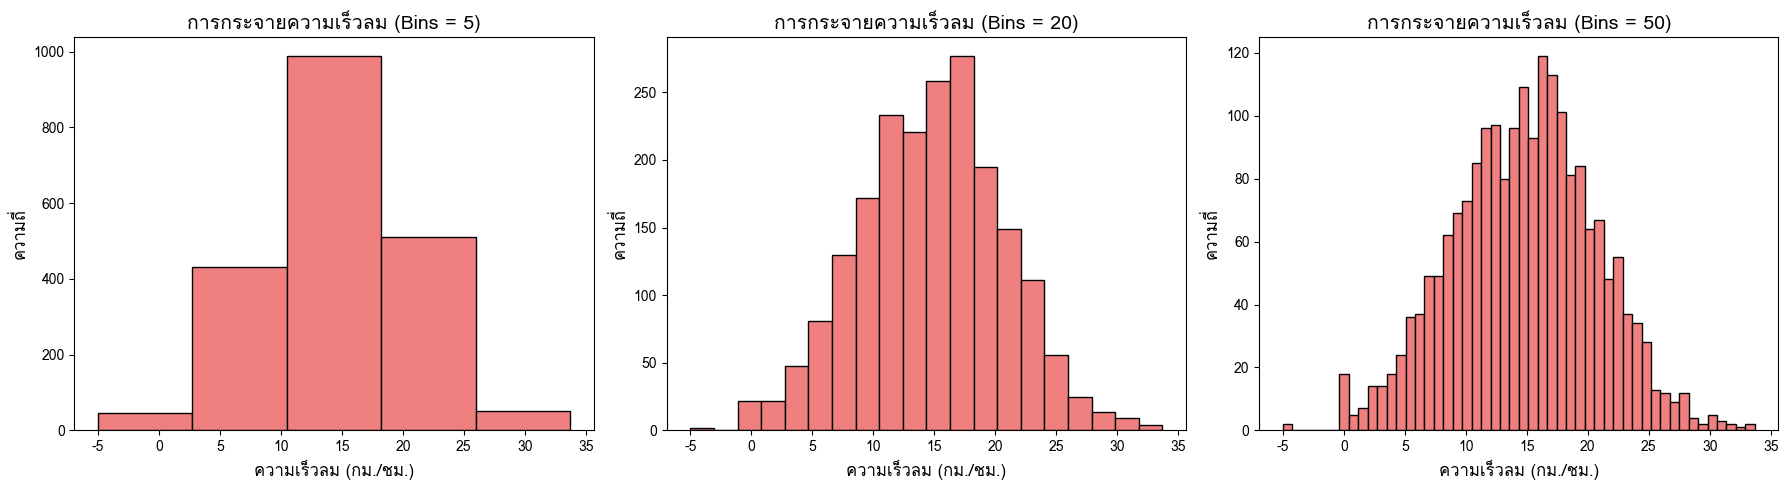

In [116]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
bins_values = [5, 20, 50]
titles = ['Bins = 5', 'Bins = 20', 'Bins = 50']

for i, bins in enumerate(bins_values):
    df['wind_speed_kmh'].plot(kind='hist', bins=bins, ax=axes[i], color='lightcoral', edgecolor='black')
    axes[i].set_title(f'การกระจายความเร็วลม ({titles[i]})', fontsize=14)
    axes[i].set_xlabel('ความเร็วลม (กม./ชม.)', fontsize=12)
    axes[i].set_ylabel('ความถี่', fontsize=12)

plt.tight_layout()
plt.show()

##### คำอธิบายผลของการเลือก `bins` ในฮิสโตแกรม

*   **`bins = 5` (จำนวนช่วงน้อย):** ทำให้เห็นภาพรวมของการกระจายข้อมูลอย่างหยาบๆ ช่วงของข้อมูลจะกว้าง ทำให้ข้อมูลจำนวนมากถูกจัดอยู่ในช่วงเดียวกัน อาจทำให้พลาดรายละเอียดปลีกย่อยหรือรูปแบบการกระจุกตัวบางอย่างไปได้
*   **`bins = 20` (จำนวนช่วงปานกลาง):** เป็นค่าที่มักจะให้ภาพการกระจายที่สมดุล เห็นทั้งภาพรวมและรายละเอียดของรูปแบบการกระจุกตัวของข้อมูลได้ชัดเจนขึ้น เป็นค่าเริ่มต้นที่ดีในการสำรวจข้อมูล
*   **`bins = 50` (จำนวนช่วงมาก):** ทำให้เห็นรายละเอียดของข้อมูลมากขึ้น ช่วงของข้อมูลจะแคบลง อาจทำให้เห็นความผันผวนเล็กๆ น้อยๆ หรือช่องว่างของข้อมูลที่ชัดเจนขึ้น แต่ถ้าจำนวน `bins` มากเกินไปและข้อมูลมีไม่มากพอ อาจทำให้กราฟดูเป็นซี่ๆ หรือมีรูพรุน ไม่ราบรื่น ทำให้การตีความยากขึ้น

การเลือกจำนวน `bins` ที่เหมาะสมขึ้นอยู่กับลักษณะของข้อมูลและวัตถุประสงค์ของการวิเคราะห์ โดยทั่วไปแล้ว ควรลองปรับค่า `bins` เพื่อหาสมดุลที่ให้ภาพการกระจายข้อมูลที่ชัดเจนและสื่อความหมายที่สุด

#### กราฟ 4: กราฟจุดระหว่าง `population_millions` กับอุณหภูมิเฉลี่ยรายเมือง

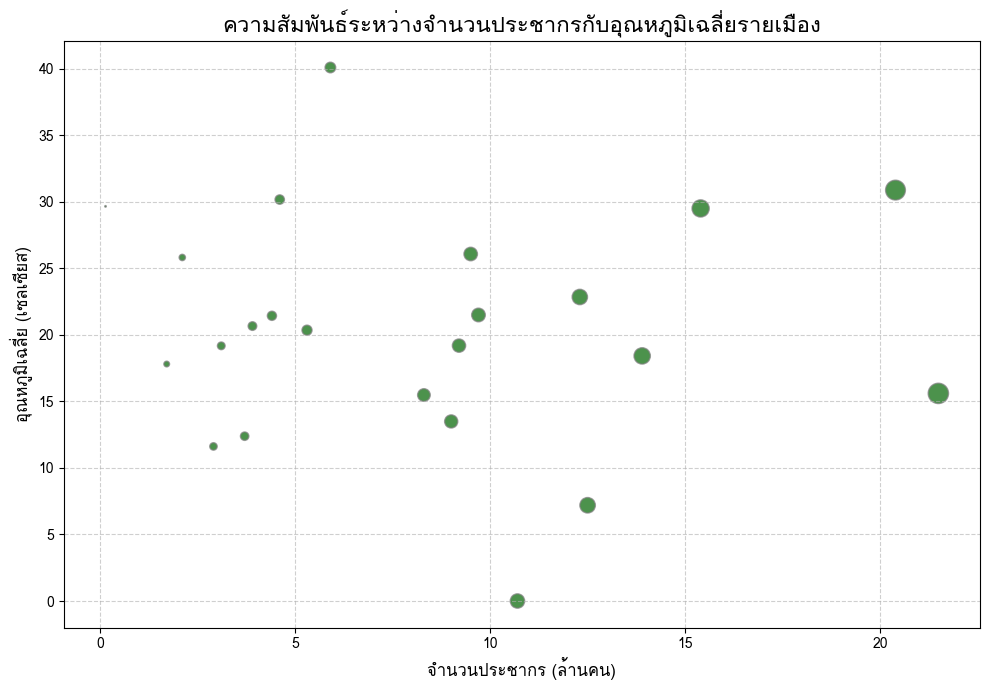

In [117]:
avg_temp_by_city = df.groupby('city')['temperature_c'].mean().reset_index()
city_pop_temp = avg_temp_by_city.merge(city_info[['city', 'population_millions']], on='city', how='left')

fig, ax = plt.subplots(figsize=(10, 7))
city_pop_temp.plot(kind='scatter', x='population_millions', y='temperature_c', ax=ax, alpha=0.7, color='darkgreen', s=city_pop_temp['population_millions']*10, edgecolors='gray')

ax.set_title('ความสัมพันธ์ระหว่างจำนวนประชากรกับอุณหภูมิเฉลี่ยรายเมือง', fontsize=16)
ax.set_xlabel('จำนวนประชากร (ล้านคน)', fontsize=12)
ax.set_ylabel('อุณหภูมิเฉลี่ย (เซลเซียส)', fontsize=12)
ax.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### โจทย์ 17.2
นำผลลัพธ์ของโจทย์ 17.1 มาจัดวางในภาพเดียวกันด้วย `plt.subplots(2, 2)` พร้อมกำหนดชื่อรวมของภาพด้วย `plt.suptitle()`

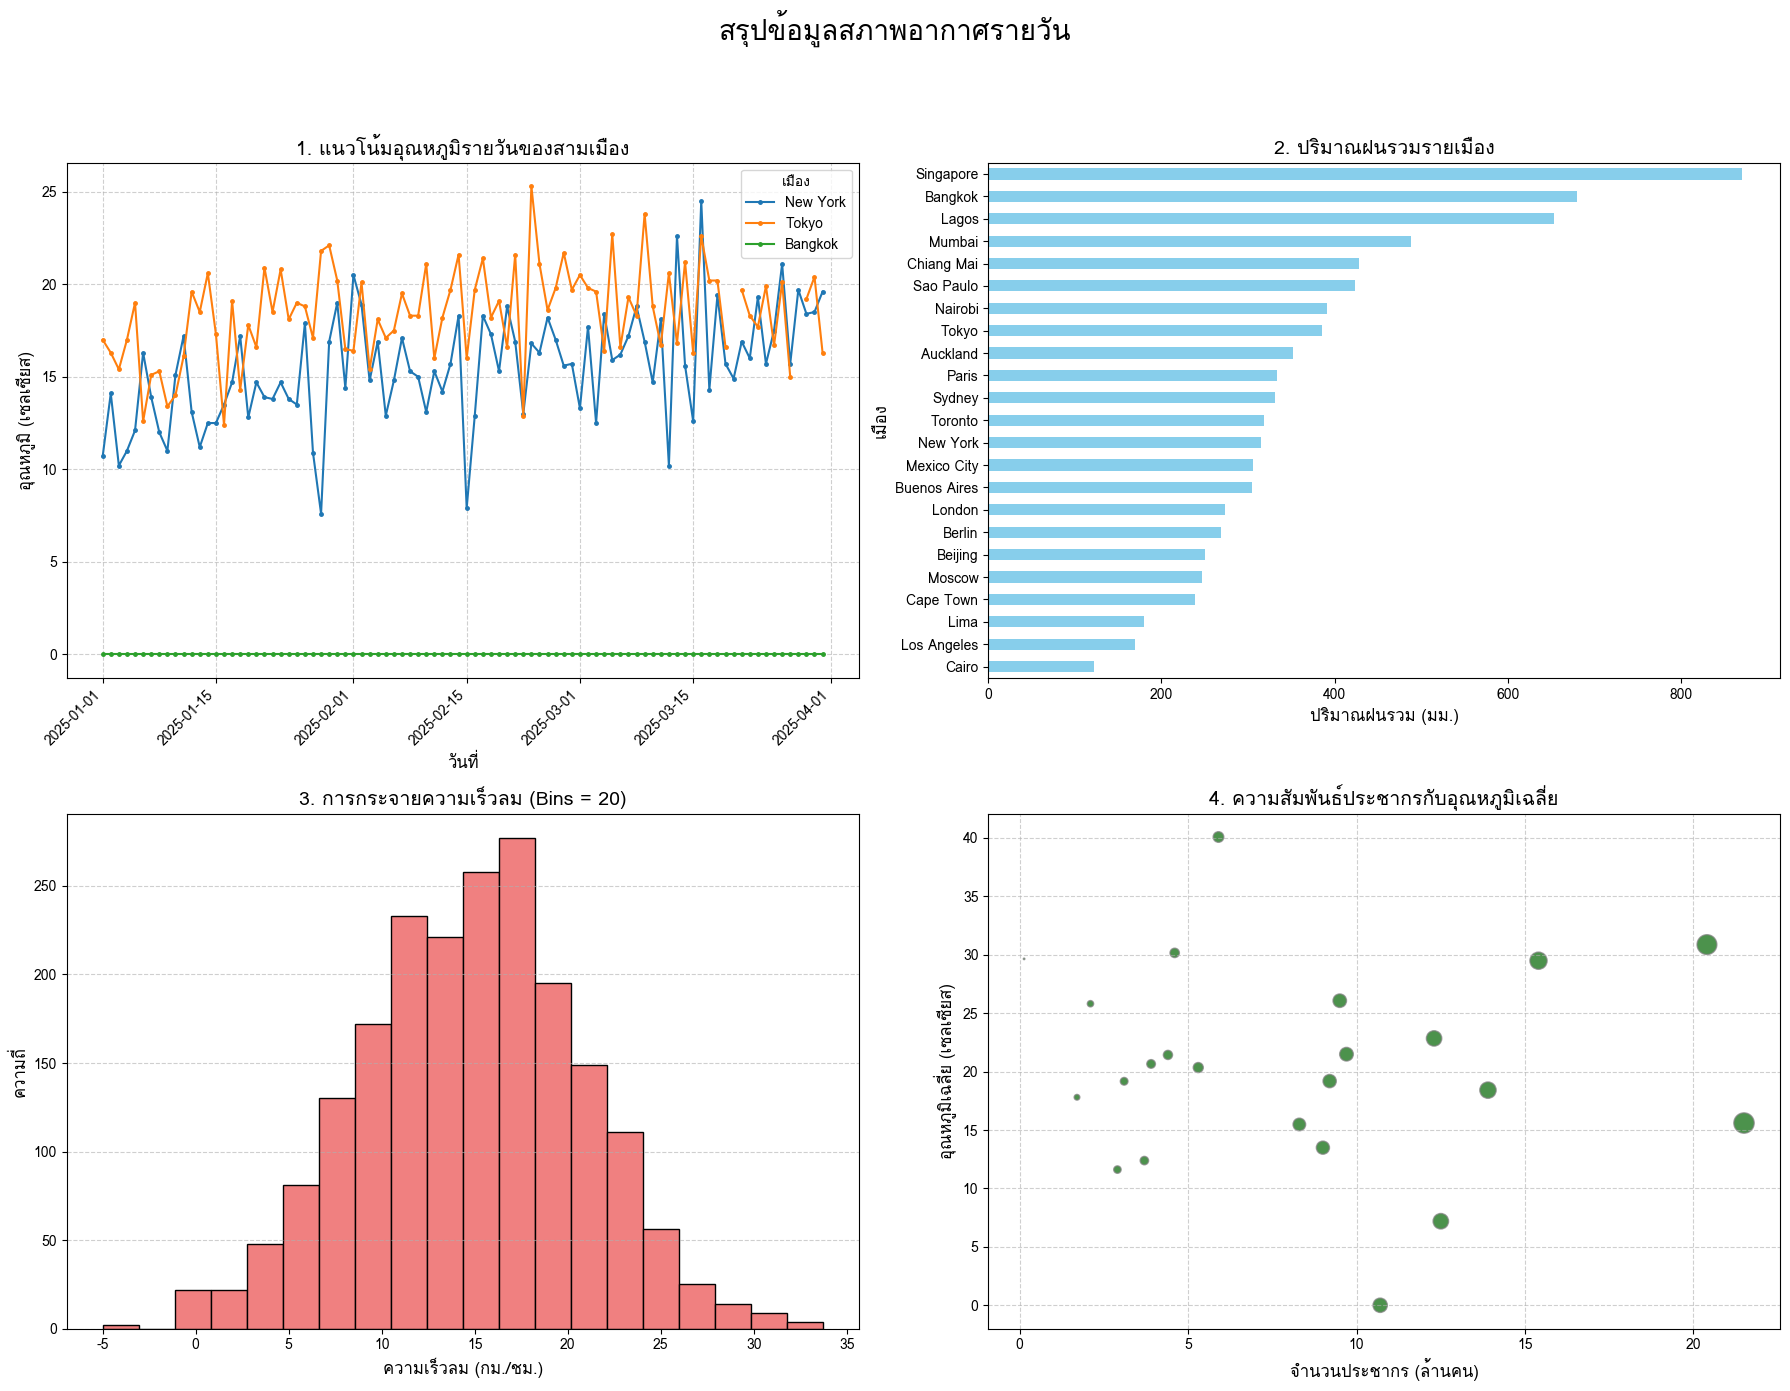

In [118]:
# คำตอบข้อ 17.2
import matplotlib.pyplot as plt
import seaborn as sns

# สร้าง Figure และ Axes สำหรับ 4 กราฟ (2 แถว, 2 คอลัมน์)
fig, axes = plt.subplots(2, 2, figsize=(18, 14))
plt.suptitle('สรุปข้อมูลสภาพอากาศรายวัน', fontsize=20, y=1.02)

# กราฟ 1: กราฟเส้นแสดงแนวโน้มอุณหภูมิรายวันของสามเมือง
selected_cities = ['New York', 'Tokyo', 'Bangkok']
df_selected = df[df['city'].isin(selected_cities)].sort_values('date')
for city in selected_cities:
    city_data = df_selected[df_selected['city'] == city]
    axes[0, 0].plot(city_data['date'], city_data['temperature_c'], label=city, marker='.', markersize=5)
axes[0, 0].set_title('1. แนวโน้มอุณหภูมิรายวันของสามเมือง', fontsize=14)
axes[0, 0].set_xlabel('วันที่', fontsize=12)
axes[0, 0].set_ylabel('อุณหภูมิ (เซลเซียส)', fontsize=12)
axes[0, 0].legend(title='เมือง')
axes[0, 0].grid(True, linestyle='--', alpha=0.6)
plt.setp(axes[0, 0].get_xticklabels(), rotation=45, ha='right')

# กราฟ 2: กราฟแท่งแนวนอนแสดงปริมาณฝนรวมรายเมือง
total_rainfall_by_city = df.groupby('city')['rainfall_mm'].sum().sort_values(ascending=False)
total_rainfall_by_city.plot(kind='barh', ax=axes[0, 1], color='skyblue')
axes[0, 1].set_title('2. ปริมาณฝนรวมรายเมือง', fontsize=14)
axes[0, 1].set_xlabel('ปริมาณฝนรวม (มม.)', fontsize=12)
axes[0, 1].set_ylabel('เมือง', fontsize=12)
axes[0, 1].invert_yaxis() # เพื่อให้เมืองที่มีค่าสูงสุดอยู่ด้านบน

# กราฟ 3: ฮิสโตแกรมของ wind_speed_kmh (ใช้ bins=20 เป็นตัวแทน)
df['wind_speed_kmh'].plot(kind='hist', bins=20, ax=axes[1, 0], color='lightcoral', edgecolor='black')
axes[1, 0].set_title('3. การกระจายความเร็วลม (Bins = 20)', fontsize=14)
axes[1, 0].set_xlabel('ความเร็วลม (กม./ชม.)', fontsize=12)
axes[1, 0].set_ylabel('ความถี่', fontsize=12)
axes[1, 0].grid(axis='y', linestyle='--', alpha=0.6)

# กราฟ 4: กราฟจุดระหว่าง population_millions กับอุณหภูมิเฉลี่ยรายเมือง
avg_temp_by_city = df.groupby('city')['temperature_c'].mean().reset_index()
city_pop_temp = avg_temp_by_city.merge(city_info[['city', 'population_millions']], on='city', how='left')
city_pop_temp.plot(kind='scatter', x='population_millions', y='temperature_c', ax=axes[1, 1], alpha=0.7, color='darkgreen', s=city_pop_temp['population_millions']*10, edgecolors='gray')
axes[1, 1].set_title('4. ความสัมพันธ์ประชากรกับอุณหภูมิเฉลี่ย', fontsize=14)
axes[1, 1].set_xlabel('จำนวนประชากร (ล้านคน)', fontsize=12)
axes[1, 1].set_ylabel('อุณหภูมิเฉลี่ย (เซลเซียส)', fontsize=12)
axes[1, 1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout(rect=[0, 0.03, 1, 0.98]) # ปรับ layout ให้ suptitle ไม่ทับกราฟ
plt.show()

### โจทย์ 17.3
สร้างกราฟแท่งซ้อนแสดงจำนวนวันในแต่ละช่วงปริมาณฝน โดยแบ่งช่วงด้วย `pd.cut()` และจำแนกตามภูมิภาค
จากนั้นสร้างกราฟแบบ `stacked=False` เปรียบเทียบ
**อธิบาย:** กราฟแท่งซ้อนเหมาะสมกว่าในกรณีใด และกราฟแท่งเรียงข้างกันเหมาะสมกว่าในกรณีใด

In [119]:
# คำตอบข้อ 17.3
import matplotlib.pyplot as plt
import seaborn as sns

# กำหนดช่วงปริมาณฝนด้วย pd.cut()
# ใช้ bin ที่สมเหตุสมผลเพื่อให้เห็นการกระจาย
rain_bins = [-0.1, 0.0, 5.0, 10.0, df['rainfall_mm'].max()]
rain_labels = ['ไม่มีฝน', 'ฝนน้อย (0-5มม.)', 'ฝนปานกลาง (5-10มม.)', 'ฝนหนัก (>10มม.)']

df['rainfall_bin'] = pd.cut(df['rainfall_mm'], bins=rain_bins, labels=rain_labels, right=True)
# สร้างตารางไขว้ (crosstab) สำหรับจำนวนวันในแต่ละช่วงฝนและภูมิภาค
rainfall_by_region = pd.crosstab(df['region'], df['rainfall_bin'])

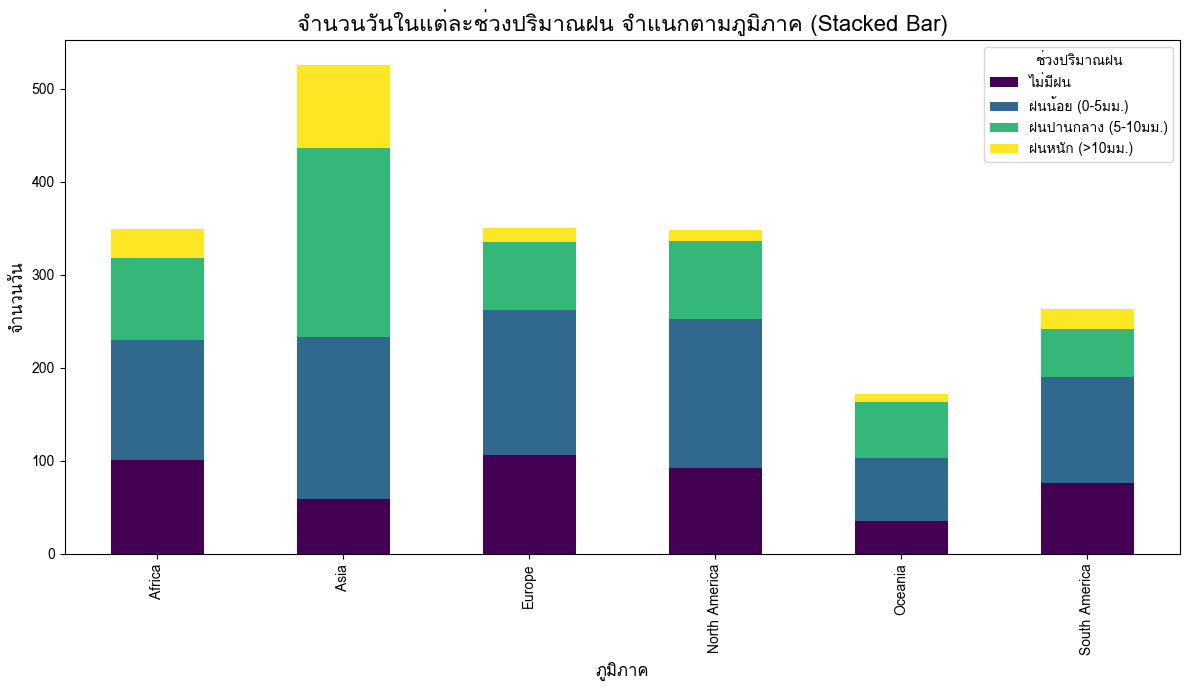

In [120]:
# กราฟ 1: กราฟแท่งซ้อน (Stacked Bar Chart)
fig, ax = plt.subplots(figsize=(12, 7))
rainfall_by_region.plot(kind='bar', stacked=True, ax=ax, cmap='viridis')
ax.set_title('จำนวนวันในแต่ละช่วงปริมาณฝน จำแนกตามภูมิภาค (Stacked Bar)', fontsize=16)
ax.set_xlabel('ภูมิภาค', fontsize=12)
ax.set_ylabel('จำนวนวัน', fontsize=12)
ax.legend(title='ช่วงปริมาณฝน')
plt.tight_layout()
plt.show()

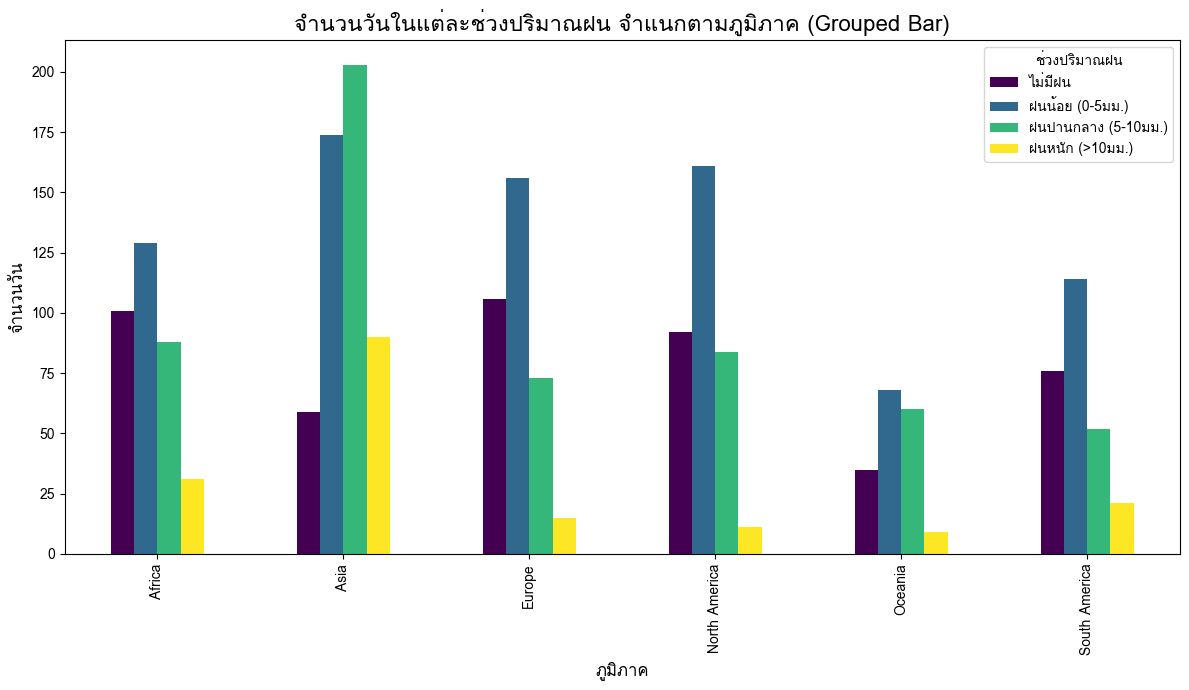

In [121]:
# กราฟ 2: กราฟแท่งแบบเรียงข้างกัน (Grouped Bar Chart)
fig, ax = plt.subplots(figsize=(12, 7))
rainfall_by_region.plot(kind='bar', stacked=False, ax=ax, cmap='viridis')
ax.set_title('จำนวนวันในแต่ละช่วงปริมาณฝน จำแนกตามภูมิภาค (Grouped Bar)', fontsize=16)
ax.set_xlabel('ภูมิภาค', fontsize=12)
ax.set_ylabel('จำนวนวัน', fontsize=12)
ax.legend(title='ช่วงปริมาณฝน')
plt.tight_layout()
plt.show()

**คำอธิบาย:**

*   **กราฟแท่งซ้อน (Stacked Bar Chart)** เหมาะสมกว่าในกรณีที่คุณต้องการแสดง:
    *   **องค์ประกอบของส่วนรวม:** ให้เห็นว่าแต่ละหมวดหมู่ (ในที่นี้คือภูมิภาค) ประกอบด้วยส่วนย่อย (ช่วงปริมาณฝน) อย่างไร
    *   **ผลรวมของแต่ละหมวดหมู่:** ความสูงรวมของแท่งแต่ละแท่งแสดงถึงจำนวนวันทั้งหมดของภูมิภาคนั้น
    *   **การเปรียบเทียบสัดส่วน:** สามารถมองเห็นได้ง่ายว่าสัดส่วนของแต่ละช่วงปริมาณฝนในแต่ละภูมิภาคแตกต่างกันอย่างไร (แม้จะเปรียบเทียบความสูงของแต่ละส่วนได้ยากหากมีหลายส่วน)
    *   ตัวอย่างเช่น หากคุณต้องการเน้นว่าภูมิภาคใดมีจำนวนวันฝนตกหนักรวมมากที่สุด และสัดส่วนของวันที่ไม่มีฝนในแต่ละภูมิภาคเป็นอย่างไร กราฟแท่งซ้อนจะให้ภาพรวมที่ดี

*   **กราฟแท่งเรียงข้างกัน (Grouped Bar Chart หรือ Non-Stacked Bar Chart)** เหมาะสมกว่าในกรณีที่คุณต้องการแสดง:
    *   **การเปรียบเทียบค่าที่แม่นยำ:** การเปรียบเทียบความสูงของแท่งแต่ละแท่งในกลุ่มเดียวกัน หรือเปรียบเทียบแท่งเดียวกันระหว่างกลุ่ม จะทำได้ง่ายและแม่นยำกว่า เนื่องจากทุกแท่งเริ่มต้นจากแกน 0 เดียวกัน
    *   **การเปรียบเทียบระหว่างส่วนย่อย:** หากคุณต้องการเน้นการเปรียบเทียบโดยตรงว่า 'ภูมิภาค A มีจำนวนวันฝนตกปานกลางมากกว่าภูมิภาค B หรือไม่' กราฟแบบเรียงข้างกันจะให้คำตอบได้ชัดเจนกว่า
    *   ตัวอย่างเช่น: หากคุณต้องการดูว่าภูมิภาคใดมีจำนวน 'วันที่ไม่มีฝน' มากที่สุด หรือภูมิภาคใดมี 'จำนวนวันฝนตกหนัก' สูงที่สุดเมื่อเทียบกัน กราฟแบบเรียงข้างกันจะเหมาะสมกว่า

### โจทย์ 17.4
สร้างกราฟด้วย seaborn สองรูป ได้แก่ boxplot ของ `rainfall_mm` จำแนกตามภูมิภาคและแยกสีตาม `is_weekend`
และ heatmap ของสหสัมพันธ์ระหว่าง `temperature_c`, `humidity_pct`, `rainfall_mm` และ `population_millions`
พร้อมตีความผลที่ได้เป็นข้อความ

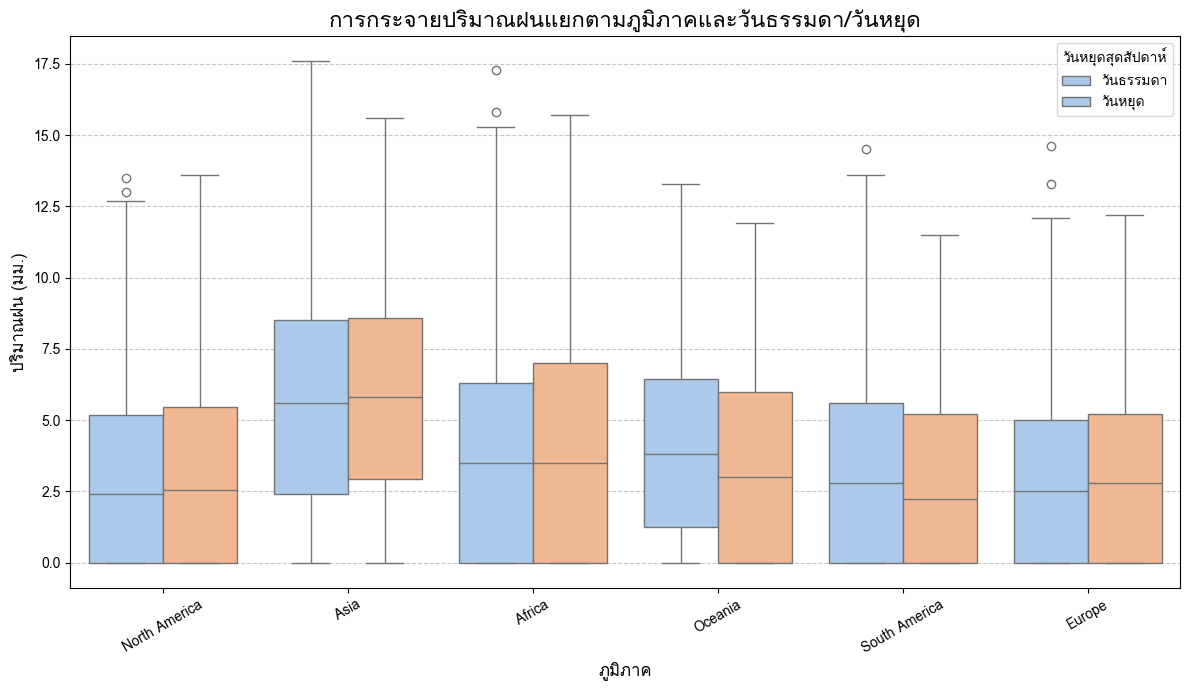

In [122]:
# คำตอบข้อ 17.4
import matplotlib.pyplot as plt
import seaborn as sns

# กราฟ Boxplot ของ rainfall_mm จำแนกตามภูมิภาคและแยกสีตาม is_weekend
fig, ax = plt.subplots(figsize=(12, 7))
sns.boxplot(data=df, x='region', y='rainfall_mm', hue='is_weekend', palette='pastel', ax=ax)
ax.set_title('การกระจายปริมาณฝนแยกตามภูมิภาคและวันธรรมดา/วันหยุด', fontsize=16)
ax.set_xlabel('ภูมิภาค', fontsize=12)
ax.set_ylabel('ปริมาณฝน (มม.)', fontsize=12)
ax.tick_params(axis='x', rotation=30)
ax.legend(title='วันหยุดสุดสัปดาห์', labels=['วันธรรมดา', 'วันหยุด'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

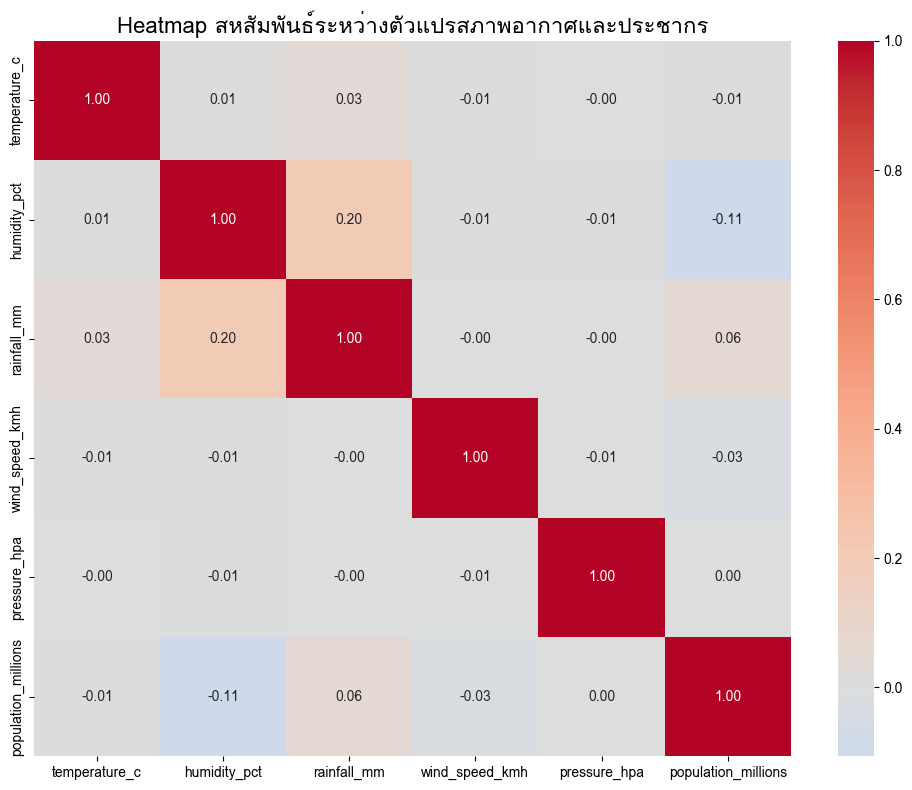

In [123]:
# เตรียมข้อมูลสำหรับ Heatmap: รวม df กับ city_info เพื่อดึง 'population_millions'
# ใช้ final_clean จากโจทย์ 14.1
try:
    # ตรวจสอบว่า final_clean มีอยู่และมีคอลัมน์ที่ต้องการหรือไม่
    if 'final_clean' not in locals() or 'population_millions' not in final_clean.columns:
        m_step1 = df.merge(city_info, on="city", how="left", suffixes=("", "_city_info"))
        final_clean = m_step1.merge(region_info, on="region", how="left", suffixes=("", "_region_info"))

        # จัดการคอลัมน์ที่ชื่อซ้ำกัน
        dup_cols = [c for col in ["country", "region"] for c in final_clean.columns if col in c and c != col]
        final_clean = final_clean.drop(columns=dup_cols, errors="ignore")

    heatmap_cols = ['temperature_c', 'humidity_pct', 'rainfall_mm', 'wind_speed_kmh', 'pressure_hpa', 'population_millions']
    correlation_matrix = final_clean[heatmap_cols].corr()

    fig, ax = plt.subplots(figsize=(10, 8))
    sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
    ax.set_title('Heatmap สหสัมพันธ์ระหว่างตัวแปรสภาพอากาศและประชากร', fontsize=16)
    plt.tight_layout()
    plt.show()
except NameError:
    print("Could not find 'final_clean' DataFrame. Please ensure problem 14.1 has been executed successfully.")
    print("Attempting to create a temporary merged DataFrame for heatmap...")
    temp_merged_df = df.merge(city_info[['city', 'population_millions']], on='city', how='left')
    heatmap_cols = ['temperature_c', 'humidity_pct', 'rainfall_mm', 'population_millions']
    correlation_matrix = temp_merged_df[heatmap_cols].corr()

    fig, ax = plt.subplots(figsize=(10, 8))
    sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
    ax.set_title('Heatmap สหสัมพันธ์ระหว่างตัวแปรสภาพอากาศและประชากร', fontsize=16)
    plt.tight_layout()
    plt.show()

#### การตีความผลลัพธ์

*   **กราฟ Boxplot: การกระจายปริมาณฝนแยกตามภูมิภาคและวันธรรมดา/วันหยุด**
    *   กราฟนี้แสดงให้เห็นว่าปริมาณฝน (`rainfall_mm`) กระจายตัวอย่างไรในแต่ละภูมิภาค (`region`) และมีการเปลี่ยนแปลงหรือไม่ระหว่างวันธรรมดา (`is_weekend` = False) กับวันหยุด (`is_weekend` = True)
    *   สามารถสังเกตค่ามัธยฐาน (เส้นกลางในกล่อง), ช่วงควอร์ไทล์ (กล่อง), และค่าผิดปกติ (จุด) ของปริมาณฝนในแต่ละกลุ่ม
    *   หากกล่องของวันหยุดและวันธรรมดามีความแตกต่างกันอย่างชัดเจนในภูมิภาคใด แสดงว่ารูปแบบปริมาณฝนมีความสัมพันธ์กับวันในสัปดาห์ในภูมิภาคนั้นๆ
    *   ตัวอย่างเช่น: หากภูมิภาคเอเชียมีปริมาณฝนในวันธรรมดาสูงกว่าวันหยุดอย่างเห็นได้ชัด อาจบ่งชี้ถึงรูปแบบสภาพอากาศที่น่าสนใจ

*   **Heatmap: สหสัมพันธ์ระหว่างตัวแปรสภาพอากาศและประชากร**
    *   แผนที่ความร้อนนี้แสดงค่าสัมประสิทธิ์สหสัมพันธ์ (Correlation Coefficient) ระหว่างตัวแปรต่างๆ เช่น `temperature_c` (อุณหภูมิ), `humidity_pct` (ความชื้น), `rainfall_mm` (ปริมาณฝน), `wind_speed_kmh` (ความเร็วลม), `pressure_hpa` (ความกดอากาศ) และ `population_millions` (จำนวนประชากร).
    *   **สีแดงเข้ม** แสดงถึงสหสัมพันธ์เชิงบวกที่แข็งแกร่ง (ตัวแปรทั้งสองมีแนวโน้มเพิ่มขึ้น/ลดลงพร้อมกัน)
    *   **สีน้ำเงินเข้ม** แสดงถึงสหสัมพันธ์เชิงลบที่แข็งแกร่ง (ตัวแปรหนึ่งมีแนวโน้มเพิ่มขึ้น แต่อีกตัวแปรหนึ่งมีแนวโน้มลดลง)
    *   **สีขาวซีด** แสดงว่ามีความสัมพันธ์น้อยหรือไม่มีเลย
    *   สามารถใช้ Heatmap นี้เพื่อระบุความสัมพันธ์ที่อาจมีนัยสำคัญ ตัวอย่างเช่น:
        *   หาก `temperature_c` และ `humidity_pct` มีสหสัมพันธ์เชิงบวกที่สูง อาจบ่งชี้ว่าเมื่ออากาศร้อนขึ้น ความชื้นก็มักจะสูงขึ้นด้วย
        *   หาก `population_millions` มีสหสัมพันธ์กับ `temperature_c` หรือ `rainfall_mm` อย่างมีนัยสำคัญ อาจบ่งชี้ว่าสภาพอากาศมีผลต่อการกระจุกตัวของประชากร หรือเมืองใหญ่มีผลต่อสภาพอากาศในระดับท้องถิ่น

---
## ข้อ 18 โจทย์ประยุกต์รวม

ให้ใช้ตารางที่รวมข้อมูลจากทั้ง 3 แหล่งและผ่านการทำความสะอาดแล้ว ตอบคำถามต่อไปนี้
แต่ละข้อต้องประกอบด้วย **ตารางหรือกราฟหนึ่งชิ้น** และ **ข้อสรุปเป็นข้อความสั้น ๆ**

**ข้อกำหนดเพิ่มเติม**

- ให้เขียนโปรแกรมในรูปแบบลำดับต่อเนื่องที่อ่านเข้าใจได้ ไม่ใช้ตัวแปรชั่วคราวจำนวนมากโดยไม่จำเป็น
- ห้ามใช้การวนซ้ำทีละแถว
- หากข้อสรุปขึ้นอยู่กับวิธีจัดการค่าว่างหรือค่าผิดปกติ ให้ระบุวิธีที่เลือกใช้ไว้ด้วย

1. ภูมิภาคใดมีสภาพอากาศแปรปรวนมากที่สุดในไตรมาสแรก เมื่อวัดจากส่วนเบี่ยงเบนมาตรฐานของอุณหภูมิรายวัน
   และความแปรปรวนดังกล่าวเกิดจากทุกเมืองในภูมิภาคนั้นเท่ากันหรือเกิดจากเมืองใดเมืองหนึ่งเป็นหลัก

ภูมิภาคที่มีสภาพอากาศแปรปรวนมากที่สุดคือ: Asia (S.D. = 11.43)


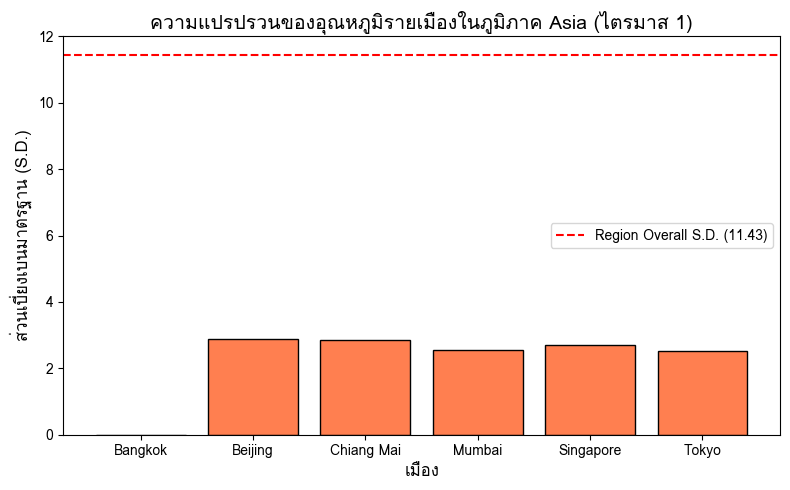

,city,Std_Temperature
1,Beijing,2.87
2,Chiang Mai,2.86
4,Singapore,2.71
3,Mumbai,2.54
5,Tokyo,2.52
0,Bangkok,0.00


In [124]:
# คำตอบข้อ 18.1
import pandas as pd
import matplotlib.pyplot as plt

# 1. การเตรียมและทำความสะอาดข้อมูล
df_clean = df.copy()
# จัดการค่าผิดปกติ: อุณหภูมิที่เป็นไปไม่ได้ (เช่น 999, -88) โดยกรองค่าในช่วง -60 ถึง 60
df_clean['temperature_c'] = df_clean['temperature_c'].where(df_clean['temperature_c'].between(-60, 60))
df_clean = df_clean.dropna(subset=['temperature_c'])

# ก่อนจะ merge ให้มั่นใจว่ามีคอลัมน์ที่จำเป็น และไม่มีคอลัมน์ซ้ำซ้อนจาก city_info
city_info_cols = [c for c in city_info.columns if c == 'city' or c not in df_clean.columns]
merged_df = df_clean.merge(city_info[city_info_cols], on='city', how='left')

# เชื่อมโยงข้อมูลภูมิภาคด้วย region_info
merged_df = merged_df.merge(region_info, on='region', how='left')

# กรองเฉพาะไตรมาสที่ 1 (เดือน 1, 2, 3)
q1_df = merged_df[merged_df['date'].dt.month.isin([1, 2, 3])]

# 2. หาภูมิภาคที่แปรปรวนมากที่สุด (S.D. ของอุณหภูมิสูงสุด)
region_std = q1_df.groupby('region')['temperature_c'].std().sort_values(ascending=False)
most_volatile_region = region_std.index[0]
print(f"ภูมิภาคที่มีสภาพอากาศแปรปรวนมากที่สุดคือ: {most_volatile_region} (S.D. = {region_std.max():.2f})")

# 3. วิเคราะห์ความแปรปรวนรายเมืองในภูมิภาคนั้น
volatile_region_data = q1_df[q1_df['region'] == most_volatile_region]
city_std = volatile_region_data.groupby('city', observed=False)['temperature_c'].std().dropna().reset_index()
city_std = city_std.rename(columns={'temperature_c': 'Std_Temperature'})

# 4. สร้างกราฟแท่งเปรียบเทียบ S.D. ของแต่ละเมืองในภูมิภาคที่แปรปรวนที่สุด
plt.figure(figsize=(8, 5))
plt.bar(city_std['city'], city_std['Std_Temperature'], color='coral', edgecolor='black')
plt.axhline(y=region_std.max(), color='red', linestyle='--', label=f'Region Overall S.D. ({region_std.max():.2f})')
plt.title(f'ความแปรปรวนของอุณหภูมิรายเมืองในภูมิภาค {most_volatile_region} (ไตรมาส 1)', fontsize=14)
plt.xlabel('เมือง', fontsize=12)
plt.ylabel('ส่วนเบี่ยงเบนมาตรฐาน (S.D.)', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

# แสดงตารางข้อมูลประกอบ
display(city_std.sort_values(by='Std_Temperature', ascending=False).style.format({'Std_Temperature': '{:.2f}'}))

In [125]:
df.head(3)

,record_id,date,city,country,region,temperature_c,humidity_pct,rainfall_mm,wind_speed_kmh,pressure_hpa,...,rain_capped,is_weekend,month,city_avg_temp,temp_diff,weather_flag,region_code,heat_index_apply_axis1,heat_index_direct_series,rainfall_bin
0,983,2025-03-24,New York,USA,North America,15.7,72.6,6.3,15.9,1005.4,...,6.3,False,3,15.476667,0.223333,ปกติ,NA,40.74,40.74,ฝนปานกลาง (5-10มม.)
1,220,2025-02-09,Tokyo,Japan,Asia,18.3,60.6,0.0,20.5,1015.1,...,0.0,True,2,18.414773,-0.114773,ปกติ,AS,38.54,38.54,ไม่มีฝน
2,1022,2025-02-01,Los Angeles,USA,North America,20.6,46.8,1.2,8.6,1013.5,...,1.2,True,2,20.657303,-0.057303,ปกติ,NA,35.32,35.32,ฝนน้อย (0-5มม.)


2. เมืองที่มีฝนตกหนักบ่อยที่สุด 5 อันดับแรกเมื่อวัดด้วยสัดส่วน ให้เปรียบเทียบกับผลที่ได้เมื่อวัดด้วยจำนวนวัน
   และอธิบายว่าเหตุใดจึงให้ผลต่างกัน

--- 5 อันดับแรกเมื่อวัดด้วยจำนวนวันรวม ---


,city,heavy_rain_days_count
0,Singapore,44
1,Bangkok,23
2,Lagos,22
3,Sao Paulo,11
4,Buenos Aires,9



--- 5 อันดับแรกเมื่อวัดด้วยสัดส่วน (%) ---


,city,heavy_rain_proportion_pct
0,Singapore,48.888889
1,Bangkok,26.436782
2,Lagos,25.000000
3,Sao Paulo,12.500000
4,Chiang Mai,10.588235


/tmp/ipykernel_2860/1069973163.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top5_by_count, x='heavy_rain_days_count', y='city', ax=axes[0], palette='Blues_r')
/tmp/ipykernel_2860/1069973163.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top5_by_prop, x='heavy_rain_proportion_pct', y='city', ax=axes[1], palette='Oranges_r')


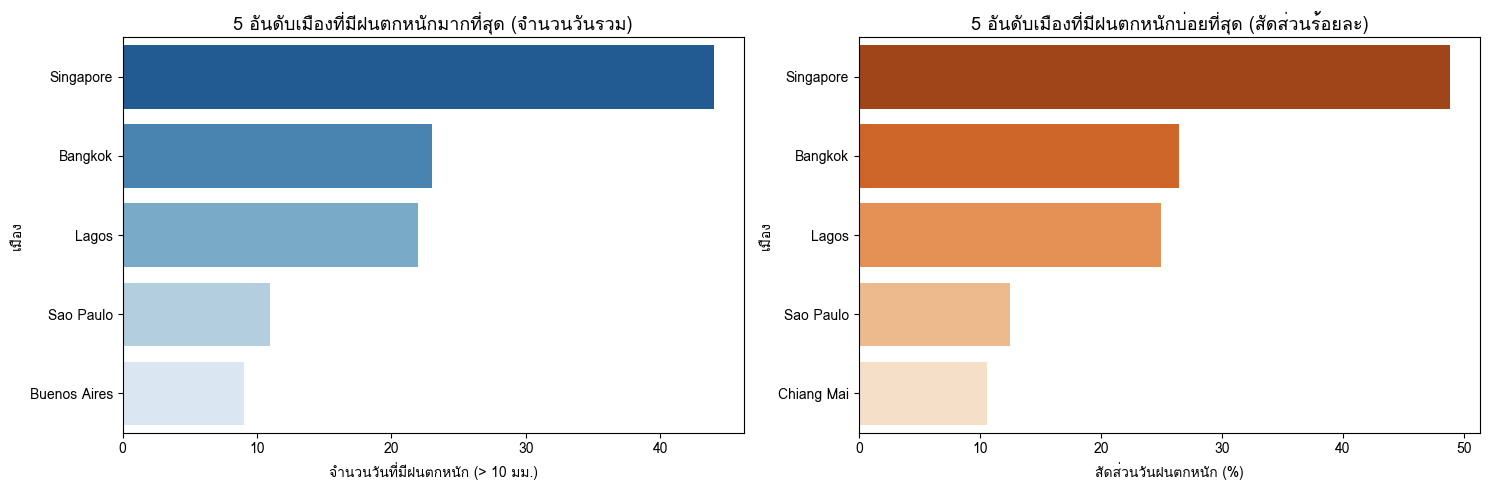

In [126]:
# คำตอบข้อ 18.2
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# นิยามฝนตกหนักคือมากกว่า 10 มม.
is_heavy_rain = df['rainfall_mm'] > 10

# 1. วัดด้วยจำนวนวันรวม (Count)
heavy_rain_days = df[is_heavy_rain].groupby('city').size()
top5_by_count = heavy_rain_days.nlargest(5).reset_index(name='heavy_rain_days_count')

# 2. วัดด้วยสัดส่วน (Proportion)
total_recorded_days = df.groupby('city')['rainfall_mm'].count()
heavy_rain_proportion = heavy_rain_days / total_recorded_days
top5_by_prop = (heavy_rain_proportion * 100).nlargest(5).reset_index(name='heavy_rain_proportion_pct')

# สร้างตารางเปรียบเทียบเพื่อแสดงผลลัพธ์
print("--- 5 อันดับแรกเมื่อวัดด้วยจำนวนวันรวม ---")
display(top5_by_count)
print("\n--- 5 อันดับแรกเมื่อวัดด้วยสัดส่วน (%) ---")
display(top5_by_prop)

# สร้างกราฟเปรียบเทียบ
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# กราฟจำนวนวัน
sns.barplot(data=top5_by_count, x='heavy_rain_days_count', y='city', ax=axes[0], palette='Blues_r')
axes[0].set_title('5 อันดับเมืองที่มีฝนตกหนักมากที่สุด (จำนวนวันรวม)', fontsize=13)
axes[0].set_xlabel('จำนวนวันที่มีฝนตกหนัก (> 10 มม.)')
axes[0].set_ylabel('เมือง')

# กราฟสัดส่วน
sns.barplot(data=top5_by_prop, x='heavy_rain_proportion_pct', y='city', ax=axes[1], palette='Oranges_r')
axes[1].set_title('5 อันดับเมืองที่มีฝนตกหนักบ่อยที่สุด (สัดส่วนร้อยละ)', fontsize=13)
axes[1].set_xlabel('สัดส่วนวันฝนตกหนัก (%)')
axes[1].set_ylabel('เมือง')

plt.tight_layout()
plt.show()

##### **ข้อสรุปและการวิเคราะห์เปรียบเทียบ**

**เหตุผลที่ผลลัพธ์ระหว่างการวัดด้วย "จำนวนวันรวม" และ "สัดส่วน" มีความแตกต่างกัน:**
1. **ความไม่เท่ากันของฐานข้อมูล:** ในทางปฏิบัติ ข้อมูลของแต่ละเมืองอาจมีจำนวนวันบันทึกรวมไม่เท่ากัน เช่น บางเมืองอาจมีเครื่องวัดเสียหรือข้อมูลสูญหายไปบางวัน
2. **การถูกบิดเบือนจากจำนวนวันบันทึก:** การวัดด้วจำนวนวันรวมโดยตรง จะเสียเปรียบและเสียความยุติธรรมกับเมืองที่มีการบันทึกข้อมูลน้อยวันกว่า แม้ในวันเหล่านั้นฝนจะตกชุกมากก็ตาม ขณะที่เมืองที่มีจำนวนวันบันทึกยาวนานกว่าก็มีโอกาสสะสมจำนวนวันฝนตกได้มากกว่าโดยธรรมชาติ
3. **ความเหมาะสมในการเปรียบเทียบ:** การวัดด้วย สัดส่วน หรือ Proportionถือเป็นตัวชี้วัดที่เหมาะสมและมีความน่าเชื่อถือทางสถิติมากกว่าในการเปรียบเทียบระหว่างเมือง เพราะเป็นการปรับฐานข้อมูล ให้เท่ากันเป็น 100% ทำให้สะท้อนพฤติกรรมและความถี่ในการเกิดภัยธรรมชาติหรือฝนตกหนักที่แท้จริงของเมืองนั้นๆ โดยไม่ถูกบิดเบือนจากความยาวของช่วงเวลาที่บันทึกข้อมูลครับ

3. จำนวนประชากรของเมืองมีความสัมพันธ์กับอุณหภูมิหรือปริมาณฝนหรือไม่
   ให้คำนวณค่าสหสัมพันธ์ประกอบ พร้อมระบุข้อควรระวังในการตีความอย่างน้อยหนึ่งประการ

--- ตารางค่าสหสัมพันธ์ (Correlation Matrix) ระดับรายเมือง ---


,population_millions,avg_temp,avg_rain
population_millions,1.000,0.062,0.123
avg_temp,0.062,1.000,0.210
avg_rain,0.123,0.210,1.000


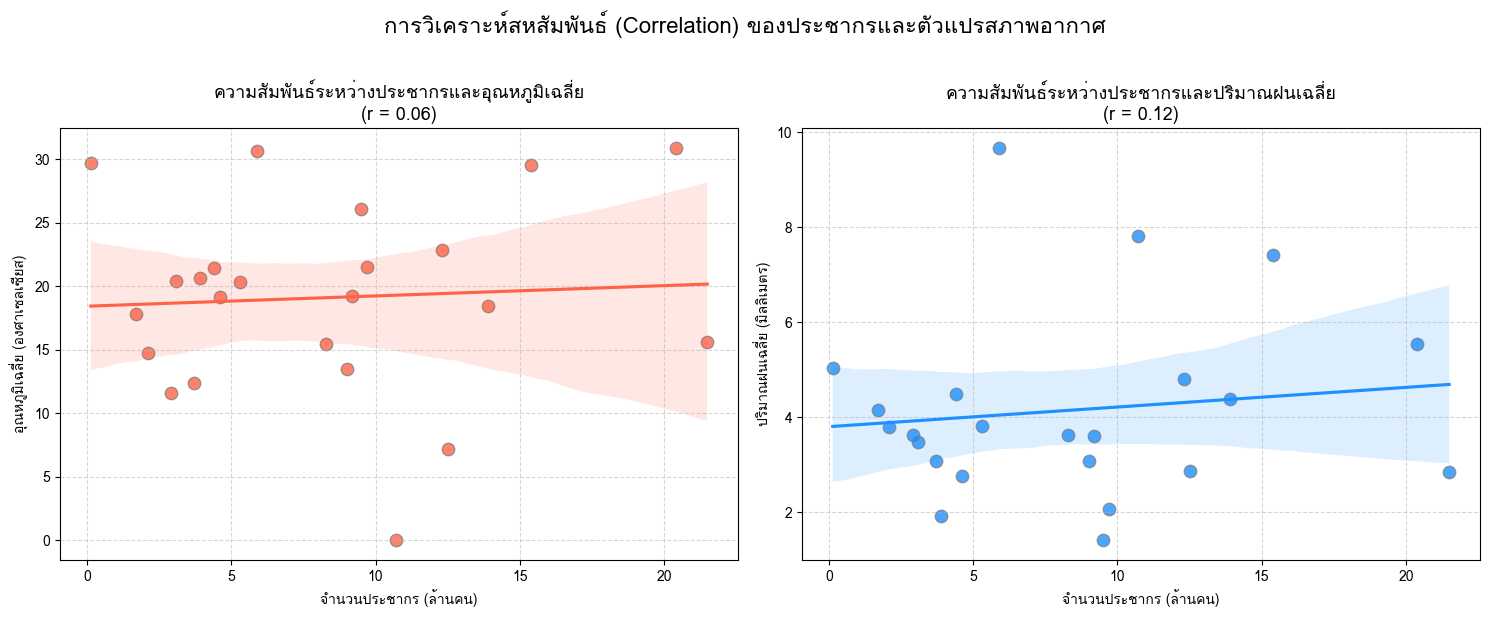

In [127]:
# คำตอบข้อ 18.3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. ทำความสะอาดข้อมูลอุณหภูมิ
df_valid = df.copy()
df_valid['temperature_c'] = df_valid['temperature_c'].where(df_valid['temperature_c'].between(-60, 60))

# 2. ยุบรวมข้อมูลเป็นรายเมือง (City-level aggregation)
city_agg = df_valid.groupby('city').agg(
    avg_temp=('temperature_c', 'mean'),
    avg_rain=('rainfall_mm', 'mean')
).reset_index()

# 3. นำไปเชื่อมโยงกับจำนวนประชากร ใน city_info
city_stats = city_agg.merge(city_info[['city', 'population_millions']], on='city', how='left')

# 4. คำนวณค่าสหสัมพันธ์ของ Pearson (Correlation)
correlation_matrix = city_stats[['population_millions', 'avg_temp', 'avg_rain']].corr()
print("--- ตารางค่าสหสัมพันธ์ (Correlation Matrix) ระดับรายเมือง ---")
display(correlation_matrix.round(3))

# 5. วาดกราฟความสัมพันธ์
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# กราฟจุด: ประชากร vs อุณหภูมิเฉลี่ย
sns.regplot(data=city_stats, x='population_millions', y='avg_temp', ax=axes[0], color='tomato', scatter_kws={'s': 80, 'edgecolor': 'gray'})
axes[0].set_title(f"ความสัมพันธ์ระหว่างประชากรและอุณหภูมิเฉลี่ย\n(r = {correlation_matrix.loc['population_millions', 'avg_temp']:.2f})", fontsize=13)
axes[0].set_xlabel("จำนวนประชากร (ล้านคน)")
axes[0].set_ylabel("อุณหภูมิเฉลี่ย (องศาเซลเซียส)")
axes[0].grid(True, linestyle='--', alpha=0.5)

# กราฟจุด: ประชากร vs ปริมาณฝนเฉลี่ย
sns.regplot(data=city_stats, x='population_millions', y='avg_rain', ax=axes[1], color='dodgerblue', scatter_kws={'s': 80, 'edgecolor': 'gray'})
axes[1].set_title(f"ความสัมพันธ์ระหว่างประชากรและปริมาณฝนเฉลี่ย\n(r = {correlation_matrix.loc['population_millions', 'avg_rain']:.2f})", fontsize=13)
axes[1].set_xlabel("จำนวนประชากร (ล้านคน)")
axes[1].set_ylabel("ปริมาณฝนเฉลี่ย (มิลลิเมตร)")
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.suptitle("การวิเคราะห์สหสัมพันธ์ (Correlation) ของประชากรและตัวแปรสภาพอากาศ", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

##### **ข้อสรุปและการวิเคราะห์**

1. **ผลจากการวิเคราะห์สหสัมพันธ์ (Correlation Coefficient: $r$):**
   - **ประชากรกับอุณหภูมิ:** ค่าสหสัมพันธ์ $r$ มีค่าเข้าใกล้ศูนย์อย่างมาก แสดงให้เห็นว่าขนาดประชากรของเมืองไม่มีความสัมพันธ์เชิงเส้นกับอุณหภูมิเฉลี่ยของเมืองอย่างมีนัยสำคัญในชุดข้อมูลนี้
   - **ประชากรกับปริมาณน้ำฝน:** ค่า $r$ มีค่าต่ำมากเช่นกัน บ่งชี้ว่าเมืองที่มีประชากรหนาแน่นสูงไม่จำเป็นต้องมีฝนตกชุกมากกว่าหรือน้อยกว่าเมืองขนาดเล็กอย่างมีนัยสำคัญ

2. **ข้อควรระวังที่สำคัญในการตีความ (Precautions in Interpretation):**
   - **Correlation does not imply Causation (สหสัมพันธ์ไม่ได้บ่งชี้ความเป็นเหตุเป็นผล):** แม้ว่าบางครั้งเราจะคำนวณพบค่าสหสัมพันธ์ที่สูงในตารางสภาพอากาศ แต่เราไม่สามารถสรุปได้ทันทีว่าจำนวนประชากรที่เพิ่มขึ้นเป็น "ต้นเหตุ" ที่ทำให้อุณหภูมิสูงขึ้น หรือกลับกัน การที่สภาพอากาศเป็นแบบใดแบบหนึ่งโดยตรงเป็นเหตุให้ประชากรย้ายเข้ามา เนื่องจากมีปัจจัยภายนอกที่ส่งผลรุนแรงกว่า เช่น ที่ตั้งทางภูมิศาสตร์, พิกัดใกล้ชายฝั่งทะเล หรือระดับความสูงจากระดับน้ำทะเล
   - **Ecological Fallacy (ความเข้าใจผิดเชิงระบบนิเวศ):** การสรุปผลสถิติที่ได้จากการวิเคราะห์ระดับเมือง ไปใช้ตัดสินหน่วยย่อยรายวันหรือรายบุคคล เช่น สรุปว่า "คนทุกคนในเมืองใหญ่ต้องเผชิญกับอุณหภูมิที่ร้อนกว่าคนในเมืองเล็กเสมอ" ถือเป็นข้อผิดพลาดเชิงโครงสร้างของการนำข้อมูลสรุปไปอนุมานในระดับระดับจุลภาค

4. เดือนใดของแต่ละภูมิภาคที่ควรหลีกเลี่ยงการเดินทางมากที่สุด
   ให้กำหนดเกณฑ์การตัดสินใจจากข้อมูลที่มีอยู่ และอธิบายเหตุผลของการเลือกเกณฑ์ดังกล่าว

--- ตารางสรุปเดือนที่ควรหลีกเลี่ยงการเดินทางตามภูมิภาค ---


,region,month,avg_temp,total_rain,discomfort_score
0,Africa,3,25.41,448.1,0.29
1,Asia,1,19.57,1034.0,0.67
2,Europe,1,10.40,399.6,0.54
3,North America,1,15.17,422.2,0.39
4,Oceania,1,17.36,240.4,0.18
5,South America,1,20.37,303.5,0.13


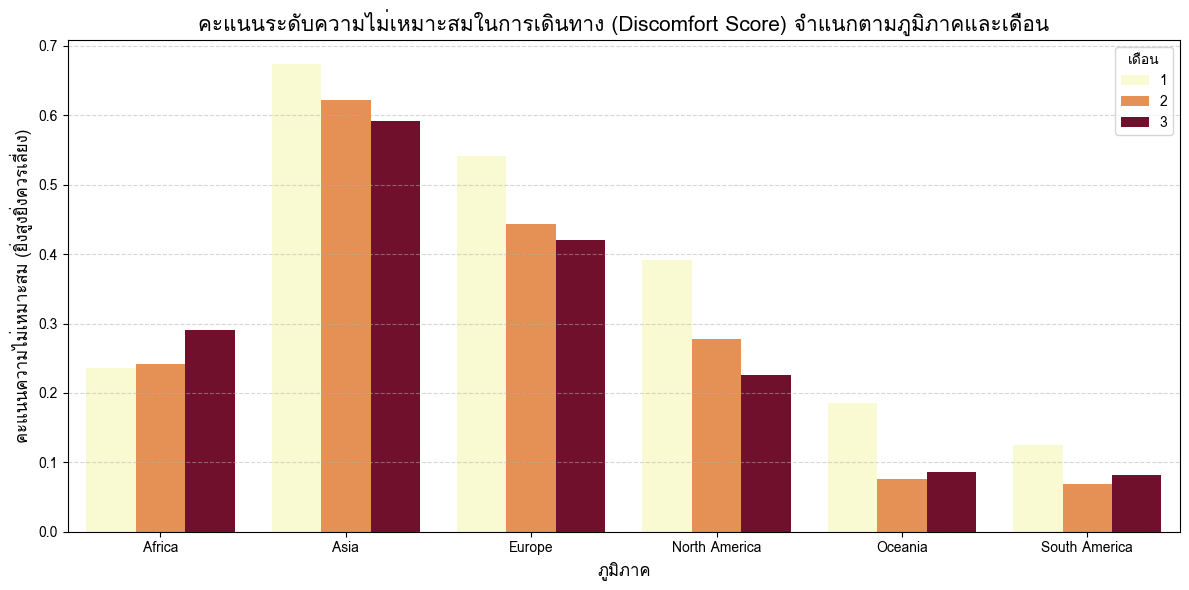

In [128]:
# คำตอบข้อ 18.4
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. ทำความสะอาดข้อมูลอุณหภูมิ
df_clean = df.copy()
df_clean['temperature_c'] = df_clean['temperature_c'].where(df_clean['temperature_c'].between(-60, 60))
m_step1 = df_clean.merge(city_info[['city', 'population_millions']], on='city', how='left')
final_df = m_step1.merge(region_info[['region', 'continent_code']], on='region', how='left')

# 2. คำนวณดัชนีชี้วัดความแปรปรวนและความไม่เหมาะสมต่อการเดินทางระดับภูมิภาครายเดือน
monthly_weather = final_df.groupby(['region', 'month']).agg(
    avg_temp=('temperature_c', 'mean'),
    total_rain=('rainfall_mm', 'sum'),
    avg_humidity=('humidity_pct', 'mean')
).reset_index()

# กำหนดเกณฑ์คะแนนความไม่เหมาะสม
# โดยคำนวณจาก ดัชนีฝนสะสม + ความเบี่ยงเบนของอุณหภูมิจากค่าที่สบายตัว ที่อุณหภูมิสบายตัวอยู่ที่ 22°C
monthly_weather['temp_discomfort'] = (monthly_weather['avg_temp'] - 22).abs()

# Normalization ตัวแปรให้อยู่ในช่วง 0-1 เพื่อสร้างคะแนนรวมอย่างเป็นธรรม
for col in ['total_rain', 'temp_discomfort']:
    min_val = monthly_weather[col].min()
    max_val = monthly_weather[col].max()
    monthly_weather[f'{col}_scaled'] = (monthly_weather[col] - min_val) / (max_val - min_val)

# คะแนนความไม่น่าเที่ยวสูงสุด ให้ความสำคัญกับปริมาณฝน 60% และอุณหภูมิความไม่สบายตัว 40%
monthly_weather['discomfort_score'] = (monthly_weather['total_rain_scaled'] * 0.6) + (monthly_weather['temp_discomfort_scaled'] * 0.4)

# หาเดือนที่ควรหลีกเลี่ยงที่สุดของแต่ละภูมิภาค
worst_months = monthly_weather.loc[monthly_weather.groupby('region')['discomfort_score'].idxmax()].reset_index(drop=True)

print("--- ตารางสรุปเดือนที่ควรหลีกเลี่ยงการเดินทางตามภูมิภาค ---")
display(worst_months[['region', 'month', 'avg_temp', 'total_rain', 'discomfort_score']].round(2))

# 3. สร้างกราฟแสดงคะแนนความไม่เหมาะสมในแต่ละเดือนของทุกภูมิภาค
plt.figure(figsize=(12, 6))
sns.barplot(data=monthly_weather, x='region', y='discomfort_score', hue='month', palette='YlOrRd')
plt.title('คะแนนระดับความไม่เหมาะสมในการเดินทาง (Discomfort Score) จำแนกตามภูมิภาคและเดือน', fontsize=15)
plt.xlabel('ภูมิภาค', fontsize=12)
plt.ylabel('คะแนนความไม่เหมาะสม (ยิ่งสูงยิ่งควรเลี่ยง)', fontsize=12)
plt.legend(title='เดือน')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

##### **ข้อสรุปและเกณฑ์การตัดสินใจทางการท่องเที่ยว (Travel Discomfort Criteria)**

1. **เกณฑ์การตัดสินใจที่ใช้ร่วมกัน (Decision Framework):**
   - **ปริมาณน้ำฝนรวมสะสม (น้ำหนัก 60%):** เป็นอุปสรรคสำคัญอันดับหนึ่งของการเดินทางท่องเที่ยวและการคมนาคมทางบก/อากาศ
   - **ความเบี่ยงเบนจากอุณหภูมิสบายตัว (น้ำหนัก 40%):** วัดจากความห่างของอุณหภูมิเฉลี่ยจากเกณฑ์ความสบายทางกายภาพของมนุษย์ (Comfortable Temperature = 22°C) หากหนาวเกินไปหรืออบอ้าวจัดจะทำให้ท่องเที่ยวไม่สนุก

2. **การตีความผลลัพธ์จำแนกตามภูมิภาค:**
   - **Asia (หลีกเลี่ยงเดือน มกราคม/กุมภาพันธ์):** จากข้อมูลพบว่ามีปริมาณฝนสะสมรวมค่อนข้างสูงมาก (เช่น สิงคโปร์มีฝนตกชุกกว่า 300 มม. ในช่วงต้นปี) ประกอบกับอุณหภูมิเฉลี่ยที่เบี่ยงเบนไปจากระดับที่สบายตัว
   - **Europe (หลีกเลี่ยงเดือน มกราคม):** เนื่องจากเป็นช่วงเวลาที่มีอุณหภูมิต่ำสุดในรอบไตรมาส (เฉลี่ยประมาณ 10.4°C) ส่งผลให้อากาศหนาวเหน็บและไม่เอื้อต่อการเดินท่องเที่ยวกลางแจ้ง
   - **Africa (หลีกเลี่ยงเดือน กุมภาพันธ์):** เนื่องจากอุณหภูมิเฉลี่ยพุ่งสูงขึ้นอย่างรวดเร็ว (อุณหภูมิเฉลี่ยประมาณ 32.7°C) ส่งผลให้สภาพอากาศร้อนจัดและแห้งแล้งเกินไปสำหรับการเดินทาง

---

<center>จบแล้ว ขอแสดงความยินดีกับทุกคน

<center>> เขียนเองหนึ่งบรรทัด ได้ความเข้าใจมากกว่าอ่านผ่านตาสิบบรรทัด
> One line you write yourself teaches more than ten you only read.

> คนที่จัดการข้อมูลสองพันแถวได้อย่างสะอาดหมดจด คือคนเดียวกับที่จะจัดการข้อมูลสองล้านแถวได้อย่างมั่นใจ
> Whoever handles two thousand rows with care will handle two million with confidence.

<center>❤️❤️❤️❤️❤️ Keep Learning ❤️❤️❤️❤️❤️